# ¿Cuánto aviso nos da un río? · 06 — Lluvia de la cuenca: ¿cuánto aporta al pronóstico del caudal?

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador

**Equipo:** 

- Luis Angel Cupe Espinoza
- Yely Lanasca Justiniano 
- Lia Kim Alcantara Tineo 
- Mayra Madelyn Marzano Mejia 
- María Fernanda Torres Carbajal 

**Protocolo:** común a todo el estudio (`comun.py` e `integrado.py`; identificado como `v4` en el código y en las salidas). La fecha de ejecución y las versiones de software se imprimen en la celda de configuración.

**Lugar en el estudio:** este cuaderno responde la pregunta **P4**: cuánto aporta la **lluvia media de la cuenca** (PISCOp v2.1) y sus **índices antecedentes** al pronóstico del caudal, según su disponibilidad al emitir, con los **seis modelos** del estudio: Q, Q+P, Q+P+IA, sus versiones con un día de retraso y el control de representación Q+Pd. La **lluvia futura observada** se evalúa aparte, como escenario idealizado (sección 10, con XGBoost y regresión lineal, los dos modelos con estimador por horizonte), y no participa en ninguna selección. Las estaciones aguas arriba se estudian en el 05 y Chronos-2 en el 07; la comparación integrada y la selección final del proyecto están en el **08**.

**Sobre el periodo de prueba:** las reglas de selección y de evaluación se fijaron antes de la evaluación final (sección 0.3), pero el periodo de prueba se consultó durante el desarrollo del proyecto, y la forma de la lluvia (log(1 + P), 7 días y 3 sumas) se decidió después de explorar los datos: no es una prueba ciega.

---

## 0. Objetivo y decisiones de diseño

### 0.1 Pregunta
> **¿Cuánto mejora el pronóstico diario del caudal, y su anticipación de crecidas, si además del caudal pasado se usa la lluvia de la cuenca? ¿Depende de qué día se conoce la lluvia y de qué modelo la usa?**

### 0.2 Fuente de la lluvia y supuestos (fijados antes de ejecutar)
- **Lluvia media de la cuenca** de CAMELS-PE v1.0.1 (columna `prec`, PISCOp v2.1: pluviómetros del SENAMHI combinados con satélite), en mm/d, 1981–2025, sin vacíos en las dos cuencas.
- **Disponibilidad:** el escenario principal supone que la lluvia del día de emisión t se conoce al emitir (**disponibilidad supuesta**: PISCOp no se publica a tiempo y CAMELS-PE no informa la hora de corte del acumulado). Por eso cada configuración con lluvia se evalúa también con la lluvia **hasta t−1**.
- **Lluvia futura** (t+1 … t+h): solo como **escenario idealizado** (un pronóstico de lluvia sin error), aparte de toda selección.
- No se usan humedad del suelo, lluvia espacial ni pronósticos meteorológicos.

### 0.3 Protocolo del experimento (fijado antes de ejecutar)
| Paso | Decisión |
|---|---|
| Estaciones y filas | Racarumi y Tamshiyacu, emisiones de los modelos base (01–02) con 91 días de lluvia previos (`entradas.DISENO_LLUVIA`): todas las configuraciones se ajustan, validan y prueban en **las mismas filas**. |
| Configuraciones | **Q** (caudal de 30 días y calendario, como en los modelos base); **Q+P** (lluvia hasta t: 7 días y las sumas t−7…14, t−15…29 y t−30…89, en log(1 + P)); **Q+P+IA** (además, IPA con k = 0.90 y 0.97 y días secos); **Q+P (t−1)** y **Q+P+IA (t−1)** (todo desplazado un día); **Q+Pd (control)**, solo en Racarumi: la lluvia con el mismo contenido diario que recibe la LSTM, para separar la representación del algoritmo; **no** compite en las selecciones. |
| Modelos | Los seis modelos del estudio con sus mallas, semillas y estrategias (`entradas.ajustar`, caché con identidad completa). Cada familia recibe la lluvia con su representación (sección 4.2). |
| División | Entrenamiento hasta 2008; validación 2009–2015 (Duan 2009–2011, selección 2012–2015); prueba 2016–fin; la LSTM detiene con 2005–2008. |
| Selección para la magnitud | En 2012–2015 con la regla de selección del estudio (mayor NSE medio; IC 90 % por bootstrap pareado de meses; la más simple entre el mejor y sus equivalentes: menos fuentes y, después, el modelo más simple), por escenario de disponibilidad: **mismo día** (Q, Q+P, Q+P+IA) y **un día de retraso** (Q, Q+P (t−1), Q+P+IA (t−1)). |
| Selección para avisos | Racarumi, reglas del cuaderno 04 y protocolo común (`comun.seleccion_avisos`): regla de cada candidato calibrada en 2009–2011, comparación en 2012–2015 (mayor CSI con FAR ≤ 0.5), regla final recalibrada en toda la validación. Tamshiyacu: solo conteo de cruces (3 en la prueba). |
| Prueba | Sin cambiar las selecciones: NSE por horizonte, horizonte útil (cota 95 %), ganancias por bandas con IC 90 %, caudales altos, avisos con IC de Wilson, omisiones y anticipación. Climatología de referencia hasta 2015. |

### 0.4 Hipótesis de este cuaderno
- **HL1:** el caudal responde a la lluvia con un desfase de máxima asociación ≥ 1 día (sección 3.2).
- **HL2:** con la lluvia hasta t el error baja en los primeros días, con todos los modelos.
- **HL3:** la ganancia se concentra en los horizontes cercanos al tiempo de respuesta de cada cuenca.
- **HL4:** con la lluvia futura conocida (idealizado) el horizonte útil y la anticipación crecen mucho (sección 10).

---
## 1. Configuración
Librerías, semillas y rutas relativas. Las funciones de datos, métricas, modelos y avisos son las de `comun.py`. `lluvia.py` agrega la carga de la lluvia, sus variables y el análisis de la respuesta del caudal; `entradas.py`, las entradas de cada configuración y el ajuste de los seis modelos con caché; `integrado.py`, el protocolo común de comparación (validación, selección, prueba y avisos) que comparten 05, 06 y 08.

In [1]:
import os, sys, json, time, warnings, platform
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import sklearn, xgboost

import comun as C
import aguas_arriba as A
import lluvia as LL
import entradas as EN
import integrado as I

%matplotlib inline
warnings.filterwarnings('ignore')
np.random.seed(C.SEMILLA)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

RAPIDO = os.environ.get('CDA_RAPIDO') == '1'          # solo para probar el código: mallas mínimas, una semilla
if RAPIDO:
    C.MALLAS = {k: {kk: vv[:1] for kk, vv in v.items()} for k, v in C.MALLAS.items()}
    C.SEMILLAS = C.SEMILLAS[:1]
B = 50 if RAPIDO else 1000
AV = C.AVISO

RUTA_SAL = C.ruta_salidas() / 'lluvia'          # modo rápido: salidas_rapido/ (nunca se mezcla con la ejecución final)
PREVIAS = {k: C.verificar_resumen(C.ruta_salidas() / k / 'resumen.json') for k in ['racarumi', 'tamshiyacu', 'anticipacion']}
RUTA_FIG, RUTA_TAB = RUTA_SAL / 'figuras', RUTA_SAL / 'tablas'
for r in (RUTA_FIG, RUTA_TAB):
    r.mkdir(parents=True, exist_ok=True)

EST = ['Racarumi', 'Tamshiyacu']
L, H = C.L_VENTANA, len(C.HORIZONTES)
MODELOS_LL = ['XGBoost', 'Regresión lineal']          # solo para el escenario idealizado (sección 10)
MODELOS = I.MODELOS
BASE, OBS, TECHO = LL.ESC_BASE, LL.ESC_OBS, LL.ESC_FUT     # etiquetas únicas (lluvia.py)
LAT = LL.ESC_LAT
VARIANTES = [BASE, OBS, TECHO]
COMPARACIONES = [(OBS, BASE), (TECHO, BASE), (TECHO, OBS)]   # escenario idealizado (sección 10)
COLV = {BASE: '#444444', OBS: '#1f77b4', TECHO: '#d62728'}
COLE = {'Racarumi': '#e07b00', 'Tamshiyacu': '#1f5fa8'}
H_CLAVE = {'Racarumi': [1, 2, 3, 5, 7, 15, 30], 'Tamshiyacu': [1, 3, 7, 15, 20, 30]}
FUENTE = 'Fuente: CAMELS-PE v1.0.1 (SENAMHI): caudal observado depurado del EDA y lluvia PISCOp v2.1'
T_INICIO = time.time()

print(f"Ejecución: {datetime.now():%Y-%m-%d %H:%M} | Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")
print(f"Protocolo {C.VERSION} | RAPIDO = {RAPIDO} | B = {B} | semillas = {C.SEMILLAS}")

Ejecución: 2026-11-22 19:23 | Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.1.2
Protocolo v4 | RAPIDO = False | B = 1000 | semillas = [42, 43, 44]


---
## 2. Datos
Caudal observado depurado (reglas del EDA) y lluvia media de la cuenca de cada estación. ε, los escalones de nivel y el P95 se fijan **con el entrenamiento** (hasta 2008); las muestras son las de los modelos base (01–02), con las variables de lluvia de cada fecha de emisión, y se comprueba que la lluvia antecedente termina en el día t y que la futura empieza en t + 1.
**Por qué:** todas las configuraciones deben usar las mismas filas; la única diferencia debe ser la información de entrada. Estas filas se comparan en la sección 4 con las del diseño de los seis modelos.

In [2]:
D, filas_inv = {}, []
for e in EST:
    q, info = C.cargar_serie(e)
    eps, esc = C.eps_entrenamiento(q), C.escalones(q)
    P = LL.cargar_lluvia(e)
    p95 = float(np.nanpercentile(q.loc[:C.FIN_ENTRENAMIENTO], 95))
    m_tot = C.construir_muestras(q, L=L, H=H, esc=esc, eps=eps)
    p_tot = C.particion(m_tot)
    Xll, nom_ll, ok_ll = LL.matriz_lluvia(P, m_tot.fechas)
    F, ok_f = LL.matriz_futura(P, m_tot.fechas, H)
    assert np.allclose(Xll[ok_ll, 0], np.log1p(P.reindex(m_tot.fechas[ok_ll]).to_numpy())), 'la lluvia antecedente debe terminar en t'
    assert np.allclose(Xll[ok_ll, 1], np.log1p(P.reindex(m_tot.fechas[ok_ll] - pd.Timedelta(days=1)).to_numpy()))
    assert np.allclose(F[ok_f, 0], P.reindex(m_tot.fechas[ok_f] + pd.Timedelta(days=1)).to_numpy()), 'la lluvia futura empieza en t + 1'
    ok_ll1 = LL.matriz_lluvia(P, m_tot.fechas, desfase=1)[2]           # la sensibilidad de la sección 8 usa las mismas filas
    SEL = np.where(ok_ll & ok_ll1 & ok_f)[0]
    m = A.subconjunto(m_tot, SEL)
    p = C.particion(m)
    VC = C.ValidacionCausal(m, p['val'])
    D[e] = dict(q=q, info=info, eps=eps, esc=esc, P=P, P95=p95, m=m, p=p, VC=VC, Xll=Xll[SEL], nom_ll=nom_ll, F=F[SEL], p_tot=p_tot)
    Pa = P.loc[:'2025-12-31']
    filas_inv.append({'estación': e, 'área (km²)': info['area'], 'caudal observado': f"{info['inicio']:%Y-%m-%d} a {info['fin']:%Y-%m-%d}",
                      'vacíos de caudal (%)': info['vacios'], 'lluvia': f"{P.first_valid_index():%Y-%m-%d} a {P.last_valid_index():%Y-%m-%d}",
                      'vacíos de lluvia (%)': float(P.isna().mean() * 100), 'lluvia media (mm/año)': float(Pa.mean() * 365.25),
                      'P95 de entrenamiento (m³/s)': p95, 'ε (m³/s)': eps,
                      'emisiones v4 (ent / val / prueba)': f"{len(p_tot['ent'])} / {len(p_tot['val'])} / {len(p_tot['pru'])}",
                      'emisiones del experimento (ent / val / prueba)': f"{len(p['ent'])} / {len(p['val'])} / {len(p['pru'])}",
                      'prueba': f"{m.fechas[p['pru']].min():%Y-%m-%d} a {m.fechas[p['pru']].max():%Y-%m-%d}"})
inv = pd.DataFrame(filas_inv).set_index('estación')
inv.to_csv(RUTA_TAB / 'tabla_inventario.csv')
inv.T

estación,Racarumi,Tamshiyacu
área (km²),2363.302,719664.668
caudal observado,1981-01-01 a 2023-08-31,1984-09-01 a 2025-12-31
vacíos de caudal (%),0.417121,0.457044
lluvia,1981-01-01 a 2025-12-31,1981-01-01 a 2025-12-31
vacíos de lluvia (%),0.0,0.0
lluvia media (mm/año),1120.172016,2553.883445
P95 de entrenamiento (m³/s),111.206489,47602.819185
ε (m³/s),0.339298,301.461247
emisiones v4 (ent / val / prueba),9308 / 2371 / 2521,6904 / 2025 / 3252
emisiones del experimento (ent / val / prueba),9247 / 2371 / 2521,6904 / 2025 / 3252


**Interpretación:**
- **La lluvia está completa:** CAMELS-PE trae la lluvia PISCOp de 1981 a 2025 sin vacíos en las dos cuencas, así que no quita ninguna emisión de la prueba ni de la validación.
- **Mismas filas que los modelos base:** en Tamshiyacu el experimento usa exactamente las emisiones del cuaderno 02 (6 904 / 2 025 / 3 252). En Racarumi se pierden solo 61 emisiones de entrenamiento de 1981 (las que no tienen 91 días de lluvia previa); validación y prueba quedan iguales.
- **Escala:** Racarumi recibe ~1 120 mm/año sobre 2 363 km²; Tamshiyacu, ~2 550 mm/año sobre ~720 000 km².

---
## 3. Relación lluvia-escorrentía
### 3.1 Régimen y balance
Régimen mensual de la lluvia y del caudal, coeficiente de escorrentía por año hidrológico (septiembre–agosto, con ≥ 330 días de caudal) Q/P (lámina escurrida / lluvia) y cuántos meses va el régimen del caudal detrás del de la lluvia (correlación entre las dos climatologías mensuales con la lluvia desplazada 0–4 meses).
**Por qué:** antes de usar la lluvia como entrada conviene comprobar que es coherente con el caudal (Q/P entre 0 y 1, estable en el tiempo) y conocer la escala de tiempo de la respuesta.

In [3]:
sig = pd.read_csv(C.asegurar_camels() / '02_attributes' / 'hydrological_signatures.csv').set_index('gauge_id')
MESES = ['E', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']
BAL, DES, REG, filas_b = {}, {}, {}, []
for e in EST:
    d = D[e]
    BAL[e] = LL.balance_anual(d['P'], d['q'], d['info']['area'])
    DES[e] = LL.desfase_estacional(d['P'], d['q'])
    pm = d['P'].groupby(d['P'].index.month).mean() * 30.44
    qm = d['q'].groupby(d['q'].index.month).mean()
    REG[e] = pd.DataFrame({'lluvia (mm/mes)': pm, 'caudal (m³/s)': qm})
    b = BAL[e]
    filas_b.append({'estación': e, 'años hidrológicos': len(b), 'lluvia media (mm/año)': b['lluvia (mm)'].mean(),
                    'escorrentía media (mm/año)': b['escorrentía (mm)'].mean(), 'Q/P medio': b['Q/P'].mean(),
                    'Q/P mínimo': b['Q/P'].min(), 'Q/P máximo': b['Q/P'].max(), 'años con Q/P > 1': int((b['Q/P'] > 1).sum()),
                    'runoff_ratio de CAMELS-PE': float(sig.loc[C.ESTACIONES[e]['gid'], 'runoff_ratio']),
                    'mes más lluvioso': int(pm.idxmax()), 'mes de mayor caudal': int(qm.idxmax()),
                    'desfase estacional (meses)': int(DES[e]['r'].idxmax()), 'r del desfase': float(DES[e]['r'].max())})
    b.to_csv(RUTA_TAB / f'tabla_balance_anual_{e.lower()}.csv')
bal = pd.DataFrame(filas_b).set_index('estación')
bal.to_csv(RUTA_TAB / 'tabla_balance.csv')
bal.T.round(3)

estación,Racarumi,Tamshiyacu
años hidrológicos,42.000,41.000
lluvia media (mm/año),1111.930,2500.380
escorrentía media (mm/año),476.704,1316.782
Q/P medio,0.435,0.538
Q/P mínimo,0.288,0.336
Q/P máximo,0.562,0.761
años con Q/P > 1,0.000,0.000
runoff_ratio de CAMELS-PE,0.428,0.515
mes más lluvioso,3.000,2.000
mes de mayor caudal,3.000,4.000


**Interpretación:**
- **La lluvia es coherente con el caudal:** el coeficiente de escorrentía medio es 0.43 en Racarumi y 0.54 en Tamshiyacu, casi igual al `runoff_ratio` que publica CAMELS-PE (0.43 y 0.52). Ningún año supera Q/P = 1, que sería físicamente imposible sin aportes externos.
- **Varía de año a año:** 0.29–0.56 en Racarumi y 0.34–0.76 en Tamshiyacu. Es decir, la misma lluvia no siempre produce el mismo caudal; la humedad del suelo y la distribución de la lluvia importan.
- **Escala de tiempo:** en Racarumi la lluvia y el caudal tienen su máximo en marzo, y el caudal va como 1 mes detrás en la bajada. En Tamshiyacu la lluvia es máxima en febrero y el caudal en abril: **2 meses de desfase** (r = 0.98). Es la primera pista de que las dos cuencas responden a escalas muy distintas.

**Figura 1.** (a, b) Régimen mensual de la lluvia de la cuenca (barras) y del caudal (línea); (c, d) coeficiente de escorrentía Q/P por año hidrológico.

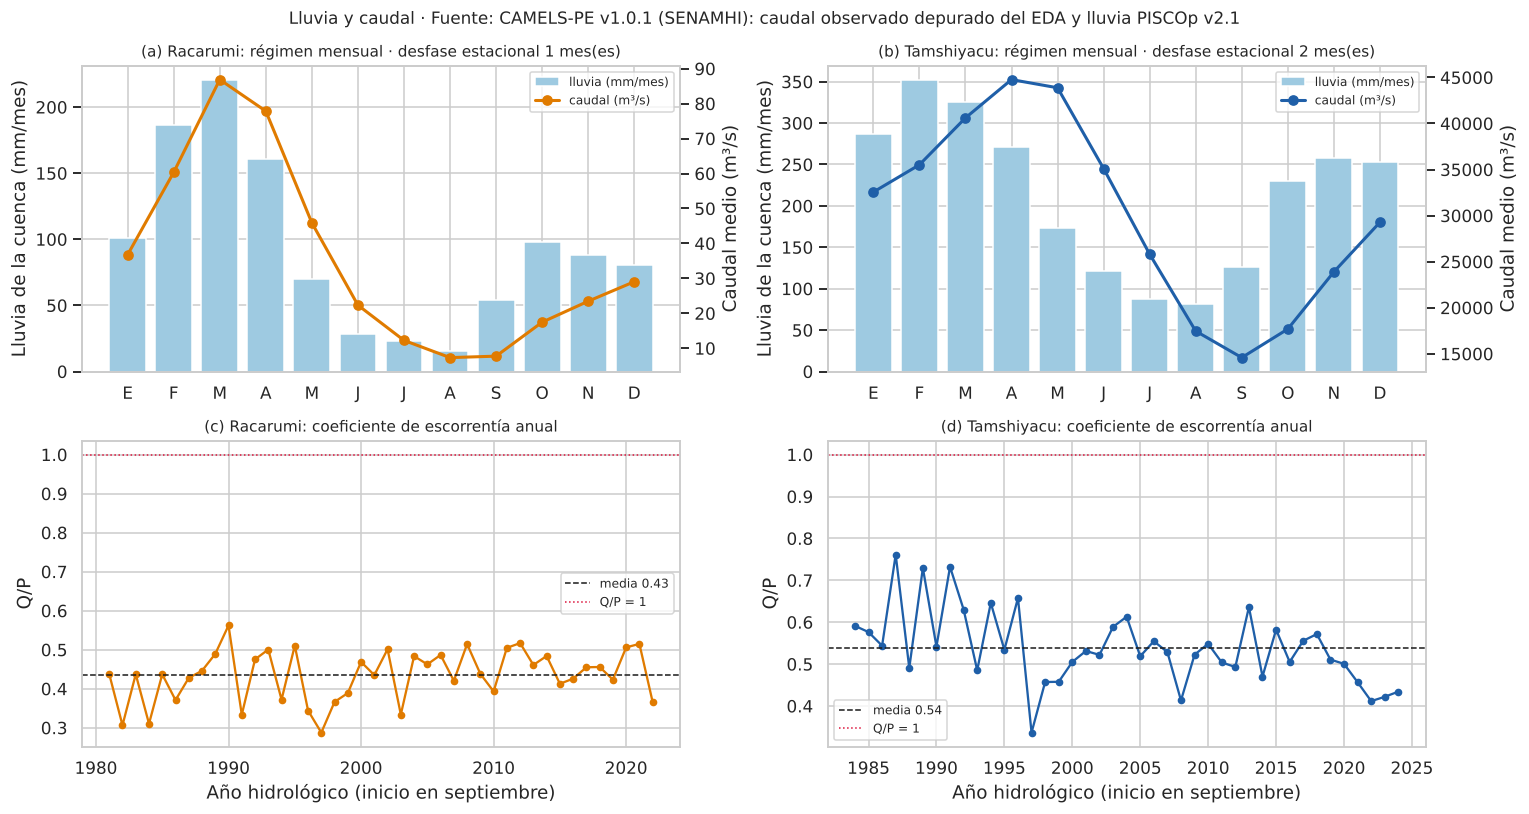

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(14, 7.5))
for j, e in enumerate(EST):
    r = REG[e]
    a = ax[0, j]
    a.bar(range(1, 13), r['lluvia (mm/mes)'], color='#9ecae1', label='lluvia (mm/mes)')
    a.set_xticks(range(1, 13)); a.set_xticklabels(MESES); a.set_ylabel('Lluvia de la cuenca (mm/mes)')
    a2 = a.twinx(); a2.plot(range(1, 13), r['caudal (m³/s)'], 'o-', color=COLE[e], lw=2, label='caudal (m³/s)'); a2.set_ylabel('Caudal medio (m³/s)')
    a2.grid(False)
    a.set_title(f"({'ab'[j]}) {e}: régimen mensual · desfase estacional {bal.loc[e, 'desfase estacional (meses)']} mes(es)", fontsize=10)
    h1, l1 = a.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); a.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper right')
    b = BAL[e]
    x = [int(s[:4]) for s in b.index]
    ax[1, j].plot(x, b['Q/P'], 'o-', color=COLE[e], ms=4)
    ax[1, j].axhline(b['Q/P'].mean(), color='k', ls='--', lw=1, label=f"media {b['Q/P'].mean():.2f}")
    ax[1, j].axhline(1, color='crimson', ls=':', lw=1, label='Q/P = 1')
    ax[1, j].set_xlabel('Año hidrológico (inicio en septiembre)'); ax[1, j].set_ylabel('Q/P'); ax[1, j].legend(fontsize=8)
    ax[1, j].set_title(f"({'cd'[j]}) {e}: coeficiente de escorrentía anual", fontsize=10)
fig.suptitle('Lluvia y caudal · ' + FUENTE, fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig01_regimen_balance.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:**
- **(a) Racarumi:** el río sube y baja casi al mismo ritmo que la lluvia; en estiaje (junio–septiembre) casi no llueve y el caudal baja a menos de 10 m³/s.
- **(b) Tamshiyacu:** el caudal sigue subiendo en marzo–abril aunque la lluvia ya bajó: el agua de toda la Amazonía peruana tarda semanas en llegar.
- **(c, d)** El coeficiente anual oscila alrededor de su media sin una tendencia clara. En Tamshiyacu hay más variación antes de 2000 y una caída en 1997–1998 y en 2021–2024; con estos datos no se puede saber si es un cambio del río o del producto de lluvia.

### 3.2 Desfase de máxima asociación lluvia–caudal (HL1)
**Desfase lluvia–caudal:** correlación cruzada entre la lluvia de la cuenca en t − k y la variación diaria del caudal Δlog(Q + ε) en t, para k = −3 … 20 días. La lluvia se **preblanquea** con un AR(p) (p por AIC) ajustado en el entrenamiento y se aplica el mismo filtro al caudal; los días de escalón de nivel se descartan. Se repite con el AR ajustado en 2016–2025 y se muestra la correlación sin preblanquear.
**Por qué:** el desfase del máximo **sugiere** cuántos días tarda la lluvia en reflejarse en la estación (tiempo de respuesta aproximado; la resolución diaria y la hora de corte del acumulado también lo afectan). Si el máximo está en k ≥ 1, la lluvia observada hasta t anticipa el caudal de los días siguientes (HL1). k < 0 (la lluvia "después" del caudal) no debería tener correlación; si la tuviera, indicaría un problema de fechas.

In [5]:
DESF = range(-3, 21)
CCF, filas_r = {}, []
for e in EST:
    d = D[e]
    for et, aj in [('AR de entrenamiento', (f"{d['q'].index.min():%Y-%m-%d}", C.FIN_ENTRENAMIENTO)), ('AR de 2016–2025', ('2016-01-01', '2025-12-31'))]:
        t = LL.ccf_lluvia(d['P'], d['q'], d['eps'], DESF, ajuste=aj, excluir=d['esc'])
        CCF[(e, et)] = t
        k = int(t['r'].idxmax())
        filas_r.append({'estación': e, 'preblanqueo': et, 'orden AR': t.attrs['orden_AR'], 'desfase del máximo (d)': k, 'r máximo': float(t['r'].max()),
                        **{f'r a k = {j}': float(t.loc[j, 'r']) for j in (-1, 0, 1, 2, 3, 7)},
                        'desfase del máximo sin preblanquear (d)': int(t['r_simple'].idxmax()), 'pares': int(t.loc[0, 'n'])})
resp = pd.DataFrame(filas_r).set_index(['estación', 'preblanqueo'])
resp.to_csv(RUTA_TAB / 'tabla_respuesta_ccf.csv')
resp.round(3)

orden AR  desfase del máximo (d)  r máximo  \
estación   preblanqueo                                                       
Racarumi   AR de entrenamiento        10                       1     0.479   
           AR de 2016–2025            10                       1     0.470   
Tamshiyacu AR de entrenamiento        10                       6     0.125   
           AR de 2016–2025            10                       6     0.130   

                                r a k = -1  r a k = 0  r a k = 1  r a k = 2  \
estación   preblanqueo                                                        
Racarumi   AR de entrenamiento      -0.006      0.080      0.479     -0.149   
           AR de 2016–2025           0.018      0.063      0.470     -0.151   
Tamshiyacu AR de entrenamiento      -0.001      0.014      0.025      0.019   
           AR de 2016–2025           0.003      0.016      0.027      0.025   

                                r a k = 3  r a k = 7  \
estación   preblanqueo                                 
Racarumi   AR de entrenamiento     -0.126     -0.024   
           AR de 2016–2025         -0.097     -0.002   
Tamshiyacu AR de entrenamiento      0.006      0.122   
           AR de 2016–2025          0.019      0.128   

                                desfase del máximo sin preblanquear (d)  pares  
estación   preblanqueo                                                          
Racarumi   AR de entrenamiento                                        1  15086  
           AR de 2016–2025                                            1  15086  
Tamshiyacu AR de entrenamiento                                        6  14347  
           AR de 2016–2025                                            6  14347

**Interpretación:** **HL1 se cumple en las dos cuencas, pero a escalas muy distintas.**
- **Racarumi responde en 1 día:** la correlación preblanqueada es máxima en k = 1 (r = 0.48, igual con los dos periodos de ajuste del AR) y casi nula el mismo día (k = 0, r = 0.08). La lluvia de hoy se nota en el caudal de **mañana**.
  - Los valores negativos en k = 2–3 son la bajada después de la subida: el río vuelve a su nivel.
- **Tamshiyacu responde en ~6–7 días:** el máximo está en k = 6 (r = 0.13). La correlación es baja porque la lluvia de un día sobre 720 000 km² es una señal muy pequeña frente al caudal acumulado del Amazonas.
- **No hay correlación con k < 0** (lluvia "después" del caudal) en ninguna estación: las fechas de la lluvia y del caudal están bien alineadas.

**Figura 2.** Correlación cruzada entre la lluvia de la cuenca en t − k y la variación diaria del caudal en t: sin preblanquear (gris) y preblanqueada (color). k > 0: la lluvia se adelanta al caudal.

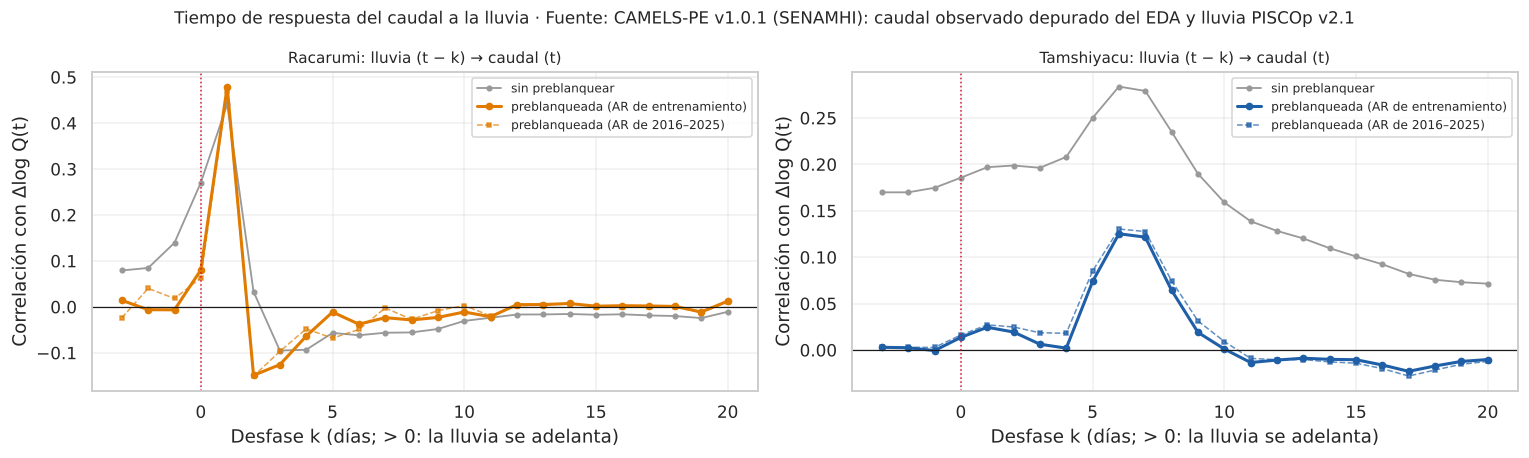

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, e in zip(ax, EST):
    t1, t2 = CCF[(e, 'AR de entrenamiento')], CCF[(e, 'AR de 2016–2025')]
    a.plot(t1.index, t1['r_simple'], 'o-', color='0.6', lw=1.2, ms=3, label='sin preblanquear')
    a.plot(t1.index, t1['r'], 'o-', color=COLE[e], lw=2, ms=4, label='preblanqueada (AR de entrenamiento)')
    a.plot(t2.index, t2['r'], 's--', color=COLE[e], lw=1, ms=3, alpha=0.7, label='preblanqueada (AR de 2016–2025)')
    a.axhline(0, color='k', lw=0.8); a.axvline(0, color='crimson', ls=':', lw=1)
    a.set_xlabel('Desfase k (días; > 0: la lluvia se adelanta)'); a.set_ylabel('Correlación con Δlog Q(t)')
    a.set_title(f'{e}: lluvia (t − k) → caudal (t)', fontsize=10); a.legend(fontsize=8); a.grid(True, alpha=0.3)
fig.suptitle('Tiempo de respuesta del caudal a la lluvia · ' + FUENTE, fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig02_respuesta_ccf.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:**
- **Racarumi (izquierda):** un pico muy marcado en k = 1. Sin preblanquear, el pico está en el mismo lugar, pero la curva se ensancha por la memoria de la lluvia (días lluviosos seguidos).
- **Tamshiyacu (derecha):** sin preblanquear, la correlación es positiva en todos los desfases (lluvia y caudal comparten la temporada). Preblanqueada, solo queda un pico entre 5 y 8 días: es la llegada de la lluvia a la estación.

### 3.3 Crecidas de Racarumi y la lluvia que las precede
Para cada evento sobre el P95 de entrenamiento en Racarumi (eventos separados por ≥ 7 días bajo el umbral, como en el cuaderno 04) se busca el día más lluvioso de los 7 días previos al pico (incluido) y se mide el desfase pico − lluvia máxima. Es descriptivo (todo el registro).
**Por qué:** la correlación de 3.2 promedia todos los días; aquí se mira solo lo que importa para los avisos: las crecidas.

In [7]:
dR = D['Racarumi']
RC = LL.respuesta_crecidas(dR['P'], dR['q'], dR['P95'], ventana=7)
RC.to_csv(RUTA_TAB / 'tabla_respuesta_crecidas_racarumi.csv', index=False)
des = RC['desfase pico − lluvia máxima (d)']
print(f"Eventos sobre el P95 ({dR['P95']:.1f} m³/s): {len(RC)} | desfase pico − lluvia máxima: mediana {des.median():.0f} d, "
      f"P25–P75 {des.quantile(0.25):.0f}–{des.quantile(0.75):.0f} d")
display(des.value_counts().sort_index().rename('eventos').to_frame().T)
RC.sort_values('Q pico (m³/s)', ascending=False).head(10).round(1)

Eventos sobre el P95 (111.2 m³/s): 142 | desfase pico − lluvia máxima: mediana 1 d, P25–P75 1–2 d


desfase pico − lluvia máxima (d),0,1,2,3,4,5,6
eventos,10,70,31,15,4,6,6


,inicio,pico,Q pico (m³/s),lluvia máxima (mm/d),fecha lluvia máxima,lluvia 7 d previos (mm),desfase pico − lluvia máxima (d)
134,2022-02-26,2022-03-03,396.5,39.8,2022-03-02,139.9,1
138,2023-03-07,2023-03-10,379.2,61.9,2023-03-09,210.4,1
84,2009-03-12,2009-03-26,357.4,32.3,2009-03-22,136.0,4
79,2008-03-20,2008-04-02,347.2,37.6,2008-04-01,152.4,1
126,2021-03-05,2021-03-10,338.1,46.1,2021-03-09,149.3,1
95,2012-03-18,2012-03-19,327.5,37.6,2012-03-18,116.8,1
35,1993-03-18,1993-03-24,322.2,29.7,1993-03-23,118.9,1
52,1998-03-23,1998-03-31,313.7,28.9,1998-03-28,126.7,3
111,2017-03-08,2017-03-13,308.6,32.1,2017-03-12,142.3,1
94,2012-01-09,2012-02-10,303.0,31.3,2012-02-09,137.8,1


**Interpretación:**
- **El pico llega 1 día después del día más lluvioso** en la mitad de las 142 crecidas (mediana 1 día; la mitad central, entre 1 y 2 días). Solo 10 crecidas tienen el pico el mismo día de la lluvia máxima y 16 tardan 4–6 días.
- **Las mayores crecidas** (2022, 2023, 2021, 2017) siguen el mismo patrón: un día de 30–62 mm de lluvia en la cuenca y el pico al día siguiente.
- **Lectura para los avisos:** si se conoce la lluvia del día, se puede anticipar la mayoría de las crecidas con **1 día** de aviso, y rara vez más.

**Figura 3.** (a) Desfase entre el pico de cada crecida de Racarumi y el día más lluvioso de los 7 días previos; (b) Racarumi en el verano de 2017 (El Niño costero); (c) Tamshiyacu en el año hidrológico 2011–2012, con la lluvia acumulada en 30 días.

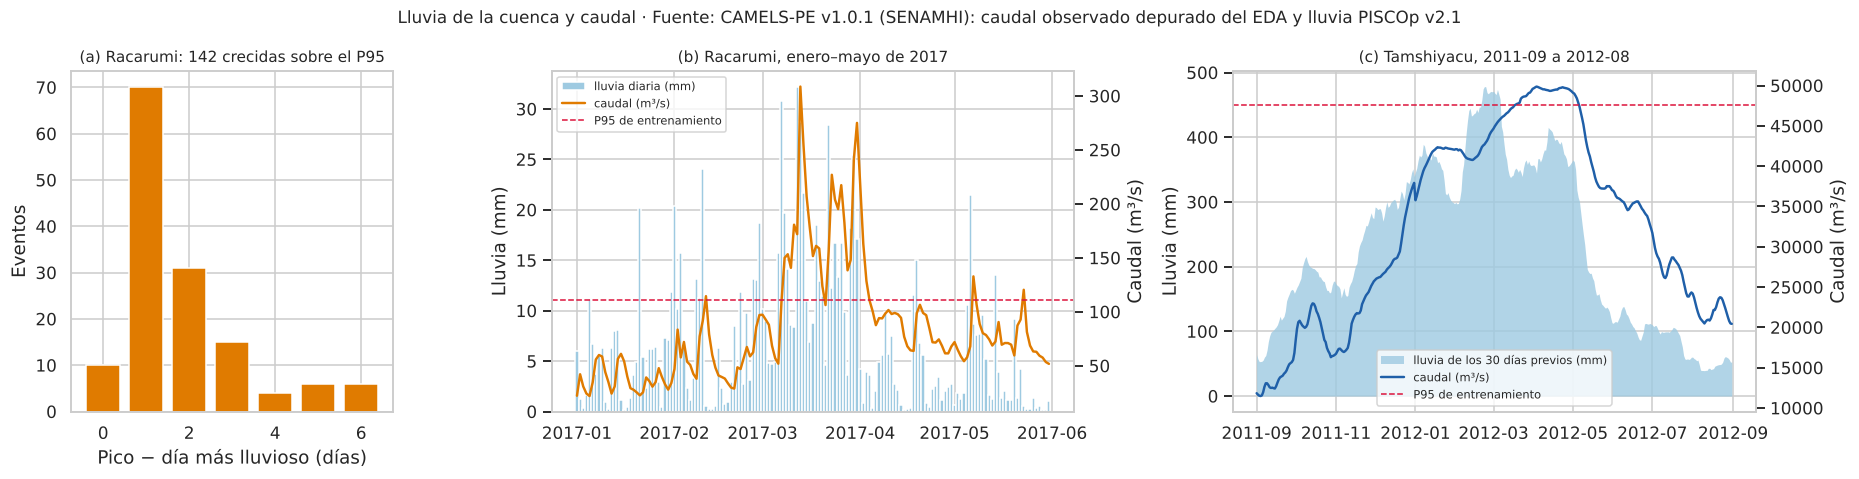

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={'width_ratios': [0.8, 1.3, 1.3]})
vc = des.value_counts().sort_index()
ax[0].bar(vc.index, vc.values, color=COLE['Racarumi'])
ax[0].set_xlabel('Pico − día más lluvioso (días)'); ax[0].set_ylabel('Eventos'); ax[0].set_title(f'(a) Racarumi: {len(RC)} crecidas sobre el P95', fontsize=10)
for a, e, d0, d1, acum, et in [(ax[1], 'Racarumi', '2017-01-01', '2017-05-31', 1, '(b) Racarumi, enero–mayo de 2017'),
                               (ax[2], 'Tamshiyacu', '2011-09-01', '2012-08-31', 30, '(c) Tamshiyacu, 2011-09 a 2012-08')]:
    d = D[e]
    if acum == 1:
        pp = d['P'].loc[d0:d1]
        a.bar(pp.index, pp, width=1.0, color='#9ecae1', label='lluvia diaria (mm)')
    else:
        pp = d['P'].rolling(acum).sum().loc[d0:d1]
        a.fill_between(pp.index, 0, pp, color='#9ecae1', alpha=0.8, lw=0, label=f'lluvia de los {acum} días previos (mm)')
    a.set_ylabel('Lluvia (mm)')
    a2 = a.twinx(); qq = d['q'].loc[d0:d1]
    a2.plot(qq.index, qq, color=COLE[e], lw=1.6, label='caudal (m³/s)'); a2.axhline(d['P95'], color='crimson', ls='--', lw=1, label='P95 de entrenamiento')
    a2.set_ylabel('Caudal (m³/s)'); a2.grid(False)
    h1, l1 = a.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); a.legend(h1 + h2, l1 + l2, fontsize=7.5, loc='lower center' if acum > 1 else 'upper left')
    a.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m')); a.set_title(et, fontsize=10)
fig.suptitle('Lluvia de la cuenca y caudal · ' + FUENTE, fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig03_crecidas_lluvia.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:**
- **(a)** Casi todas las crecidas de Racarumi tienen el pico 1–2 días después del día más lluvioso.
- **(b) 2017:** cada grupo de días lluviosos de marzo se refleja en un pico del río al día siguiente; el caudal supera el P95 (111 m³/s) varias veces.
- **(c) Tamshiyacu:** la lluvia de 30 días sube desde septiembre y llega a su máximo en febrero; el caudal sigue subiendo hasta abril–mayo, cuando la lluvia ya bajó. Aquí la lluvia de hoy no anuncia el caudal de mañana sino el de las próximas semanas.

---
## 4. Los seis modelos con la lluvia: filas, ajuste y representación
### 4.1 Filas y ajuste de todas las configuraciones
El experimento de cada estación (`entradas.DISENO_LLUVIA`, `integrado.cargar`) usa **las filas, la partición, el bloque de selección y las variables de lluvia de la sección 2** (comprobado con asserts), y los seis modelos se ajustan con cada configuración (`integrado.ajustar`: búsqueda en 2012–2015 con las mallas del protocolo, ajuste final con sus semillas y reentrenamiento con entrenamiento + validación para la prueba). Un ajuste guardado se reutiliza solo si su identidad completa es idéntica (datos, filas, partición, malla, semillas, software y huella del código). Como control de coherencia, con solo caudal cada modelo se compara con el mismo modelo de los cuadernos 01–02 en las mismas emisiones.

In [9]:
EXP, R, P, REG, filas_inv, filas_c = {}, {}, {}, [], [], []
for e in EST:
    x = EXP[e] = I.cargar(e, EN.DISENO_LLUVIA)
    d = D[e]
    assert x.m.fechas.equals(d['m'].fechas) and all(np.array_equal(x.p[k], d['p'][k]) for k in ('ent', 'val', 'pru')), f'{e}: filas o partición distintas'
    assert np.array_equal(x.m.y, d['m'].y, equal_nan=True) and x.VC.fechas_sel.equals(d['VC'].fechas_sel) and abs(x.P95 - d['P95']) < 1e-9
    X0 = C.matriz_tabular(d['m'])[0]
    assert (np.array_equal(x.D[('Q', 0)].X, X0) and np.array_equal(x.D[('Q+P', 0)].X, np.column_stack([X0, d['Xll']]))
            and np.array_equal(x.D[('Q+P', 1)].X, np.column_stack([X0, LL.matriz_lluvia(d['P'], d['m'].fechas, desfase=1)[0]]))), f'{e}: lluvia tabular distinta'
    R[e], reg = I.ajustar(x)
    P[e] = I.pronosticos(x, R[e])
    REG.append(reg)
    def rango(idx):
        f = x.m.fechas[idx]
        return f"{f.min():%Y-%m-%d} a {f.max():%Y-%m-%d} ({len(idx):,})"
    for (conj, lat), dd in x.D.items():
        filas_inv.append({'estación': e, 'conjunto': I.etiqueta(conj, lat), 'disponibilidad': I.disponibilidad(conj, lat),
                          'variables tabulares': dd.X.shape[1], 'canales LSTM': 4 + dd.E.shape[2], 'entrenamiento': rango(x.p['ent']),
                          'validación': rango(x.p['val']), 'prueba': rango(dd.ip), 'prueba extendida': len(dd.mx.fechas),
                          'minutos de ajuste (6 modelos)': sum(R[e][(conj, lat, n)]['segundos'] for n in MODELOS) / 60})
    # coherencia: con solo caudal, cada modelo frente al mismo modelo de los cuadernos 01–02 en las mismas emisiones
    ip = x.p['pru']; obs, fp = x.m.q_obs[ip], x.m.fechas[ip]
    v4 = pd.read_csv(C.ruta_salidas() / e.lower() / 'predicciones_prueba_largo.csv.gz', parse_dates=['emision'])
    for n in MODELOS:
        pv = v4[(v4['modelo'] == n) & (v4['corte'] == 'principal')].pivot(index='emision', columns='h', values='pronosticado').reindex(fp).to_numpy()
        filas_c.append({'estación': e, 'modelo': n, 'NSE medio con Q (este cuaderno)': C.nse_medio(P[e][('Q', 0, n)]['pru'], obs),
                        'NSE medio (v4, 01/02)': C.nse_medio(pv, obs), 'máx |diferencia| (m³/s)': float(np.abs(P[e][('Q', 0, n)]['pru'] - pv).max()),
                        'filas de entrenamiento (este cuaderno / v4)': f"{len(x.p['ent'])} / {len(d['p_tot']['ent'])}"})
CONJ = {e: EXP[e].conjuntos for e in EST}
inv_e = pd.DataFrame(filas_inv).set_index(['estación', 'conjunto'])
inv_e.to_csv(RUTA_TAB / 'tabla_conjuntos.csv')
registro = pd.concat(REG, ignore_index=True)
registro.to_csv(RUTA_TAB / 'tabla_registro_ajustes.csv', index=False)
cohe = pd.DataFrame(filas_c).set_index(['estación', 'modelo'])
cohe.to_csv(RUTA_TAB / 'tabla_coherencia_v4.csv')
print(f"Filas, partición, bloque de selección y lluvia tabular idénticos a la sección 2. Ajustes: {len(registro)} "
      f"(leídos de una caché con identidad idéntica: {int(registro['leído de la caché'].sum())}); minutos de ajuste: {registro['minutos de ajuste'].sum():,.0f}")
display(inv_e.round(1))
cohe.round(4)

Filas, partición, bloque de selección y lluvia tabular idénticos a la sección 2. Ajustes: 66 (leídos de una caché con identidad idéntica: 66); minutos de ajuste: 144


disponibilidad  \
estación   conjunto                                                            
Racarumi   Q                                     solo caudal local (hasta t)   
           Q+P             caudal local hasta t; lluvia hasta t (disponib...   
           Q+P (t−1)                  caudal local hasta t; lluvia hasta t−1   
           Q+P+IA          caudal local hasta t; lluvia, índices antecede...   
           Q+P+IA (t−1)    caudal local hasta t; lluvia, índices antecede...   
           Q+Pd (control)  caudal local hasta t; lluvia diaria hasta t (d...   
Tamshiyacu Q                                     solo caudal local (hasta t)   
           Q+P             caudal local hasta t; lluvia hasta t (disponib...   
           Q+P (t−1)                  caudal local hasta t; lluvia hasta t−1   
           Q+P+IA          caudal local hasta t; lluvia, índices antecede...   
           Q+P+IA (t−1)    caudal local hasta t; lluvia, índices antecede...   

                           variables tabulares  canales LSTM  \
estación   conjunto                                            
Racarumi   Q                                32             4   
           Q+P                              42             6   
           Q+P (t−1)                        42             6   
           Q+P+IA                           45             9   
           Q+P+IA (t−1)                     45             9   
           Q+Pd (control)                   63             6   
Tamshiyacu Q                                32             4   
           Q+P                              42             6   
           Q+P (t−1)                        42             6   
           Q+P+IA                           45             9   
           Q+P+IA (t−1)                     45             9   

                                             entrenamiento  \
estación   conjunto                                          
Racarumi   Q               1981-04-01 a 2008-12-01 (9,247)   
           Q+P             1981-04-01 a 2008-12-01 (9,247)   
           Q+P (t−1)       1981-04-01 a 2008-12-01 (9,247)   
           Q+P+IA          1981-04-01 a 2008-12-01 (9,247)   
           Q+P+IA (t−1)    1981-04-01 a 2008-12-01 (9,247)   
           Q+Pd (control)  1981-04-01 a 2008-12-01 (9,247)   
Tamshiyacu Q               1984-09-30 a 2008-12-01 (6,904)   
           Q+P             1984-09-30 a 2008-12-01 (6,904)   
           Q+P (t−1)       1984-09-30 a 2008-12-01 (6,904)   
           Q+P+IA          1984-09-30 a 2008-12-01 (6,904)   
           Q+P+IA (t−1)    1984-09-30 a 2008-12-01 (6,904)   

                                                validación  \
estación   conjunto                                          
Racarumi   Q               2009-01-01 a 2015-12-01 (2,371)   
           Q+P             2009-01-01 a 2015-12-01 (2,371)   
           Q+P (t−1)       2009-01-01 a 2015-12-01 (2,371)   
           Q+P+IA          2009-01-01 a 2015-12-01 (2,371)   
           Q+P+IA (t−1)    2009-01-01 a 2015-12-01 (2,371)   
           Q+Pd (control)  2009-01-01 a 2015-12-01 (2,371)   
Tamshiyacu Q               2009-01-30 a 2015-12-01 (2,025)   
           Q+P             2009-01-30 a 2015-12-01 (2,025)   
           Q+P (t−1)       2009-01-30 a 2015-12-01 (2,025)   
           Q+P+IA          2009-01-30 a 2015-12-01 (2,025)   
           Q+P+IA (t−1)    2009-01-30 a 2015-12-01 (2,025)   

                                                    prueba  prueba extendida  \
estación   conjunto                                                            
Racarumi   Q               2016-01-01 a 2023-08-01 (2,521)              2789   
           Q+P             2016-01-01 a 2023-08-01 (2,521)              2789   
           Q+P (t−1)       2016-01-01 a 2023-08-01 (2,521)              2789   
           Q+P+IA          2016-01-01 a 2023-08-01 (2,521)              2789   
           Q+P+IA (t−1)    2016-01-01 a 2023-08-01 (2,521)              2789   
           Q+P

NSE medio con Q (este cuaderno)  \
estación   modelo                                              
Racarumi   Regresión lineal                           0.4845   
           Random Forest                              0.5033   
           XGBoost                                    0.4880   
           KNN                                        0.4409   
           MLP                                        0.5217   
           LSTM                                       0.5241   
Tamshiyacu Regresión lineal                           0.8837   
           Random Forest                              0.9083   
           XGBoost                                    0.9127   
           KNN                                        0.9088   
           MLP                                        0.9051   
           LSTM                                       0.9132   

                             NSE medio (v4, 01/02)  máx |diferencia| (m³/s)  \
estación   modelo                                                             
Racarumi   Regresión lineal                 0.4849                   1.9065   
           Random Forest                    0.5052                  16.8893   
           XGBoost                          0.4866                  59.0443   
           KNN                              0.4461                  23.2413   
           MLP                              0.5152                  62.4880   
           LSTM                             0.5120                  24.3157   
Tamshiyacu Regresión lineal                 0.8837                   0.5002   
           Random Forest                    0.9083                   0.5001   
           XGBoost                          0.9127                   0.5000   
           KNN                              0.9088                   0.5002   
           MLP                              0.9051                   0.5002   
           LSTM                             0.9132                   0.5002   

                            filas de entrenamiento (este cuaderno / v4)  
estación   modelo                                                        
Racarumi   Regresión lineal                                 9247 / 9308  
           Random Forest                                    9247 / 9308  
           XGBoost                                          9247 / 9308  
           KNN                                              9247 / 9308  
           MLP                                              9247 / 9308  
           LSTM                                             9247 / 9308  
Tamshiyacu Regresión lineal                                 6904 / 6904  
           Random Forest                                    6904 / 6904  
           XGBoost                                          6904 / 6904  
           KNN                                              6904 / 6904  
           MLP                                              6904 / 6904  
           LSTM                                             6904 / 6904

**Interpretación:**
- **Mismas filas, fechas, partición y lluvia que la sección 2** (comprobado en la celda): Racarumi, 9 247 emisiones de entrenamiento, 2 371 de validación y 2 521 de prueba; Tamshiyacu, 6 904, 2 025 y 3 252. Todas las configuraciones de una estación se comparan en esas emisiones.
- **Control de coherencia, solo caudal frente a los cuadernos 01 y 02:** en **Tamshiyacu** los seis modelos reproducen los de los cuadernos 01–02 (mismo NSE medio a cuatro decimales; las diferencias de hasta 0.5 m³/s vienen del redondeo del archivo de los cuadernos 01–02). En **Racarumi** no son idénticos y no deben serlo: estas filas excluyen las 61 primeras emisiones de 1981, que no tienen los 90 días de lluvia previos, así que el entrenamiento y los modelos cambian (NSE medio de prueba −0.005 a +0.012; la LSTM 0.524 frente a 0.512 del cuaderno 01). Por eso el efecto de cada entrada se mide siempre frente a **Q en estas mismas filas**, no frente a las cifras de 01–02.
- **Ajustes:** 66 combinaciones (36 en Racarumi y 30 en Tamshiyacu), leídas de la caché con identidad completa idéntica (`tabla_registro_ajustes.csv`). El 08 reutiliza los de Racarumi por la misma caché.

### 4.2 Qué recibe cada familia de modelos
**Representación por familia** (inventario generado desde el código, `entradas.inventario_entradas`): los modelos tabulares reciben la lluvia como 7 días y 3 sumas y los índices en t; la LSTM, la lluvia de cada día de su ventana y las series diarias de los índices; con **Q+Pd** los tabulares reciben el mismo contenido diario que la LSTM.

In [10]:
ficha = pd.DataFrame([f for e in EST for (c, l), dd in EXP[e].D.items() if (c, l) in [('Q+P+IA', 0), ('Q+Pd', 0), ('Q+P+IA', 1)]
                      for f in EN.inventario_entradas(dd)]).drop_duplicates(['conjunto', 'latencia (d)', 'fuente'])
ficha.to_csv(RUTA_TAB / 'tabla_representacion_por_familia.csv', index=False)
ficha.set_index(['conjunto', 'latencia (d)', 'fuente'])

tabulares (lineal, RF, XGBoost, MLP)  \
conjunto latencia (d) fuente                                                      
Q+P+IA   0            Q       log Q(t) y 29 cambios diarios (t−29 … t−1) + s...   
                      P       7 días (t … t−6) + sumas t−7…14, t−15…29, t−30...   
                      IA      IPA 0.90, IPA 0.97 y días secos en t (3 variab...   
         1            Q       log Q(t) y 29 cambios diarios (t−29 … t−1) + s...   
                      P       7 días (t … t−6) + sumas t−7…14, t−15…29, t−30...   
                      IA      IPA 0.90, IPA 0.97 y días secos en t (3 variab...   
Q+Pd     0            Q       log Q(t) y 29 cambios diarios (t−29 … t−1) + s...   
                      Pd          30 días diarios + suma t−30…89 (31 variables)   

                                                                            KNN  \
conjunto latencia (d) fuente                                                      
Q+P+IA   0            Q       igual que tabulares; de cada caudal usa el niv...   
                      P                                     igual que tabulares   
                      IA                                    igual que tabulares   
         1            Q       igual que tabulares; de cada caudal usa el niv...   
                      P                                     igual que tabulares   
                      IA                                    igual que tabulares   
Q+Pd     0            Q       igual que tabulares; de cada caudal usa el niv...   
                      Pd                                    igual que tabulares   

                                                                           LSTM  \
conjunto latencia (d) fuente                                                      
Q+P+IA   0            Q       log Q diario t−29 … t (estandarizado) + calend...   
                      P              30 días diarios + suma t−30…89 (2 canales)   
                      IA              las 3 series diarias t−29 … t (3 canales)   
         1            Q       log Q diario t−29 … t (estandarizado) + calend...   
                      P       30 días diarios + suma t−30…89 (2 canales) (to...   
                      IA      las 3 series diarias t−29 … t (3 canales) (tod...   
Q+Pd     0            Q       log Q diario t−29 … t (estandarizado) + calend...   
                      Pd             30 días diarios + suma t−30…89 (2 canales)   

                                         días cubiertos (tabulares)  \
conjunto latencia (d) fuente                                          
Q+P+IA   0            Q                                    t−29 … t   
                      P       t−89 … t (detalle diario solo 7 días)   
                      IA           t (resume toda la lluvia previa)   
         1            Q                                    t−29 … t   
                      P       t−89 … t (detalle diario solo 7 días)   
                      IA           t (resume toda la lluvia previa)   
Q+Pd     0            Q                                    t−29 … t   
                      Pd          t−89 … t (detalle diario 30 días)   

                                          días cubiertos (LSTM)  \
conjunto latencia (d) fuente                                      
Q+P+IA   0            Q                                t−29 … t   
                      P       t−89 … t (detalle diario 30 días)   
                      IA                               t−29 … t   
         1            Q                                t−29 … t   
                      P       t−89 … t (detalle diario 30 días)   
                      IA                               t−29 … t   
Q+Pd     0            Q                                t−29 … t   
                      Pd      t−89 … t (detalle diario 30 días)   

                              misma representación temporal  
conjunto latencia (d) fuente                                 
Q+P+IA   0            Q                     

### 4.3 Índices antecedentes: ¿repiten lo que dicen los acumulados? ¿Depende el resultado de su arranque? (control de sensibilidad)
(a) **Redundancia:** en el entrenamiento, R² de una regresión lineal de cada índice (en log) sobre las 10 variables de lluvia de Q+P; un R² cercano a 1 dice que el índice es casi una combinación lineal de los acumulados, **no** que no aporte a un modelo no lineal. (b) **Sensibilidad al arranque del IPA** (Racarumi): la lluvia empieza el 1981-01-01 y la primera emisión de entrenamiento es el 1981-04-01; con k = 0.97 una diferencia inicial conserva el 16 % a 60 días. Los seis modelos se reajustan con Q+P+IA arrancando el IPA en su valor estacionario P̄/(1 − k) en lugar de 0, con las mismas filas, y se comparan predicciones, métricas y la configuración seleccionada.

In [11]:
from sklearn.linear_model import LinearRegression
filas = []
for e in EST:
    x = EXP[e]; ie = x.p['ent']
    dd = x.D[('Q+P+IA', 0)]
    jP, jI = list(range(32, 42)), list(range(42, 45))          # columnas de la lluvia (10) y de los índices (3)
    assert all('IPA' in dd.nombres[j] or 'seco' in dd.nombres[j].lower() for j in jI) and not any('IPA' in dd.nombres[j] for j in jP), dd.nombres[30:45]
    Xp = dd.X[ie]
    for j, nom in zip(jI, x.F.IA.columns):
        r2 = LinearRegression().fit(Xp[:, jP], Xp[:, j]).score(Xp[:, jP], Xp[:, j])
        filas.append({'estación': e, 'índice': nom, 'R² con los 10 acumulados de Q+P': r2,
                      'correlación máxima con un acumulado': np.max(np.abs([np.corrcoef(Xp[:, k], Xp[:, j])[0, 1] for k in jP]))})
redund = pd.DataFrame(filas).set_index(['estación', 'índice'])
redund.to_csv(RUTA_TAB / 'tabla_redundancia_indices.csv')
redund.round(3)

R² con los 10 acumulados de Q+P  \
estación   índice                                                     
Racarumi   IPA k=0.90                                         0.945   
           IPA k=0.97                                         0.946   
           días secos consecutivos                            0.577   
Tamshiyacu IPA k=0.90                                         0.981   
           IPA k=0.97                                         0.977   
           días secos consecutivos                            0.277   

                                    correlación máxima con un acumulado  
estación   índice                                                        
Racarumi   IPA k=0.90                                             0.836  
           IPA k=0.97                                             0.811  
           días secos consecutivos                                0.705  
Tamshiyacu IPA k=0.90                                             0.844  
           IPA k=0.97                                             0.851  
           días secos consecutivos                                0.509

In [12]:
filas = []
for e in EST:
    x = EXP[e]; F = x.F; f0 = x.m.fechas[x.p['ent']].min()
    for fam, desde in [('tabulares', f0), ('LSTM (inicio de la ventana)', f0 - pd.Timedelta(days=C.L_VENTANA - 1))]:
        n_ = (desde - F.P.index[0]).days
        filas.append({'estación': e, 'familia': fam, 'inicio de la lluvia': f'{F.P.index[0]:%Y-%m-%d}', 'primer índice usado': f'{desde:%Y-%m-%d}',
                      'actualizaciones n': n_, 'k=0.90: fracción que queda (k^n)': 0.90 ** n_, 'k=0.97: fracción que queda (k^n)': 0.97 ** n_,
                      'k=0.97: días hasta 1 %': int(np.ceil(np.log(0.01) / np.log(0.97)))})
dist_ipa = pd.DataFrame(filas).set_index(['estación', 'familia'])
xR = EXP['Racarumi']
dS = EN.sensibilidad_ipa(xR.F, xR.m, xR.p, xR.VC, xR.mx)
d0 = xR.D[('Q+P+IA', 0)]
dif_ent = np.abs(dS.X[xR.p['ent']] - d0.X[xR.p['ent']]).max(1)
RS = {n: EN.ajustar(dS, n) for n in MODELOS}
filas = []
for n in MODELOS:
    rs, r0 = RS[n], R['Racarumi'][('Q+P+IA', 0, n)]
    facS = C.factor_duan(xR.m.y[xR.p['val']], rs['yv'])
    pS = C.a_caudal(xR.m, rs['yp'], d0.ip, facS)
    obs = xR.m.q_obs[d0.ip]
    filas.append({'modelo': n, 'NSE medio selección (IPA desde 0)': C.nse_medio(P['Racarumi'][('Q+P+IA', 0, n)]['sel'], xR.VC.obs_sel),
                  'NSE medio selección (IPA estacionario)': C.nse_medio(xR.VC.a_q(rs['yv']), xR.VC.obs_sel),
                  'NSE medio prueba (IPA desde 0)': C.nse_medio(P['Racarumi'][('Q+P+IA', 0, n)]['pru'], obs), 'NSE medio prueba (IPA estacionario)': C.nse_medio(pS, obs),
                  'máx |Δ predicción prueba| (cambio log)': float(np.abs(rs['yp'] - r0['yp']).max()),
                  'hiperparámetros iguales': rs['mejor'] == r0['mejor'], 'leído de la caché': bool(rs['en_cache'])})
sens_ipa = pd.DataFrame(filas).set_index('modelo')
sens_ipa['Δ NSE medio prueba'] = sens_ipa['NSE medio prueba (IPA estacionario)'] - sens_ipa['NSE medio prueba (IPA desde 0)']
sens_ipa['Δ NSE medio selección'] = sens_ipa['NSE medio selección (IPA estacionario)'] - sens_ipa['NSE medio selección (IPA desde 0)']
dist_ipa.to_csv(RUTA_TAB / 'tabla_arranque_ipa.csv'); sens_ipa.to_csv(RUTA_TAB / 'tabla_sensibilidad_arranque_ipa.csv')
print(f"Filas de entrenamiento de Racarumi con índices distintos según el arranque: {(dif_ent > 1e-9).sum()} de {len(dif_ent)} "
      f"(hasta {xR.m.fechas[xR.p['ent']][dif_ent > 1e-3].max():%Y-%m-%d} con diferencia > 0.001 en log); validación y prueba idénticas: "
      f"{np.allclose(dS.X[np.r_[xR.p['val'], d0.ip]], d0.X[np.r_[xR.p['val'], d0.ip]])}")
display(dist_ipa.round(4)); display(sens_ipa.round(4))
# ¿Cambia la configuración seleccionada (mismo día) con el otro arranque?
cand = [k for k in P['Racarumi'] if I.en_escenario(k[0], k[1], 'mismo día')]
PS = {**P['Racarumi'], **{('Q+P+IA', 0, n): dict(P['Racarumi'][('Q+P+IA', 0, n)], sel=xR.VC.a_q(RS[n]['yv'])) for n in MODELOS}}
for variante, PP in [('IPA desde 0 (principal)', P['Racarumi']), ('IPA estacionario', PS)]:
    s_ = I.seleccion_configuracion(xR, PP, cand, B=B)
    print(f"{variante}: seleccionada {I.nombre(s_['elegida'])} (NSE medio {s_['resumen']['NSE medio de la seleccionada']:.4f}); "
          f"mayor {s_['resumen']['mayor NSE medio']}; equivalentes al mayor: {s_['resumen']['equivalentes al mayor (IC dentro de ±0.01)']}; "
          f"inconclusas: {s_['resumen']['inconclusas (IC demasiado ancho; no es equivalencia)']}")

Filas de entrenamiento de Racarumi con índices distintos según el arranque: 516 de 9247 (hasta 1981-08-15 con diferencia > 0.001 en log); validación y prueba idénticas: True


inicio de la lluvia  \
estación   familia                                           
Racarumi   tabulares                            1981-01-01   
           LSTM (inicio de la ventana)          1981-01-01   
Tamshiyacu tabulares                            1981-01-01   
           LSTM (inicio de la ventana)          1981-01-01   

                                       primer índice usado  actualizaciones n  \
estación   familia                                                              
Racarumi   tabulares                            1981-04-01                 90   
           LSTM (inicio de la ventana)          1981-03-03                 61   
Tamshiyacu tabulares                            1984-09-30               1368   
           LSTM (inicio de la ventana)          1984-09-01               1339   

                                        k=0.90: fracción que queda (k^n)  \
estación   familia                                                         
Racarumi   tabulares                                              0.0001   
           LSTM (inicio de la ventana)                            0.0016   
Tamshiyacu tabulares                                              0.0000   
           LSTM (inicio de la ventana)                            0.0000   

                                        k=0.97: fracción que queda (k^n)  \
estación   familia                                                         
Racarumi   tabulares                                              0.0645   
           LSTM (inicio de la ventana)                            0.1560   
Tamshiyacu tabulares                                              0.0000   
           LSTM (inicio de la ventana)                            0.0000   

                                        k=0.97: días hasta 1 %  
estación   familia                                              
Racarumi   tabulares                                       152  
           LSTM (inicio de la ventana)                     152  
Tamshiyacu tabulares                                       152  
           LSTM (inicio de la ventana)                     152

,NSE medio selección (IPA desde 0),NSE medio selección (IPA estacionario),NSE medio prueba (IPA desde 0),NSE medio prueba (IPA estacionario),máx |Δ predicción prueba| (cambio log),hiperparámetros iguales,leído de la caché,Δ NSE medio prueba,Δ NSE medio selección
modelo,,,,,,,,,
Regresión lineal,0.5461,0.5461,0.4943,0.4942,0.0008,True,True,-0.0000,0.0000
Random Forest,0.5455,0.5455,0.5210,0.5210,0.0066,True,True,0.0000,-0.0000
XGBoost,0.5446,0.5444,0.4978,0.4975,0.1842,True,True,-0.0003,-0.0002
KNN,0.5123,0.5126,0.3993,0.3994,0.0642,True,True,0.0001,0.0003
MLP,0.5600,0.5594,0.5351,0.5356,0.0936,True,True,0.0005,-0.0006
LSTM,0.5649,0.5603,0.5411,0.5385,0.2823,True,True,-0.0026,-0.0046


IPA desde 0 (principal): seleccionada Q+P+IA · LSTM (NSE medio 0.5649); mayor Q+P+IA · LSTM; equivalentes al mayor: 0; inconclusas: 16


IPA estacionario: seleccionada Q · LSTM (NSE medio 0.5636); mayor Q · LSTM; equivalentes al mayor: 0; inconclusas: 15


**Interpretación:**
- **Redundancia:** los diez acumulados de Q+P explican el 95 % de la variación de los dos IPA en Racarumi y el 98 % en Tamshiyacu; los días secos son más distintos (R² 0.58 y 0.28). Los IPA son casi una combinación lineal de los acumulados, lo que **no** implica que no aporten nada: su efecto se mide con los modelos (secciones 5–8).
- **Arranque, Tamshiyacu:** la lluvia empieza 1 368 días antes del primer índice usado (k^n ≈ 0): el arranque no influye.
- **Arranque, Racarumi: no es despreciable al inicio.** Con k = 0.97 queda el 6 % (tabulares) y el 16 % (inicio de la ventana de la LSTM) de una diferencia inicial; 516 de las 9 247 filas de entrenamiento tienen índices distintos según el arranque (hasta 1981-08-15 con diferencia > 0.001 en log). Validación y prueba son idénticas.
- **Sensibilidad:** con el arranque estacionario los seis modelos eligen los mismos hiperparámetros y su NSE medio cambia **−0.003 a +0.001 en la prueba** y −0.005 a +0.000 en la selección (el mayor cambio, en la LSTM). Para la precisión, el efecto es pequeño.
- **Pero cambia la configuración seleccionada para la magnitud en el escenario «mismo día»:** con el arranque en 0 la regla elige Q+P+IA · LSTM (NSE medio de selección 0.5649) y con el estacionario, Q · LSTM (0.5636), porque las dos difieren en 0.001 y casi todas las demás quedan inconclusas. **Esa selección no es robusta.** Se conserva el arranque en 0 como principal (fijado antes) y se informa esta sensibilidad.

---
## 5. Validación (bloque 2012–2015): ¿qué entrada y qué modelo se elegirían?
(a) NSE medio de los 30 horizontes de cada modelo y configuración en el bloque de selección y, en cada configuración de entradas, la regla de selección del estudio entre los seis modelos; (b) el **efecto de cada entrada con el mismo modelo** (ΔNSE medio con IC 90 % y clase de la regla del proyecto: mejora, equivalente, peor, inconcluso; «inconcluso» no es «equivalente») y por bandas de horizonte; (c) la **configuración seleccionada para la magnitud** en cada escenario de disponibilidad, con los candidatos **equivalentes** al mayor (IC 90 % dentro de ±0.01) y los **inconclusos** (IC demasiado ancho) por separado.

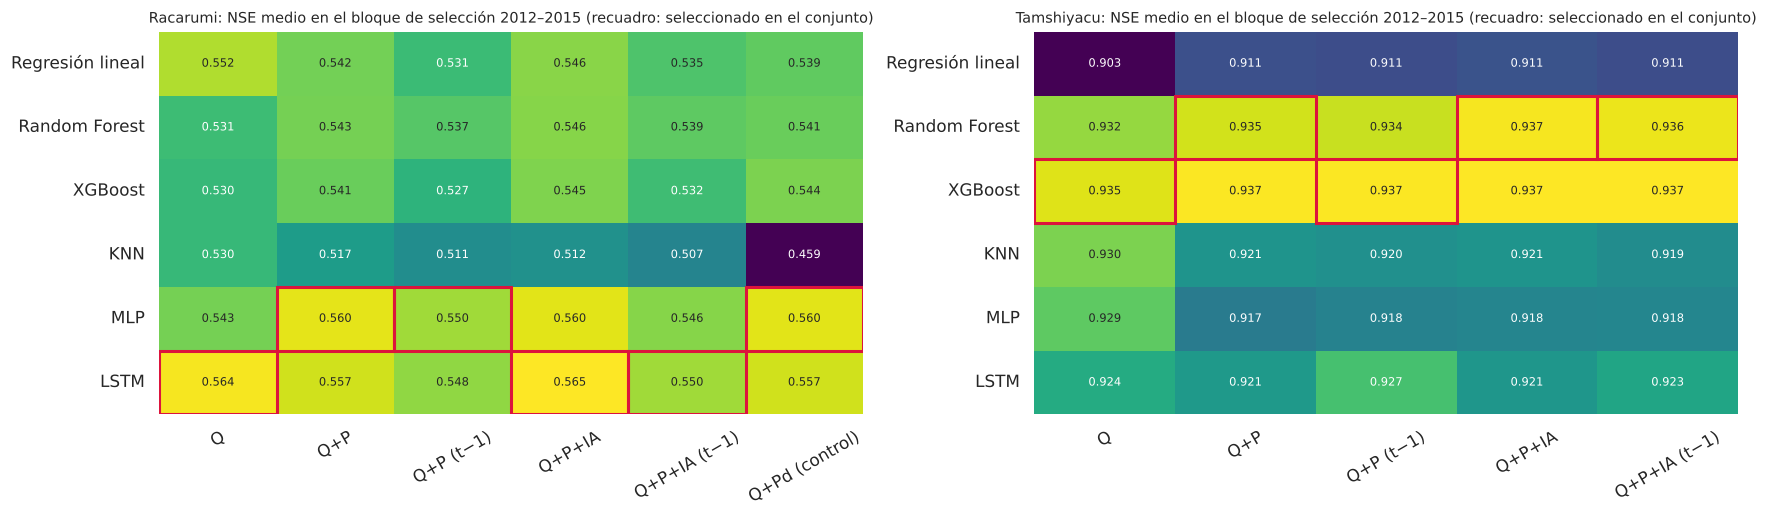

modelo                     Regresión lineal  Random Forest  XGBoost    KNN  \
estación   conjunto                                                          
Racarumi   Q                          0.552          0.531    0.530  0.530   
           Q+P                        0.542          0.543    0.541  0.517   
           Q+P (t−1)                  0.531          0.537    0.527  0.511   
           Q+P+IA                     0.546          0.546    0.545  0.512   
           Q+P+IA (t−1)               0.535          0.539    0.532  0.507   
           Q+Pd (control)             0.539          0.541    0.544  0.459   
Tamshiyacu Q                          0.903          0.932    0.935  0.930   
           Q+P                        0.911          0.935    0.937  0.921   
           Q+P (t−1)                  0.911          0.934    0.937  0.920   
           Q+P+IA                     0.911          0.937    0.937  0.921   
           Q+P+IA (t−1)               0.911          0.936    0.937  0.919   

modelo                       MLP   LSTM  
estación   conjunto                      
Racarumi   Q               0.543  0.564  
           Q+P             0.560  0.557  
           Q+P (t−1)       0.550  0.548  
           Q+P+IA          0.560  0.565  
           Q+P+IA (t−1)    0.546  0.550  
           Q+Pd (control)  0.560  0.557  
Tamshiyacu Q               0.929  0.924  
           Q+P             0.917  0.921  
           Q+P (t−1)       0.918  0.927  
           Q+P+IA          0.918  0.921  
           Q+P+IA (t−1)    0.918  0.923

In [13]:
VAL, SELM, MV = [], {}, []
for e in EST:
    VAL.append(I.tabla_validacion(EXP[e], P[e], R=R[e]))
    s_, mv = I.seleccion_por_conjunto(EXP[e], P[e], modelos=MODELOS, B=B)
    SELM[e] = s_; MV.append(mv)
val = pd.concat(VAL, ignore_index=True); metodo_val = pd.concat(MV, ignore_index=True)
val.to_csv(RUTA_TAB / 'tabla_validacion.csv', index=False)
metodo_val.to_csv(RUTA_TAB / 'tabla_seleccion_modelo_por_conjunto.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
for a, e in zip(ax, EST):
    I.fig_validacion(a, EXP[e], val, SELM[e], MODELOS)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig04_validacion.png', dpi=200, bbox_inches='tight'); plt.show()
I.tabla_corta(val, ['estación', 'conjunto'], 'NSE medio selección', modelos=MODELOS).round(3)

**Figura 4.** NSE medio de los 30 horizontes en el bloque de selección para cada modelo (filas) y configuración (columnas); el recuadro marca el modelo seleccionado en cada configuración con la regla de selección del estudio.

In [14]:
COMPARACIONES_E = {e: [('P', ('Q+P', 0), ('Q', 0)), ('IA sobre P', ('Q+P+IA', 0), ('Q+P', 0)), ('P con latencia 1 d', ('Q+P', 1), ('Q', 0)),
                       ('retraso de P (t−1 frente a t)', ('Q+P', 1), ('Q+P', 0)), ('P + IA con latencia 1 d', ('Q+P+IA', 1), ('Q', 0)),
                       ('IA sobre P, latencia 1 d', ('Q+P+IA', 1), ('Q+P', 1)), ('retraso de P + IA (t−1 frente a t)', ('Q+P+IA', 1), ('Q+P+IA', 0))]
                   for e in EST}
COMPARACIONES_E['Racarumi'].append(('P diaria (Pd) frente a P', ('Q+Pd', 0), ('Q+P', 0)))
EV, EVB = [], []
for e in EST:
    a_, b_ = I.efecto_entrada_validacion(EXP[e], P[e], COMPARACIONES_E[e], MODELOS, B=B)
    EV.append(a_); EVB.append(b_)
entrada_val, entrada_val_b = pd.concat(EV, ignore_index=True), pd.concat(EVB, ignore_index=True)
entrada_val.to_csv(RUTA_TAB / 'tabla_efecto_entrada_validacion.csv', index=False)
entrada_val_b.to_csv(RUTA_TAB / 'tabla_efecto_entrada_validacion_bandas.csv', index=False)
display(I.tabla_corta(entrada_val, ['estación', 'entrada'], None, I.fmt_delta, MODELOS))
I.tabla_corta(entrada_val_b, ['estación', 'entrada', 'banda'], None, I.fmt_g, MODELOS)

modelo                                        Regresión lineal Random Forest  \
estación   entrada                                                             
Racarumi   P                                          -0.010 ?      +0.011 ?   
           IA sobre P                                 +0.004 ▲      +0.003 =   
           P con latencia 1 d                         -0.021 ▼      +0.005 ?   
           retraso de P (t−1 frente a t)              -0.011 ▼      -0.006 ?   
           P + IA con latencia 1 d                    -0.017 ▼      +0.007 ?   
           IA sobre P, latencia 1 d                   +0.004 ▲      +0.002 =   
           retraso de P + IA (t−1 frente a t)         -0.011 ▼      -0.007 ?   
           P diaria (Pd) frente a P                   -0.003 ?      -0.002 =   
Tamshiyacu P                                          +0.008 ?      +0.003 =   
           IA sobre P                                 +0.000 =      +0.002 =   
           P con latencia 1 d                         +0.008 ?      +0.003 =   
           retraso de P (t−1 frente a t)              -0.000 =      -0.001 =   
           P + IA con latencia 1 d                    +0.008 ?      +0.004 ?   
           IA sobre P, latencia 1 d                   +0.000 =      +0.002 =   
           retraso de P + IA (t−1 frente a t)         -0.001 =      -0.001 =   

modelo                                          XGBoost       KNN       MLP  \
estación   entrada                                                            
Racarumi   P                                   +0.011 ?  -0.013 ?  +0.018 ?   
           IA sobre P                          +0.004 ?  -0.005 ?  -0.000 =   
           P con latencia 1 d                  -0.003 ?  -0.019 ?  +0.007 ?   
           retraso de P (t−1 frente a t)       -0.013 ▼  -0.007 ?  -0.011 ▼   
           P + IA con latencia 1 d             +0.002 ?  -0.023 ?  +0.003 ?   
           IA sobre P, latencia 1 d            +0.005 ?  -0.004 ?  -0.004 ?   
           retraso de P + IA (t−1 frente a t)  -0.012 ▼  -0.005 ?  -0.014 ▼   
           P diaria (Pd) frente a P            +0.003 =  -0.058 ▼  -0.000 ?   
Tamshiyacu P                                   +0.001 =  -0.010 ▼  -0.012 ▼   
           IA sobre P                          +0.000 =  +0.000 =  +0.001 =   
           P con latencia 1 d                  +0.001 =  -0.011 ▼  -0.011 ▼   
           retraso de P (t−1 frente a t)       +0.000 =  -0.001 =  +0.001 =   
           P + IA con latencia 1 d             +0.002 =  -0.011 ▼  -0.010 ▼   
           IA sobre P, latencia 1 d            +0.000 =  -0.001 =  +0.000 =   
           retraso de P + IA (t−1 frente a t)  -0.000 =  -0.001 =  +0.000 =   

modelo                                             LSTM  
estación   entrada                                       
Racarumi   P                                   -0.006 ?  
           IA sobre P                          +0.008 ?  
           P con latencia 1 d                  -0.016 ▼  
           retraso de P (t−1 frente a t)       -0.010 ?  
           P + IA con latencia 1 d             -0.014 ?  
           IA sobre P, latencia 1 d            +0.002 ?  
           retraso de P + IA (t−1 frente a t)  -0.015 ▼  
           P diaria (Pd) frente a P            +0.000 =  
Tamshiyacu P                                   -0.003 ?  
           IA sobre P                          -0.000 ?  
           P con latencia 1 d                  +0.003 ?  
           retraso de P (t−1 frente a t)       +0.006 ▲  
           P + IA con latencia 1 d             -0.001 ?  
           IA sobre P, latencia 1 d            -0.004 ?  
           retraso de P + IA (t−1 frente a t)  +0.002 =

modelo                                                   Regresión lineal  \
estación   entrada                            banda                         
Racarumi   P                                  1–3 días            +16 % +   
                                              4–7 días             +0 % ≈   
                                              8–15 días            -6 % −   
                                              16–30 días           -3 % ≈   
           IA sobre P                         1–3 días             +1 % +   
                                              4–7 días             +3 % +   
                                              8–15 días            +2 % +   
                                              16–30 días           -0 % ≈   
           P con latencia 1 d                 1–3 días             -5 % −   
                                              4–7 días             -6 % −   
                                              8–15 días            -6 % −   
                                              16–30 días           -4 % ≈   
           retraso de P (t−1 frente a t)      1–3 días            -25 % −   
                                              4–7 días             -6 % −   
                                              8–15 días            -1 % ≈   
                                              16–30 días           -1 % −   
           P + IA con latencia 1 d            1–3 días             -2 % ≈   
                                              4–7 días             -2 % ≈   
                                              8–15 días            -4 % −   
                                              16–30 días           -4 % ≈   
           IA sobre P, latencia 1 d           1–3 días             +3 % +   
                                              4–7 días             +4 % +   
                                              8–15 días            +2 % +   
                                              16–30 días           -0 % ≈   
           retraso de P + IA (t−1 frente a t) 1–3 días            -23 % −   
                                              4–7 días             -6 % −   
                                              8–15 días            -1 % ≈   
                                              16–30 días           -1 % −   
           P diaria (Pd) frente a P           1–3 días             -3 % ≈   
                                              4–7 días             -2 % ≈   
                                              8–15 días            -0 % ≈   
                                              16–30 días           -0 % ≈   
Tamshiyacu P                                  1–3 días             +1 % ≈   
                                              4–7 días             +3 % ≈   
                                              8–15 días            +5 % ≈   
                                              16–30 días          +10 % +   
           IA sobre P                         1–3 días             +1 % ≈   
                                              4–7 días             +1 % ≈   
                                              8–15 días            +1 % ≈   
                                              16–30 días           +0 % ≈   
           P con latencia 1 d                 1–3 días             +1 % ≈   
                                              4–7 días             +3 % ≈   
                                              8–15 días            +5 % ≈   
                                              16–30 días           +9 % +   
           retraso de P (t−1 frente a t)      1–3 días             +0 % ≈   
                                              4–7 días             +0 % ≈   
                                              8–15 días            -0 % ≈   
                                              16–30 días           -1 % ≈   
           P + IA con latencia 1 d            1–3 días             +2 % ≈   
                                              4–7 días             +4 % ≈

In [15]:
filas, CONFIG, EQUIV, NOPEOR = [], {}, {}, {}
for e in EST:
    for esc in I.ESCENARIOS:
        cand = [k for k in P[e] if I.en_escenario(k[0], k[1], esc)]
        s_ = I.seleccion_configuracion(EXP[e], P[e], cand, B=B)
        CONFIG[(e, esc)], EQUIV[(e, esc)], NOPEOR[(e, esc)] = s_['elegida'], s_['equivalentes'], s_['no_peores']
        filas.append({'estación': e, 'escenario': esc, 'disponibilidad': OBS if esc == 'mismo día' else LAT, **s_['resumen']})
config = pd.DataFrame(filas).set_index(['estación', 'escenario'])
config.to_csv(RUTA_TAB / 'tabla_configuracion_seleccionada.csv')
config.T

estación                                                                                     Racarumi  \
escenario                                                                                   mismo día   
disponibilidad                                      + lluvia observada hasta t (disponibilidad sup...   
candidatos                                                                                         18   
mayor NSE medio                                                                         Q+P+IA · LSTM   
NSE medio del mayor                                                                          0.564904   
seleccionada (la más simple entre el mayor y su...                                      Q+P+IA · LSTM   
NSE medio de la seleccionada                                                                 0.564904   
equivalentes al mayor (IC dentro de ±0.01)                                                          0   
inconclusas (IC demasiado ancho; no es equivale...                                                 16   
peores (IC < 0)                                                                                     1   
no demostradas peores (mayor + equivalentes + i...                                                 17   
equivalentes: las 5 de mayor NSE medio                                          Q+P+IA · LSTM (0.565)   
inconclusas: las 5 de mayor NSE medio               Q · LSTM (0.564) | Q+P · MLP (0.560) | Q+P+IA ...   

estación                                                                                               \
escenario                                                                           un día de retraso   
disponibilidad                                                          + lluvia disponible hasta t−1   
candidatos                                                                                         18   
mayor NSE medio                                                                              Q · LSTM   
NSE medio del mayor                                                                          0.563631   
seleccionada (la más simple entre el mayor y su...                                           Q · LSTM   
NSE medio de la seleccionada                                                                 0.563631   
equivalentes al mayor (IC dentro de ±0.01)                                                          0   
inconclusas (IC demasiado ancho; no es equivale...                                                 12   
peores (IC < 0)                                                                                     5   
no demostradas peores (mayor + equivalentes + i...                                                 13   
equivalentes: las 5 de mayor NSE medio                                               Q · LSTM (0.564)   
inconclusas: las 5 de mayor NSE medio               Q · Regresión lineal (0.552) | Q+P+IA (t−1) · ...   

estación                                                                                   Tamshiyacu  \
escenario                                                                                   mismo día   
disponibilidad                                      + lluvia observada hasta t (disponibilidad sup...   
candidatos                                                                                         18   
mayor NSE medio                                                                      Q+P+IA · XGBoost   
NSE medio del mayor                                                                          0.937108   
seleccionada (la más simple entre el mayor y su...                                        Q · XGBoost   
NSE medio de la seleccionada                                                                 0.935437   
equivalentes al mayor (IC dentro de ±0.01)                                                          4   
inconclusas (IC demasiado ancho; no es equivale...                                                  2   
peores (

**Lectura:** ΔNSE medio en el bloque de selección; ▲ mejora (IC 90 % > 0), ▼ peor (IC < 0), = equivalente (IC dentro de ±0.01), ? inconcluso. G por bandas: reducción del error cuadrático con su IC 90 %.

**Interpretación, Racarumi:**
- **Modelo por configuración:** la regla de selección del estudio elige la **LSTM** con Q, Q+P+IA y Q+P+IA (t−1), y el **MLP** con Q+P, Q+P (t−1) y el control Q+Pd. Las redes tienen el mayor NSE medio de selección en todas las configuraciones, pero **casi todas las diferencias entre modelos son inconclusas**. «Seleccionado» significa elegido por la regla, no superior demostrado.
- **Efecto de la entrada (NSE medio):** la lluvia queda **inconclusa** con los seis modelos; los índices mejoran solo a la regresión lineal (+0.004); **retrasar la lluvia un día empeora** a la regresión lineal, XGBoost y el MLP (y a la LSTM con índices); Pd frente a los acumulados es inconclusa o equivalente, salvo el KNN (−0.058).
- **Por bandas:** la lluvia hasta t reduce el error de los seis modelos a 1–3 días (14–32 %) y de cuatro a 4–7 días (9–11 %). Con un día de retraso el efecto frente a solo caudal queda entre −5 % y +2 % a 1–3 días; frente a conocerla el mismo día, el error a 1–3 días es 19–45 % mayor.
- **Configuración seleccionada:** «mismo día», **Q+P+IA · LSTM** (NSE medio 0.565), con Q · LSTM a 0.001 y 16 de 18 combinaciones inconclusas; con el arranque estacionario del IPA la elección pasa a Q · LSTM (4.3). «Un día de retraso»: **Q · LSTM**: con un día de retraso la lluvia no se adopta.

**Interpretación, Tamshiyacu:**
- **Modelo por configuración:** **XGBoost** con Q (el mismo resultado del cuaderno 02) y con Q+P (t−1); **Random Forest** con Q+P, Q+P+IA y Q+P+IA (t−1), equivalente a XGBoost y más simple. La regresión lineal, el MLP, la LSTM y, con lluvia, el KNN quedan peor que el mejor en casi todas las configuraciones (NSE medio 0.90–0.93 frente a 0.935–0.937).
- **Efecto de la entrada (NSE medio):** la lluvia es **equivalente** con Random Forest y XGBoost, inconclusa con la regresión lineal (+0.008) y la LSTM, y **peor con el KNN (−0.010) y el MLP (−0.012)**. Los índices sobre la lluvia son equivalentes con cinco modelos; retrasar la lluvia un día, también (la LSTM incluso mejora, +0.006).
- **Por bandas:** en validación la lluvia reduce el error solo con XGBoost (5–7 % a 1–7 días), Random Forest (4 % a 4–7) y la regresión lineal (10 % a 16–30), y lo **aumenta** con el KNN (−20 % a 1–3 días) y el MLP (−19 % a 16–30). Con un día de retraso, lo mismo.
- **Configuración seleccionada:** con la lluvia del mismo día, el mayor NSE medio es Q+P+IA · XGBoost (0.9371), pero **Q · XGBoost** (0.9354) es equivalente y más simple: **la regla elige solo caudal**; con un día de retraso, también Q · XGBoost. Además del mayor, 4 candidatos son equivalentes y 2 quedan inconclusos (con un día de retraso, 3 y 3): los inconclusos no son equivalencias, sino comparaciones sin evidencia suficiente.

---
## 6. Prueba (2016–fin): magnitud del caudal, efecto de la entrada y del método
(a) NSE por horizonte, NSE medio y horizonte útil H de cada configuración con la climatología hasta 2015 (H cota = min(H puntual, percentil 5 de H en 1 000 réplicas del bootstrap conjunto por meses); predicciones fijas); (b) la ganancia G = 1 − MSE(con)/MSE(sin) de cada entrada con el mismo modelo, por bandas, con IC 90 %, y si la validación la anticipaba; (c) cada modelo frente al seleccionado en validación para su configuración de entradas; (d) la comparación controlada del método (Racarumi, Q+Pd); (e) cuánto pesa la entrada frente al modelo y las configuraciones seleccionadas por horizonte.

In [16]:
PR, HZ, TABH = [], {}, {}
for e in EST:
    t_, hz_, tb_ = I.metricas_prueba(EXP[e], P[e], B=B)
    PR.append(t_); HZ[e] = hz_; TABH[e] = tb_
    PR.append(I.referencias_prueba(EXP[e], EXP[e].p['pru']))
prueba = pd.concat(PR, ignore_index=True)
prueba.to_csv(RUTA_TAB / 'tabla_metricas_prueba.csv', index=False)
pm = prueba[prueba['modelo'].isin(MODELOS)]
display(I.tabla_corta(pm, ['estación', 'conjunto'], 'NSE medio', modelos=MODELOS).round(3))
I.tabla_corta(pm, ['estación', 'conjunto'], 'H cota 95 % (d)', modelos=MODELOS)

modelo                     Regresión lineal  Random Forest  XGBoost    KNN  \
estación   conjunto                                                          
Racarumi   Q                          0.485          0.503    0.488  0.441   
           Q+P                        0.483          0.519    0.493  0.412   
           Q+P (t−1)                  0.480          0.507    0.483  0.402   
           Q+P+IA                     0.494          0.521    0.498  0.399   
           Q+P+IA (t−1)               0.491          0.509    0.488  0.402   
           Q+Pd (control)             0.473          0.516    0.496  0.344   
Tamshiyacu Q                          0.884          0.908    0.913  0.909   
           Q+P                        0.900          0.913    0.917  0.897   
           Q+P (t−1)                  0.898          0.912    0.915  0.896   
           Q+P+IA                     0.901          0.912    0.916  0.898   
           Q+P+IA (t−1)               0.899          0.912    0.915  0.896   

modelo                       MLP   LSTM  
estación   conjunto                      
Racarumi   Q               0.522  0.524  
           Q+P             0.525  0.533  
           Q+P (t−1)       0.516  0.517  
           Q+P+IA          0.535  0.541  
           Q+P+IA (t−1)    0.525  0.530  
           Q+Pd (control)  0.516  0.533  
Tamshiyacu Q               0.905  0.913  
           Q+P             0.909  0.918  
           Q+P (t−1)       0.908  0.917  
           Q+P+IA          0.923  0.922  
           Q+P+IA (t−1)    0.920  0.920

modelo                     Regresión lineal  Random Forest  XGBoost   KNN  \
estación   conjunto                                                         
Racarumi   Q                            5.0            6.0      6.0   4.0   
           Q+P                          4.0            7.0      6.0   5.0   
           Q+P (t−1)                    0.0            6.0      5.0   4.0   
           Q+P+IA                       4.0            7.0      6.0   4.0   
           Q+P+IA (t−1)                 0.0            6.0      6.0   4.0   
           Q+Pd (control)               4.0            7.0      6.0   4.0   
Tamshiyacu Q                           21.0           30.0     30.0  30.0   
           Q+P                         25.0           30.0     30.0  24.0   
           Q+P (t−1)                   25.0           30.0     30.0  24.0   
           Q+P+IA                      26.0           30.0     30.0  24.0   
           Q+P+IA (t−1)                25.0           30.0     30.0  24.0   

modelo                      MLP  LSTM  
estación   conjunto                    
Racarumi   Q                6.0   6.0  
           Q+P              6.0   7.0  
           Q+P (t−1)        6.0   5.0  
           Q+P+IA           7.0   7.0  
           Q+P+IA (t−1)     6.0   6.0  
           Q+Pd (control)   6.0   7.0  
Tamshiyacu Q               30.0  30.0  
           Q+P             30.0  30.0  
           Q+P (t−1)       30.0  30.0  
           Q+P+IA          30.0  30.0  
           Q+P+IA (t−1)    30.0  30.0

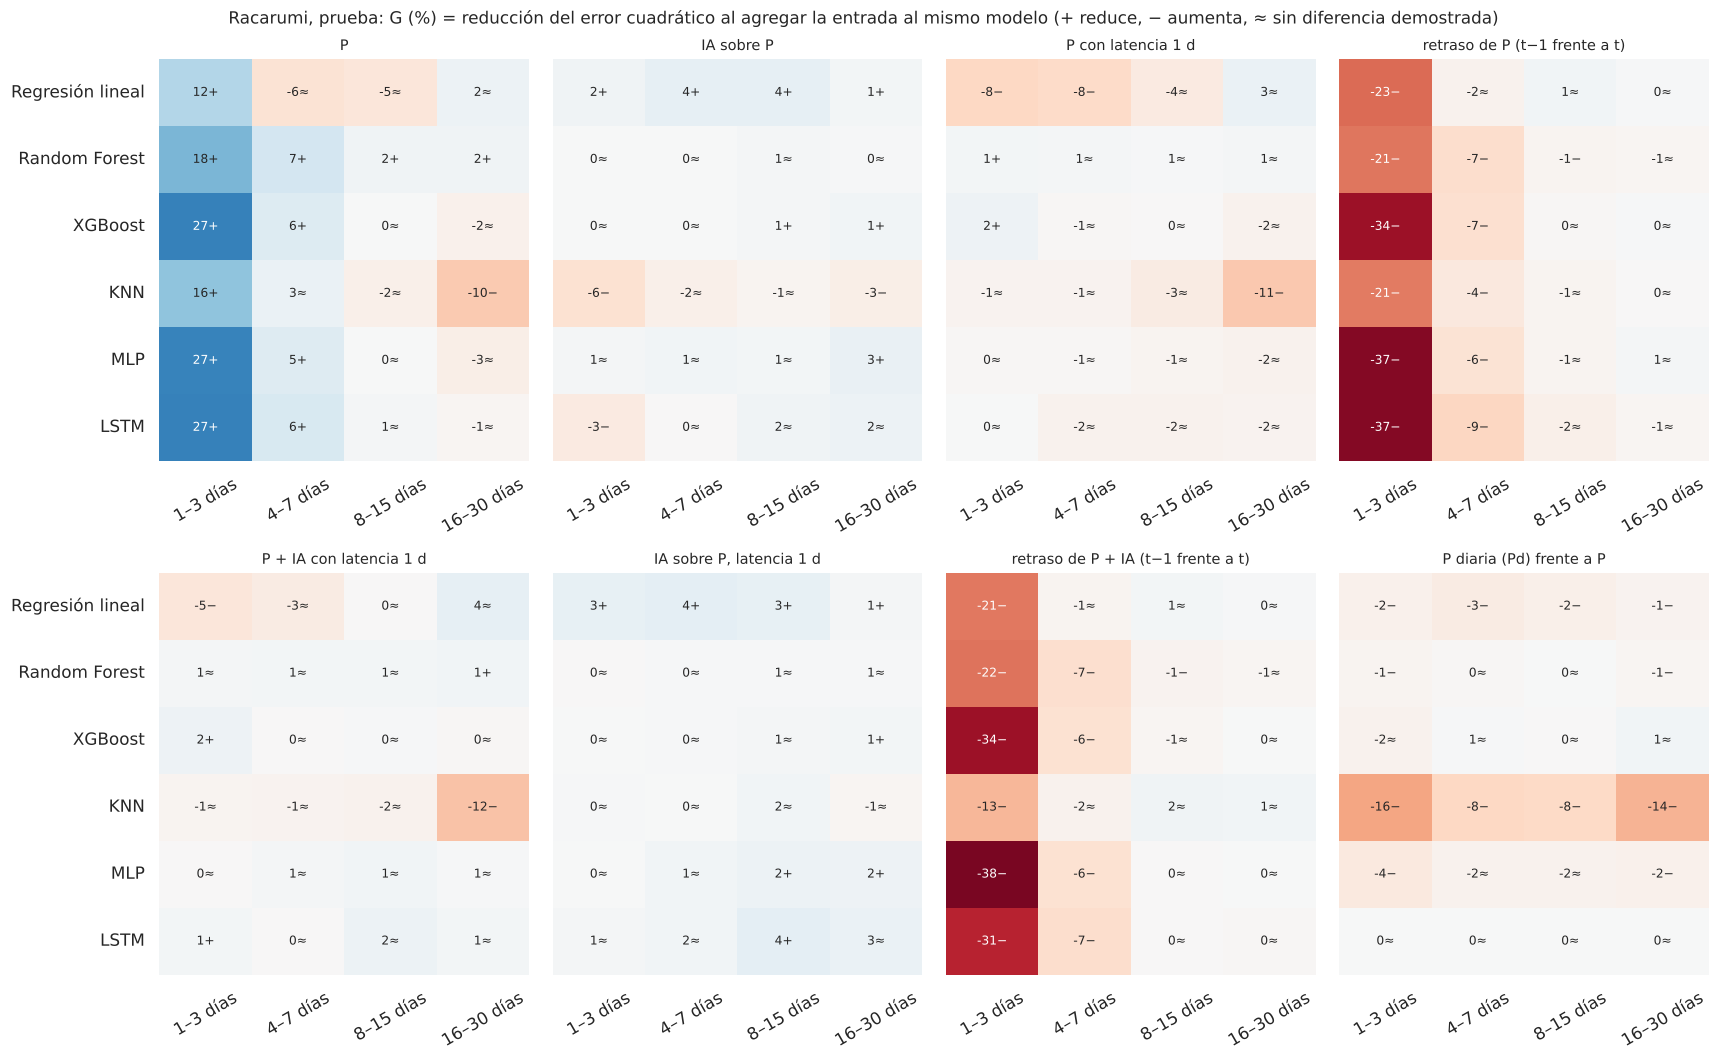

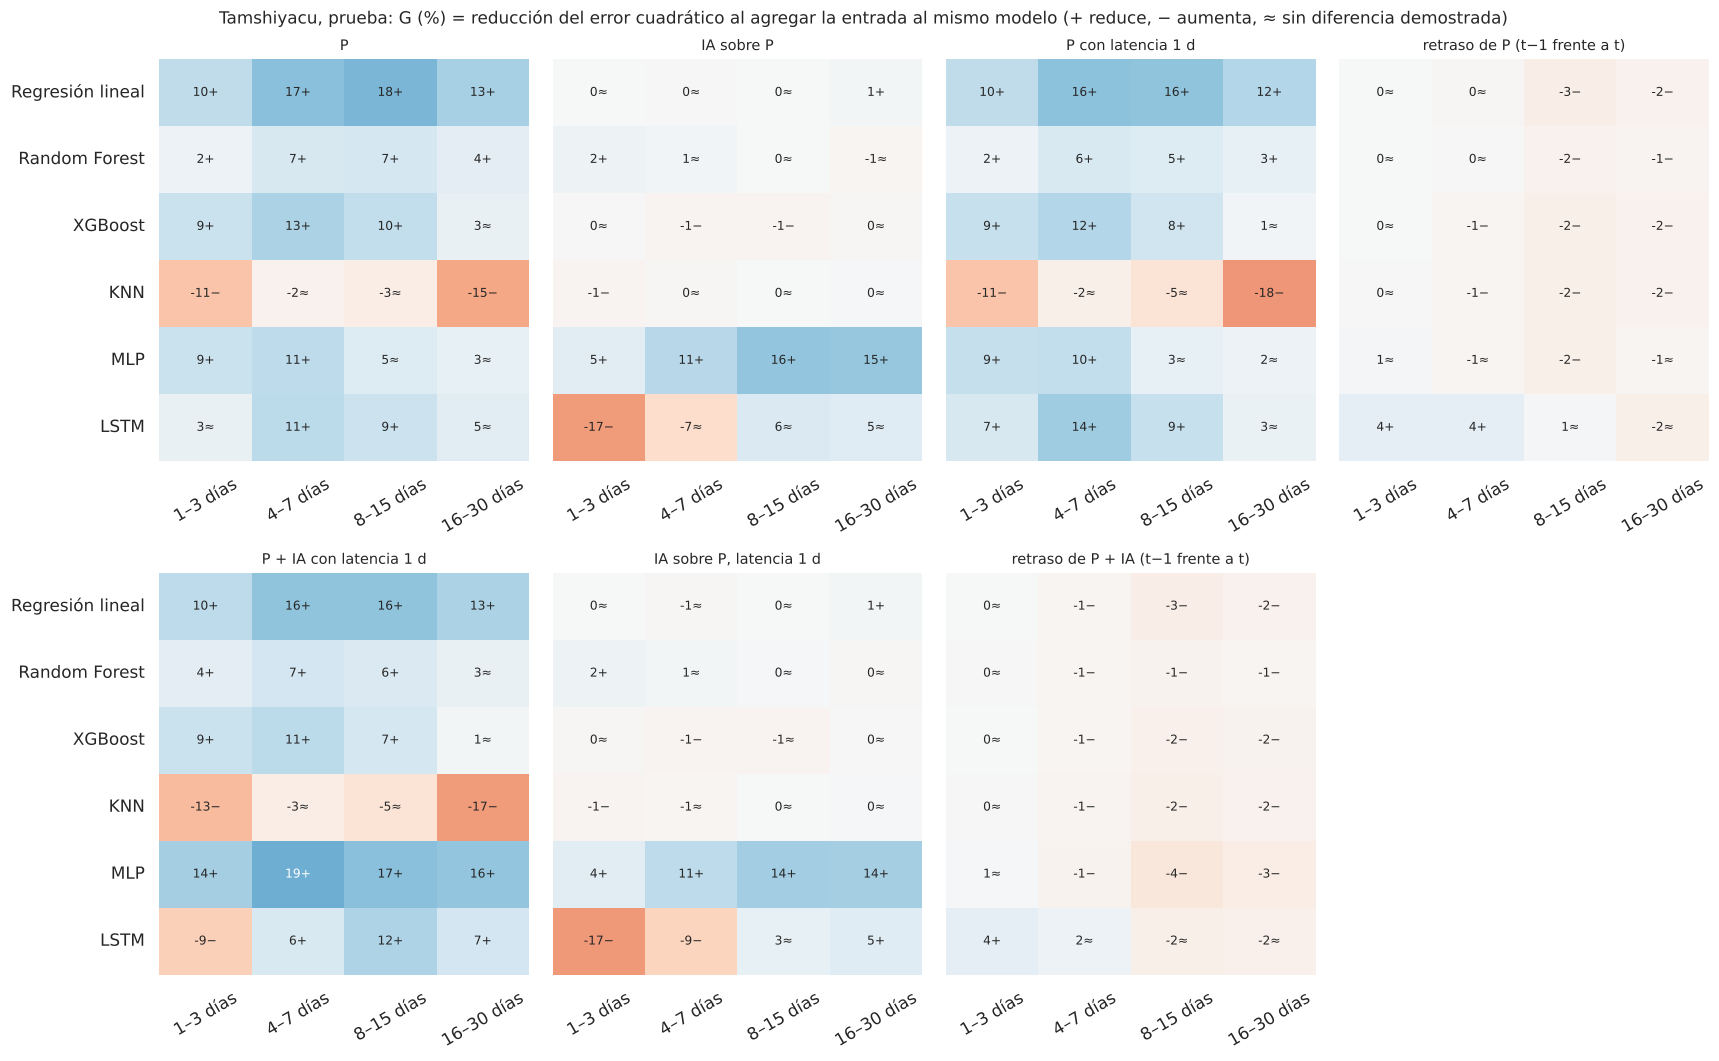

par                                            +/+  ≈/≈  −/≈  ≈/+  ≈/−  −/−  \
estación   entrada                                                            
Racarumi   P                                    10   10    1    2    1    0   
           IA sobre P                            4   14    0    3    2    1   
           P con latencia 1 d                    1   16    2    1    1    2   
           retraso de P (t−1 frente a t)         0    8    3    0    1   11   
           P + IA con latencia 1 d               0   17    1    3    2    0   
           IA sobre P, latencia 1 d              3   14    0    5    0    0   
           retraso de P + IA (t−1 frente a t)    0    7    5    0    1   10   
           P diaria (Pd) frente a P              0    9    0    0    6    6   
Tamshiyacu P                                     4    6    1   11    0    2   
           IA sobre P                            1   12    0    5    3    1   
           P con latencia 1 d                    3    4    2   13    0    2   
           retraso de P (t−1 frente a t)         0    9    0    2    8    3   
           P + IA con latencia 1 d               5    4    0   10    0    3   
           IA sobre P, latencia 1 d              1   11    0    6    3    1   
           retraso de P + IA (t−1 frente a t)    1    5    1    0   11    4   

par                                            +/≈  −/+  
estación   entrada                                       
Racarumi   P                                     0    0  
           IA sobre P                            0    0  
           P con latencia 1 d                    1    0  
           retraso de P (t−1 frente a t)         1    0  
           P + IA con latencia 1 d               1    0  
           IA sobre P, latencia 1 d              2    0  
           retraso de P + IA (t−1 frente a t)    1    0  
           P diaria (Pd) frente a P              3    0  
Tamshiyacu P                                     0    0  
           IA sobre P                            2    0  
           P con latencia 1 d                    0    0  
           retraso de P (t−1 frente a t)         2    0  
           P + IA con latencia 1 d               0    2  
           IA sobre P, latencia 1 d              2    0  
           retraso de P + IA (t−1 frente a t)    2    0

modelo                                                   Regresión lineal  \
estación   entrada                            banda                         
Racarumi   P                                  1–3 días            +12 % +   
                                              4–7 días             -6 % ≈   
                                              8–15 días            -5 % ≈   
                                              16–30 días           +2 % ≈   
           IA sobre P                         1–3 días             +2 % +   
                                              4–7 días             +4 % +   
                                              8–15 días            +4 % +   
                                              16–30 días           +1 % +   
           P con latencia 1 d                 1–3 días             -8 % −   
                                              4–7 días             -8 % −   
                                              8–15 días            -4 % ≈   
                                              16–30 días           +3 % ≈   
           retraso de P (t−1 frente a t)      1–3 días            -23 % −   
                                              4–7 días             -2 % ≈   
                                              8–15 días            +1 % ≈   
                                              16–30 días           +0 % ≈   
           P + IA con latencia 1 d            1–3 días             -5 % −   
                                              4–7 días             -3 % ≈   
                                              8–15 días            -0 % ≈   
                                              16–30 días           +4 % ≈   
           IA sobre P, latencia 1 d           1–3 días             +3 % +   
                                              4–7 días             +4 % +   
                                              8–15 días            +3 % +   
                                              16–30 días           +1 % +   
           retraso de P + IA (t−1 frente a t) 1–3 días            -21 % −   
                                              4–7 días             -1 % ≈   
                                              8–15 días            +1 % ≈   
                                              16–30 días           +0 % ≈   
           P diaria (Pd) frente a P           1–3 días             -2 % −   
                                              4–7 días             -3 % −   
                                              8–15 días            -2 % −   
                                              16–30 días           -1 % −   
Tamshiyacu P                                  1–3 días            +10 % +   
                                              4–7 días            +17 % +   
                                              8–15 días           +18 % +   
                                              16–30 días          +13 % +   
           IA sobre P                         1–3 días             +0 % ≈   
                                              4–7 días             -0 % ≈   
                                              8–15 días            +0 % ≈   
                                              16–30 días           +1 % +   
           P con latencia 1 d                 1–3 días            +10 % +   
                                              4–7 días            +16 % +   
                                              8–15 días           +16 % +   
                                              16–30 días          +12 % +   
           retraso de P (t−1 frente a t)      1–3 días             +0 % ≈   
                                              4–7 días             -0 % ≈   
                                              8–15 días            -3 % −   
                                              16–30 días           -2 % −   
           P + IA con latencia 1 d            1–3 días            +10 % +   
                                              4–7 días            +16 % +

In [17]:
EP = [I.efecto_entrada_prueba(EXP[e], P[e], COMPARACIONES_E[e], MODELOS, B=B) for e in EST]
entrada_pru = pd.concat(EP, ignore_index=True)
entrada_pru.to_csv(RUTA_TAB / 'tabla_efecto_entrada_prueba.csv', index=False)
conc = I.concordancia(entrada_val_b, entrada_pru)
conc.to_csv(RUTA_TAB / 'tabla_concordancia_validacion_prueba.csv')
for i, e in enumerate(EST):
    I.fig_ganancias(entrada_pru, e, [c[0] for c in COMPARACIONES_E[e]], RUTA_FIG / f'fig0{5 + i}_efecto_entrada_{e.lower()}.png',
                    f'{e}, prueba: G (%) = reducción del error cuadrático al agregar la entrada al mismo modelo (+ reduce, − aumenta, ≈ sin diferencia demostrada)', MODELOS)
    plt.show()
display(conc)
I.tabla_corta(entrada_pru, ['estación', 'entrada', 'banda'], None, I.fmt_g, MODELOS)

**Figuras 5 y 6.** Prueba: G (%) de cada entrada con el mismo modelo por banda de horizonte. La tabla de concordancia cuenta, para cada entrada, los pares modelo × banda según su lectura en validación / prueba (+ reduce, ≈ sin diferencia demostrada, − aumenta).

**Horizonte útil (cota 95 %, días)** de cada configuración en la prueba (tabla `tabla_metricas_prueba.csv`; 30 significa que no se encontró el límite en 30 días).

**Interpretación, Racarumi:**
- **Magnitud:** las redes tienen el mayor NSE medio de prueba en todas las configuraciones (LSTM 0.524 con Q, 0.533 con Q+P, 0.541 con Q+P+IA, 0.517 con Q+P (t−1) y 0.530 con Q+P+IA (t−1)). El horizonte útil pasa de **6 a 7 días** con la lluvia del mismo día en **Random Forest y la LSTM** (con los índices, también en el MLP); con un día de retraso vuelve a 4–6 días y la regresión lineal queda por debajo de la persistencia a 1 día (**H = 0**).
- **La lluvia hasta t reduce el error a 1–3 días con los seis modelos** (12 % la regresión lineal, 16–18 % KNN y Random Forest, **27 % XGBoost, MLP y LSTM**) y 5–7 % a 4–7 días con Random Forest, XGBoost, MLP y LSTM; después, nada demostrado. La validación lo anticipó: 10 pares modelo × banda reducen el error en las dos y ninguno tiene signos opuestos. XGBoost, el MLP y la LSTM reducen su error en la misma proporción: que las redes terminen con mayor NSE no significa que aprovechen más la lluvia.
- **Lluvia con un día de retraso frente a solo caudal:** el beneficio cae casi por completo, pero **no desaparece en todos**: Random Forest (+1 %) y XGBoost (+2 %) conservan una mejora pequeña a 1–3 días; la regresión lineal empeora (−8 % a 1–7 días). Frente a la lluvia del mismo día, el retraso aumenta el error 21–37 % a 1–3 días (11 pares peores en validación y en prueba).
- **Índices sobre la lluvia:** no producen una mejora consistente: la regresión lineal gana 1–4 % en todas las bandas, XGBoost y el MLP 1–3 % en algunas bandas largas, Random Forest nada, y el KNN (−6 %) y la LSTM (−3 %) empeoran a 1–3 días.
- **Lluvia diaria (Pd) frente a los acumulados:** más detalle diario **no ayuda** a los modelos tabulares (la regresión lineal pierde 1–3 %, el MLP 2–4 %, Random Forest ~1 % y el KNN 8–16 %; XGBoost sin diferencia). La LSTM es idéntica (mismos canales).

**Interpretación, Tamshiyacu:**
- **Magnitud:** NSE medio de prueba 0.88–0.92; casi todos los modelos no lineales tienen H ≥ 30 días con cualquier entrada. La lluvia sube la cota de la regresión lineal de 21 a 25–26 días y **baja la del KNN de ≥ 30 a 24**.
- **La lluvia reduce el error con cinco de los seis modelos en la prueba:** regresión lineal 10–18 % en todas las bandas, XGBoost 9–13 % a 1–15 días, el MLP 9–11 % a 1–7, la LSTM 9–11 % a 4–15 y Random Forest 2–7 %; **al KNN le aumenta el error** (−11 % a 1–3 días y −15 % a 16–30). **Pero en validación no lo mostró:** 11 de los 24 pares solo reducen el error en la prueba, 4 en las dos y 2 lo aumentan en las dos. Con la regla fijada, no se adopta.
- **Con un día de retraso conserva casi todo su efecto** (regresión lineal 10–16 %, XGBoost 8–12 % a 1–15 días, la LSTM 7–14 % a 1–15): la cuenca responde en 6–7 días (sección 3.2).

In [18]:
metodo_pru = pd.concat([I.efecto_metodo(EXP[e], P[e], SELM[e], B=B) for e in EST], ignore_index=True)
metodo_pru.to_csv(RUTA_TAB / 'tabla_efecto_metodo_prueba.csv', index=False)
I.tabla_corta(metodo_pru, ['estación', 'conjunto', 'referencia'], None, I.fmt_delta, MODELOS)

modelo                                                 Regresión lineal  \
estación   conjunto       referencia                                      
Racarumi   Q              Q · LSTM                             -0.040 ▼   
           Q+P            Q+P · MLP                            -0.042 ▼   
           Q+P (t−1)      Q+P (t−1) · MLP                      -0.036 ▼   
           Q+P+IA         Q+P+IA · LSTM                        -0.047 ▼   
           Q+P+IA (t−1)   Q+P+IA (t−1) · LSTM                  -0.039 ▼   
           Q+Pd (control) Q+Pd (control) · MLP                 -0.043 ▼   
Tamshiyacu Q              Q · XGBoost                          -0.029 ▼   
           Q+P            Q+P · Random Forest                  -0.013 ▼   
           Q+P (t−1)      Q+P (t−1) · XGBoost                  -0.017 ▼   
           Q+P+IA         Q+P+IA · Random Forest               -0.011 ▼   
           Q+P+IA (t−1)   Q+P+IA (t−1) · Random Forest         -0.012 ▼   

modelo                                                 Random Forest  \
estación   conjunto       referencia                                   
Racarumi   Q              Q · LSTM                          -0.021 ▼   
           Q+P            Q+P · MLP                         -0.006 ?   
           Q+P (t−1)      Q+P (t−1) · MLP                   -0.009 ?   
           Q+P+IA         Q+P+IA · LSTM                     -0.020 ▼   
           Q+P+IA (t−1)   Q+P+IA (t−1) · LSTM               -0.021 ▼   
           Q+Pd (control) Q+Pd (control) · MLP              +0.001 ?   
Tamshiyacu Q              Q · XGBoost                       -0.004 =   
           Q+P            Q+P · Random Forest                    NaN   
           Q+P (t−1)      Q+P (t−1) · XGBoost               -0.004 =   
           Q+P+IA         Q+P+IA · Random Forest                 NaN   
           Q+P+IA (t−1)   Q+P+IA (t−1) · Random Forest           NaN   

modelo                                                   XGBoost       KNN  \
estación   conjunto       referencia                                         
Racarumi   Q              Q · LSTM                      -0.036 ▼  -0.083 ▼   
           Q+P            Q+P · MLP                     -0.032 ▼  -0.113 ▼   
           Q+P (t−1)      Q+P (t−1) · MLP               -0.032 ▼  -0.113 ▼   
           Q+P+IA         Q+P+IA · LSTM                 -0.043 ▼  -0.142 ▼   
           Q+P+IA (t−1)   Q+P+IA (t−1) · LSTM           -0.042 ▼  -0.128 ▼   
           Q+Pd (control) Q+Pd (control) · MLP          -0.020 ▼  -0.172 ▼   
Tamshiyacu Q              Q · XGBoost                        NaN  -0.004 =   
           Q+P            Q+P · Random Forest           +0.004 ▲  -0.015 ▼   
           Q+P (t−1)      Q+P (t−1) · XGBoost                NaN  -0.020 ▼   
           Q+P+IA         Q+P+IA · Random Forest        +0.004 ▲  -0.015 ▼   
           Q+P+IA (t−1)   Q+P+IA (t−1) · Random Forest  +0.003 ▲  -0.016 ▼   

modelo                                                       MLP      LSTM  
estación   conjunto       referencia                                        
Racarumi   Q              Q · LSTM                      -0.002 ?       NaN  
           Q+P            Q+P · MLP                          NaN  +0.009 ?  
           Q+P (t−1)      Q+P (t−1) · MLP                    NaN  +0.001 ?  
           Q+P+IA         Q+P+IA · LSTM                 -0.006 ?       NaN  
           Q+P+IA (t−1)   Q+P+IA (t−1) · LSTM           -0.005 ?       NaN  
           Q+Pd (control) Q+Pd (control) · MLP               NaN  +0.018 ▲  
Tamshiyacu Q              Q · XGBoost                   -0.008 ?  +0.000 =  
           Q+P            Q+P · Random Forest           -0.004 ?  +0.005 ?  
           Q+P (t−1)      Q+P (t−1) · XGBoost           -0.008 ?  +0.002 =  
           Q+P+IA         Q+P+IA · Random Forest        +0.010 ▲  +0.009 ▲  
           Q+P+IA (t−1)   Q+P+IA (t−1) · Random Forest  +0.009 ▲  +0.009 ▲

**Efecto del método:** ΔNSE medio de prueba de cada modelo frente al seleccionado en validación para su configuración de entradas (▲ mejora, ▼ peor, = equivalente, ? inconcluso). Son 5 comparaciones por configuración: evidencia descriptiva, no una garantía conjunta.

**Comparación controlada del método (Racarumi, Q+Pd):** cada modelo tabular con **Q+Pd** (30 días diarios de lluvia + suma t−30…t−89, el contenido de los canales de la LSTM) frente a la **LSTM con Q+P**, en validación y en prueba. La LSTM con Q+Pd recibe los mismos canales que con Q+P y debe coincidir. Si la ventaja de la LSTM desaparece con el mismo contenido, se debía a la representación y no al algoritmo.

In [19]:
xR, PRr = EXP['Racarumi'], P['Racarumi']
lstm_igual = np.allclose(R['Racarumi'][('Q+Pd', 0, 'LSTM')]['yp'], R['Racarumi'][('Q+P', 0, 'LSTM')]['yp'])
ref = ('Q+P', 0, 'LSTM')
otros = [('Q+Pd', 0, n) for n in MODELOS if n != 'LSTM'] + [('Q+P', 0, n) for n in MODELOS if n != 'LSTM']
ctrl = I.comparar_con(xR, PRr, ref, otros, B=B, campo='sel').set_index('configuración')[['NSE medio', 'ΔNSE medio', 'IC90 inferior', 'IC90 superior', 'clase']].add_suffix(' (validación)').join(
       I.comparar_con(xR, PRr, ref, otros, B=B).set_index('configuración')[['NSE medio', 'ΔNSE medio', 'IC90 inferior', 'IC90 superior', 'clase'] +
                                                                           [f'G {b}' for b in I.BANDAS] + [f'lectura {b}' for b in I.BANDAS]].add_suffix(' (prueba)'))
ctrl.to_csv(RUTA_TAB / 'tabla_metodo_controlado.csv')
print(f'LSTM con Q+Pd idéntica a la LSTM con Q+P (mismos canales): {lstm_igual}')
ctrl.round(3)

LSTM con Q+Pd idéntica a la LSTM con Q+P (mismos canales): True


,NSE medio (validación),ΔNSE medio (validación),IC90 inferior (validación),IC90 superior (validación),clase (validación),NSE medio (prueba),ΔNSE medio (prueba),IC90 inferior (prueba),IC90 superior (prueba),clase (prueba),G 1–3 días (prueba),G 4–7 días (prueba),G 8–15 días (prueba),G 16–30 días (prueba),lectura 1–3 días (prueba),lectura 4–7 días (prueba),lectura 8–15 días (prueba),lectura 16–30 días (prueba)
configuración,,,,,,,,,,,,,,,,,,
Q+Pd (control) · Regresión lineal,0.539,-0.018,-0.067,0.033,inconcluso,0.473,-0.060,-0.087,-0.035,peor,-0.310,-0.269,-0.182,-0.060,aumenta el error,aumenta el error,aumenta el error,aumenta el error
Q+Pd (control) · Random Forest,0.541,-0.016,-0.082,0.036,inconcluso,0.516,-0.017,-0.028,-0.006,peor,-0.122,0.001,-0.027,-0.043,aumenta el error,sin diferencia demostrada,sin diferencia demostrada,aumenta el error
Q+Pd (control) · XGBoost,0.544,-0.013,-0.060,0.030,inconcluso,0.496,-0.037,-0.052,-0.023,peor,-0.020,-0.030,-0.098,-0.085,sin diferencia demostrada,aumenta el error,aumenta el error,aumenta el error
Q+Pd (control) · KNN,0.459,-0.098,-0.203,-0.004,peor,0.344,-0.190,-0.235,-0.158,peor,-0.438,-0.300,-0.364,-0.449,aumenta el error,aumenta el error,aumenta el error,aumenta el error
Q+Pd (control) · MLP,0.560,0.003,-0.018,0.022,inconcluso,0.516,-0.018,-0.031,-0.007,peor,-0.038,-0.041,-0.052,-0.030,aumenta el error,aumenta el error,aumenta el error,sin diferencia demostrada
Q+P · Regresión lineal,0.542,-0.015,-0.059,0.030,inconcluso,0.483,-0.050,-0.075,-0.028,peor,-0.285,-0.228,-0.156,-0.045,aumenta el error,aumenta el error,aumenta el error,sin diferencia demostrada
Q+P · Random Forest,0.543,-0.014,-0.078,0.038,inconcluso,0.519,-0.014,-0.025,-0.004,peor,-0.110,0.005,-0.028,-0.034,aumenta el error,sin diferencia demostrada,sin diferencia demostrada,aumenta el error
Q+P · XGBoost,0.541,-0.017,-0.059,0.025,inconcluso,0.493,-0.041,-0.057,-0.024,peor,-0.002,-0.035,-0.098,-0.099,sin diferencia demostrada,aumenta el error,aumenta el error,aumenta el error
Q+P · KNN,0.517,-0.040,-0.128,0.044,inconcluso,0.412,-0.121,-0.157,-0.092,peor,-0.242,-0.201,-0.263,-0.271,aumenta el error,aumenta el error,aumenta el error,aumenta el error


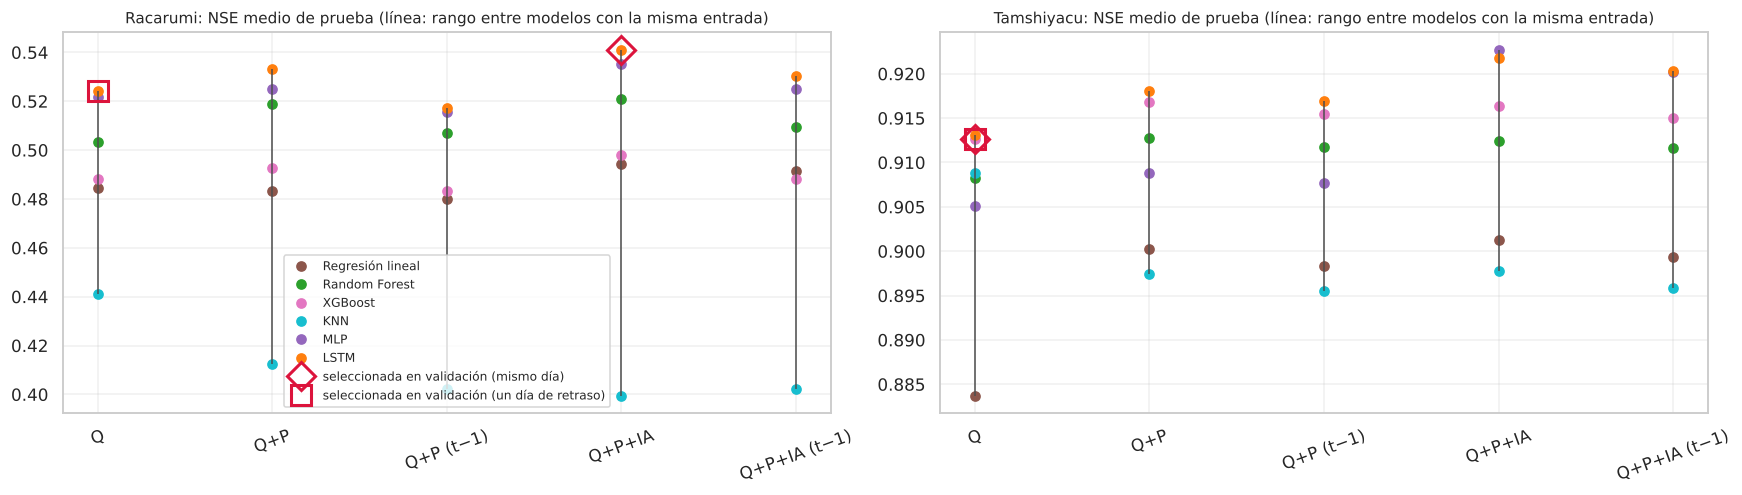

,rango medio entre modelos (misma entrada),rango medio entre entradas (mismo modelo),rango entre modelos sin el peor de cada conjunto
estación,,,
Racarumi,0.118,0.022,0.043
Tamshiyacu,0.024,0.011,0.017


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
filas = []
for a, e in zip(ax, EST):
    t = pm[pm['estación'] == e].pivot_table(index='conjunto', columns='modelo', values='NSE medio', sort=False)[MODELOS]
    t = t.loc[[c for c in t.index if 'control' not in c]]
    for i, (c, fila) in enumerate(t.iterrows()):
        for n in MODELOS:
            a.plot(i, fila[n], 'o', color=C.COLOR[n], ms=6, label=n if i == 0 else None)
        a.vlines(i, fila.min(), fila.max(), color='0.3', lw=1)
    for esc, mk in [('mismo día', 'D'), ('un día de retraso', 's')]:
        c_, l_, n_ = CONFIG[(e, esc)]
        i_ = list(t.index).index(I.etiqueta(c_, l_))
        a.plot(i_, t.loc[I.etiqueta(c_, l_), n_], mk, mfc='none', mec='crimson', ms=13, mew=2, label=f'seleccionada en validación ({esc})')
    a.set_xticks(range(len(t))); a.set_xticklabels(t.index, rotation=20)
    a.set_title(f'{e}: NSE medio de prueba (línea: rango entre modelos con la misma entrada)', fontsize=10); a.grid(True, alpha=0.3)
    filas.append({'estación': e, 'rango medio entre modelos (misma entrada)': (t.max(1) - t.min(1)).mean(),
                  'rango medio entre entradas (mismo modelo)': (t.max(0) - t.min(0)).mean(),
                  'rango entre modelos sin el peor de cada conjunto': (t.max(1) - t.apply(lambda r: r.nsmallest(2).iloc[-1], axis=1)).mean()})
ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig07_entrada_frente_a_modelo.png', dpi=200, bbox_inches='tight'); plt.show()
rangos = pd.DataFrame(filas).set_index('estación')
rangos.to_csv(RUTA_TAB / 'tabla_entrada_frente_a_modelo.csv')
rangos.round(3)

**Figura 7.** NSE medio de prueba de los seis modelos con cada configuración; la línea vertical es el rango entre modelos con la misma entrada; el rombo y el cuadrado, la configuración seleccionada en validación para cada escenario.

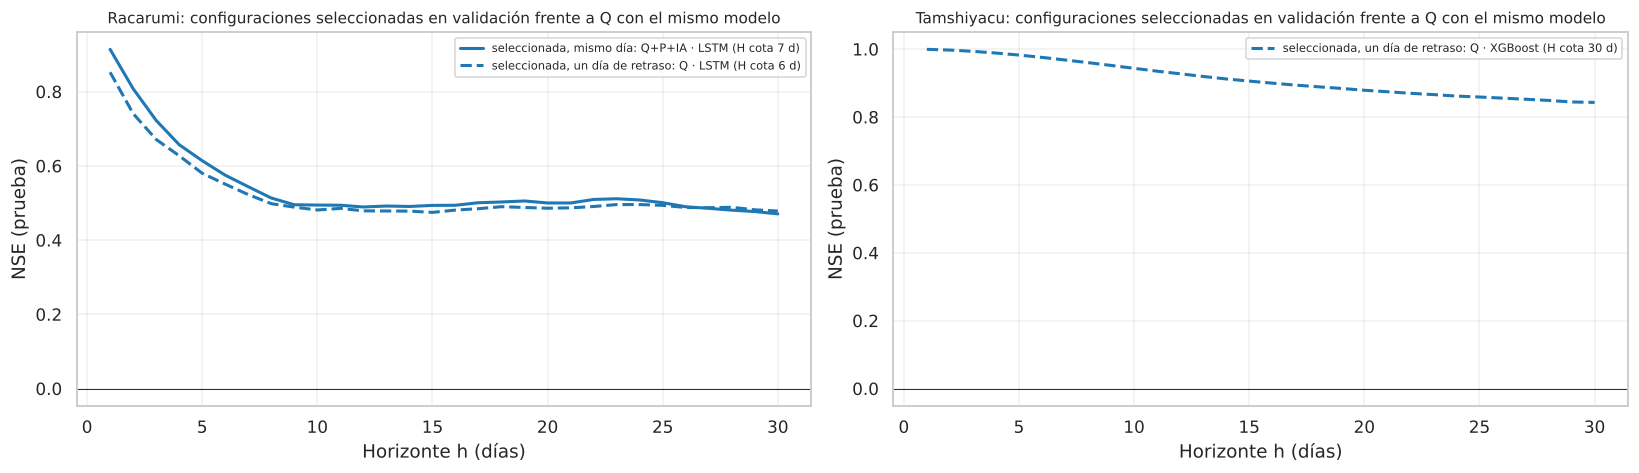

In [21]:
hh = np.array(C.HORIZONTES)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for a, e in zip(ax, EST):
    curvas = {}
    for esc, ls in [('mismo día', '-'), ('un día de retraso', '--')]:
        c, l, n = CONFIG[(e, esc)]
        curvas[(c, l, n)] = (COLV[OBS] if l == 0 else '#6baed6', ls, f'seleccionada, {esc}')
        curvas.setdefault(('Q', 0, n), (COLV[BASE], ls, f'Q con el mismo modelo ({esc})'))
    for (c, l, n), (col, ls, et) in curvas.items():
        a.plot(hh, TABH[e][(c, l, n)]['NSE'], color=col, ls=ls, lw=2, label=f'{et}: {I.nombre((c, l, n))} (H cota {HZ[e][(c, l, n)]["H_cota"]} d)')
    a.axhline(0, color='k', lw=0.6); a.grid(True, alpha=0.3); a.set_xlabel('Horizonte h (días)'); a.set_ylabel('NSE (prueba)')
    a.set_title(f'{e}: configuraciones seleccionadas en validación frente a Q con el mismo modelo', fontsize=10); a.legend(fontsize=7.5)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig08_seleccionadas_nse_horizonte.png', dpi=200, bbox_inches='tight'); plt.show()

**Figura 8.** NSE por horizonte en la prueba de la configuración seleccionada en validación en cada escenario (continua: mismo día; discontinua: un día de retraso) frente al mismo modelo con solo caudal; en la leyenda, la cota 95 % del horizonte útil.

**Interpretación:**
- **Racarumi, efecto del método:** con la misma entrada, la regresión lineal, XGBoost y el KNN quedan **peor** que el modelo seleccionado en todas las configuraciones (−0.03 a −0.05; el KNN −0.08 a −0.17) y Random Forest en tres de cinco (−0.02); el MLP y la LSTM no se distinguen entre sí, salvo con Q+Pd, donde la LSTM es mejor (+0.018).
- **Control del método (Q+Pd, Racarumi):** la LSTM con Q+Pd es idéntica a la LSTM con Q+P (mismos canales). Con el mismo contenido diario de lluvia, los modelos tabulares **siguen por debajo de la LSTM** en la prueba (regresión lineal −0.060, Random Forest −0.017, XGBoost −0.037, MLP −0.018, KNN −0.190; todos «peor»); en validación la diferencia no se demostraba. **La ventaja de la LSTM no se debe a que reciba la lluvia con más detalle**; se atribuye al algoritmo y a la representación secuencial del caudal, con la reserva de que la validación no la distinguía.
- **Tamshiyacu:** los modelos no lineales están a ±0.01. Con Q, Random Forest, el KNN y la LSTM son equivalentes al XGBoost seleccionado y la regresión lineal queda peor (−0.029). Con lluvia, XGBoost supera al Random Forest seleccionado (+0.004) y el KNN y la regresión lineal quedan peor (−0.011 a −0.020); con lluvia e índices, también el MLP (+0.010) y la LSTM (+0.009). El mayor NSE medio de prueba es **Q+P+IA · MLP (0.923)**; la configuración seleccionada en validación (Q · XGBoost) logra 0.913.
- **Figura 7, entrada frente a método:** en **Racarumi el método pesa más que la entrada** en el NSE medio: el rango entre modelos con la misma entrada (0.118 de media; 0.043 sin el peor, el KNN) supera al rango entre entradas con el mismo modelo (0.022). En **Tamshiyacu** pesan parecido (0.024 y 0.011; 0.017 sin el peor modelo).
- **Figura 8:** en Racarumi, la configuración «mismo día» (Q+P+IA · LSTM) mejora a la LSTM con Q en los primeros días (NSE a 1 día 0.914 frente a 0.852) y coincide con ella desde la primera semana; con un día de retraso la seleccionada es la propia Q · LSTM. En Tamshiyacu la seleccionada en los dos escenarios es Q · XGBoost.
- La lectura correcta es por bandas: **la entrada decide cuánto mejora la primera semana; el método, cuánto de la información disponible se aprovecha.** Son muchas comparaciones (cada IC es individual): las diferencias < 0.01 no deben leerse como superioridad.

---
## 7. Caudales elevados
Con cada modelo y configuración: error en los días con Q(t + h) sobre el P95 de entrenamiento (MAE y sesgo) y en los ordinarios, y POD y CSI diarios de superar el P95, a 1, 3 y 7 días. Descriptivo: en Tamshiyacu los días altos vienen de 3 crecidas.

In [22]:
crec = pd.concat([I.crecidas(EXP[e], P[e]) for e in EST], ignore_index=True)
crec.to_csv(RUTA_TAB / 'tabla_crecidas.csv', index=False)
display(crec.groupby('estación')['días altos'].max().rename('días sobre el P95 en la prueba (máx. por horizonte)').to_frame())
crec.pivot_table(index=['estación', 'h', 'conjunto'], columns='modelo', values='MAE altos (m³/s)', sort=False)[MODELOS].round(1)

,días sobre el P95 en la prueba (máx. por horizonte)
estación,
Racarumi,149
Tamshiyacu,77


modelo                       Regresión lineal  Random Forest  XGBoost    KNN  \
estación   h conjunto                                                          
Racarumi   1 Q                           42.7           41.0     40.0   42.1   
             Q+P                         33.9           34.8     27.1   34.4   
             Q+P (t−1)                   44.5           40.6     39.3   41.5   
             Q+P+IA                      33.7           34.8     27.0   37.2   
             Q+P+IA (t−1)                43.9           40.7     39.4   42.0   
             Q+Pd (control)              34.0           35.3     26.8   40.8   
           3 Q                           59.6           57.8     57.7   57.9   
             Q+P                         56.4           54.1     53.7   54.2   
             Q+P (t−1)                   60.1           57.7     57.5   57.9   
             Q+P+IA                      55.8           54.2     54.0   55.9   
             Q+P+IA (t−1)                59.3           57.9     58.0   58.2   
             Q+Pd (control)              57.6           54.3     54.5   58.5   
           7 Q                           72.3           67.8     68.5   69.7   
             Q+P                         68.2           67.1     68.5   69.4   
             Q+P (t−1)                   68.2           68.1     68.2   69.1   
             Q+P+IA                      68.0           66.9     69.1   69.9   
             Q+P+IA (t−1)                68.2           67.9     68.4   71.8   
             Q+Pd (control)              69.5           66.7     68.0   71.8   
Tamshiyacu 1 Q                          143.8          118.2    126.3  113.2   
             Q+P                        163.5          118.5    129.3  120.0   
             Q+P (t−1)                  165.6          118.8    129.5  121.5   
             Q+P+IA                     157.0          116.2    127.8  118.3   
             Q+P+IA (t−1)               160.7          117.2    127.6  121.4   
           3 Q                          539.1          274.9    315.0  245.2   
             Q+P                        635.9          289.8    351.5  257.5   
             Q+P (t−1)                  624.6          289.1    358.6  263.7   
             Q+P+IA                     596.4          290.7    351.0  255.7   
             Q+P+IA (t−1)               597.4          292.2    352.6  263.3   
           7 Q                         1412.1          433.6    506.1  403.4   
             Q+P                       1503.0          462.7    664.6  535.0   
             Q+P (t−1)                 1443.4          457.1    633.4  554.2   
             Q+P+IA                    1368.3          479.2    626.9  511.3   
             Q+P+IA (t−1)              1364.1          479.1    598.2  533.5   

modelo                         MLP   LSTM  
estación   h conjunto                      
Racarumi   1 Q                41.5   41.5  
             Q+P              27.8   29.2  
             Q+P (t−1)        41.4   41.3  
             Q+P+IA           27.2   31.3  
             Q+P+IA (t−1)     41.2   41.1  
             Q+Pd (control)   27.7   29.2  
           3 Q                58.2   57.0  
             Q+P              53.1   52.8  
             Q+P (t−1)        59.0   56.5  
             Q+P+IA           52.6   51.9  
             Q+P+IA (t−1)     57.8   56.5  
             Q+Pd (control)   53.2   52.8  
           7 Q                68.4   67.7  
             Q+P              70.0   69.4  
             Q+P (t−1)        70.5   66.1  
             Q+P+IA           68.9   66.3  
             Q+P+IA (t−1)     69.2   66.1  
             Q+Pd (control)   68.5   69.4  
Tamshiyacu 1 Q               128.2  129.1  
             Q+P             136.6  121.8  
             Q+P (t−1)       145.9  122.8  
             Q+P+IA          127.9  158.7  
             Q+P+IA (t−1)    138.2  143.7  
           3 Q               346.2  243.5  
             Q+P             367.5  272.8  
           

**Interpretación (descriptiva: 148 días sobre el P95 en Racarumi y 77 en Tamshiyacu, de 3 crecidas en Tamshiyacu):**
- **Racarumi:** con la lluvia del mismo día el error medio en caudales altos a 1 día baja con los seis modelos, de 40–43 a **27–35 m³/s** (XGBoost 40 → 27, MLP 42 → 28, LSTM 42 → 29), la subestimación pasa de −10/−13 % a entre +2 y −10 % y el CSI diario de superar el P95 sube de 0.52–0.56 a 0.61–0.69. A 3 días baja algo (57–60 → 53–56 m³/s); a 7 días no cambia (67–72 m³/s, subestimación cercana a −40 % con todos). Con un día de retraso vuelve al nivel de solo caudal; los índices no agregan.
- **Tamshiyacu: la lluvia empeora los caudales altos con los seis modelos desde 3 días** (a 7 días, XGBoost 506 → 665 m³/s, KNN 403 → 535, MLP 518 → 639, Random Forest 434 → 463, regresión lineal 1 412 → 1 503; la LSTM casi igual, 494 → 502), aunque mejora el error total (sección 6). A 1 día los cambios son pequeños. Una explicación posible es que las crecidas de la prueba (2019, 2022 y 2025) tuvieron más caudal o menos lluvia que lo habitual (el coeficiente de escorrentía varía mucho entre años, 3.1), así que la lluvia «promedio» del entrenamiento lleva a pronósticos más bajos; con 3 eventos es una hipótesis.

---
## 8. Anticipación de nuevos cruces del P95
**Racarumi:**
1. **Todas las configuraciones evaluadas**, con las reglas del cuaderno 04 (trayectoria **mediana**, elegibilidad causal, tolerancia ±2 días): la regla (f, h_max) de cada una se calibra en la **validación** 2009–2015 (máximo CSI con FAR ≤ 0.5) y se evalúa la prueba: cruces evaluables, aciertos, **omisiones**, falsas alarmas, POD, FAR y CSI con **IC de Wilson al 90 %** (aproximados; suponen cruces independientes), anticipación útil (POD(A) ≥ 0.5 y FAR ≤ 0.5, puntuales) con el denominador variable y con el conjunto fijo, si el criterio de 1 día se cumple **también con los IC** y la anticipación mediana entre los aciertos. Son configuraciones evaluadas, no sistemas elegidos.
2. **Selección para avisos** (protocolo común, `comun.seleccion_avisos`): en cada escenario, la regla de cada candidato se calibra en 2009–2011 y los candidatos se comparan en 2012–2015 (mayor CSI con FAR ≤ 0.5; si empatan, el más simple); el elegido usa en la prueba su regla recalibrada en toda la validación. No es un anidado completo: los hiperparámetros ya se eligieron con 2012–2015. Se informa también la elección sin separar bloques (optimista).
3. **Efecto de la entrada en los avisos** con el mismo modelo: cruces detectados por uno y no por el otro y prueba binomial exacta de los discordantes.

**Tamshiyacu:** solo se cuentan los cruces evaluables en cada bloque; con tan pocos no se calibra ni se selecciona un sistema de avisos.

In [23]:
xR, PRr = EXP['Racarumi'], P['Racarumi']
avisos, CAL_E, AVI = I.avisos_evaluados(xR, PRr, R=R['Racarumi'])
avisos.to_csv(RUTA_TAB / 'tabla_avisos_racarumi.csv', index=False)
avisos[avisos['muestra'] == 'común'].drop(columns=['estación', 'muestra', 'CSI validación', 'FAR validación', 'CSI IC90 inferior', 'CSI IC90 superior']).set_index(['conjunto', 'modelo']).round(2)

escenario de disponibilidad  \
conjunto       modelo                                                                
Q              Regresión lineal                        solo caudal local (hasta t)   
               Random Forest                           solo caudal local (hasta t)   
               XGBoost                                 solo caudal local (hasta t)   
               KNN                                     solo caudal local (hasta t)   
               MLP                                     solo caudal local (hasta t)   
               LSTM                                    solo caudal local (hasta t)   
Q+P            Regresión lineal  caudal local hasta t; lluvia hasta t (disponib...   
               Random Forest     caudal local hasta t; lluvia hasta t (disponib...   
               XGBoost           caudal local hasta t; lluvia hasta t (disponib...   
               KNN               caudal local hasta t; lluvia hasta t (disponib...   
               MLP               caudal local hasta t; lluvia hasta t (disponib...   
               LSTM              caudal local hasta t; lluvia hasta t (disponib...   
Q+P (t−1)      Regresión lineal             caudal local hasta t; lluvia hasta t−1   
               Random Forest                caudal local hasta t; lluvia hasta t−1   
               XGBoost                      caudal local hasta t; lluvia hasta t−1   
               KNN                          caudal local hasta t; lluvia hasta t−1   
               MLP                          caudal local hasta t; lluvia hasta t−1   
               LSTM                         caudal local hasta t; lluvia hasta t−1   
Q+P+IA         Regresión lineal  caudal local hasta t; lluvia, índices antecede...   
               Random Forest     caudal local hasta t; lluvia, índices antecede...   
               XGBoost           caudal local hasta t; lluvia, índices antecede...   
               KNN               caudal local hasta t; lluvia, índices antecede...   
               MLP               caudal local hasta t; lluvia, índices antecede...   
               LSTM              caudal local hasta t; lluvia, índices antecede...   
Q+P+IA (t−1)   Regresión lineal  caudal local hasta t; lluvia, índices antecede...   
               Random Forest     caudal local hasta t; lluvia, índices antecede...   
               XGBoost           caudal local hasta t; lluvia, índices antecede...   
               KNN               caudal local hasta t; lluvia, índices antecede...   
               MLP               caudal local hasta t; lluvia, índices antecede...   
               LSTM              caudal local hasta t; lluvia, índices antecede...   
Q+Pd (control) Regresión lineal  caudal local hasta t; lluvia diaria hasta t (d...   
               Random Forest     caudal local hasta t; lluvia diaria hasta t (d...   
               XGBoost           caudal local hasta t; lluvia diaria hasta t (d...   
               KNN               caudal local hasta t; lluvia diaria hasta t (d...   
               MLP               caudal local hasta t; lluvia diaria hasta t (d...   
               LSTM              caudal local hasta t; lluvia diaria hasta t (d...   

                                   f  h_max  cruces evaluables  aciertos  \
conjunto       modelo                                                      
Q              Regresión lineal  0.8      3                 32         9   
               Random Forest     0.7      3                 32        16   
               XGBoost           0.8     15                 32        11   
               KNN               0.8      7                 32        13   
               MLP               0.7     30                 32        18   
               LSTM              0.7     15                 32        16   
Q+P            Regresión lineal  0.9      3                 32        18   
               Random Forest     0.8      3                 32        15   
               XGBoost    

**Interpretación (32 cruces evaluables; IC de Wilson al 90 %):**
- **Solo caudal: ningún modelo alcanza el criterio** (POD ≥ 0.5 con FAR ≤ 0.5). Los que detectan la mitad o más (MLP 18, Random Forest y LSTM 16 de 32) lo hacen con FAR de 0.60–0.62.
- **Lluvia hasta t:** alcanzan **1 día de anticipación útil, con los valores puntuales,** la regresión lineal (18 de 32, FAR 0.18), XGBoost (21, FAR 0.25), el MLP (23, FAR 0.44) y la LSTM (29 de 32, FAR 0.49). **Random Forest (POD 0.47) y el KNN (FAR 0.57) no.** **Solo XGBoost cumple también con los IC** (POD 0.51–0.78, FAR 0.14–0.40); la LSTM tiene FAR 0.39–0.60 y el MLP 0.32–0.57, y la POD de la regresión lineal va de 0.42 a 0.70. Más detección se paga con más falsas alarmas: la LSTM avisa 13 días por año; la regresión lineal, 4.
- **Con los índices:** XGBoost (25 de 32, FAR 0.39) y el MLP (24, FAR 0.38) mantienen 1 día; la LSTM lo pierde por poco (27 de 32, FAR 0.51) y la regresión lineal detecta menos (11).
- **Con un día de retraso** (lluvia, o lluvia e índices) **ningún modelo alcanza el criterio** (FAR 0.46–0.67; donde la FAR baja, la POD es 0.22–0.34).
- **Control Q+Pd:** XGBoost (21, FAR 0.30; también con los IC) y el MLP (25, FAR 0.43) cumplen; la regresión lineal detecta 12.
- **Denominador:** la anticipación útil es la misma con el denominador variable y con el conjunto fijo (1 día o 0): ningún modelo anticipa con 2 días o más. La anticipación mediana se calcula entre los aciertos (1–2 días): una mediana de 2 días con anticipación útil 0 no es contradictoria.
- **Muestra extendida** (34 cruces): las mismas conclusiones; la LSTM con índices queda justo en FAR = 0.50.

In [24]:
filas, SEL_AV, SEL_AV_NA, SA_E, filas_rk = [], {}, {}, {}, []
av_c = avisos[avisos['muestra'] == 'común'].set_index(['conjunto', 'modelo'])
for esc in I.ESCENARIOS:
    cand = [k for k in PRr if I.en_escenario(k[0], k[1], esc)]
    sa = I.seleccion_avisos(xR, PRr, cand)
    assert all((sa['regla_final'][k]['f'], sa['regla_final'][k]['hmax']) == (CAL_E[k]['f'], CAL_E[k]['hmax']) for k in cand), 'regla final distinta'
    SA_E[esc], SEL_AV[esc], SEL_AV_NA[esc] = sa, sa['elegido'], sa['elegido_no_anidado']
    for objetivo, k in [('avisos (principal: regla 2009–2011, comparación 2012–2015)', sa['elegido']),
                        ('avisos, sin separar bloques (optimista)', sa['elegido_no_anidado']), ('magnitud (NSE medio, regla v4)', CONFIG[('Racarumi', esc)])]:
        a = av_c.loc[(I.etiqueta(k[0], k[1]), k[2])]
        ms = sa['metricas_seleccion'][k]
        filas.append({'escenario': esc, 'objetivo de la selección': objetivo, 'configuración': I.nombre(k),
                      'CSI 2012–2015 (regla de 2009–2011)': ms['CSI'], 'FAR 2012–2015': ms['FAR'], 'CSI validación completa (sin separar)': sa['regla_final'][k]['CSI'],
                      'f': a['f'], 'h_max': a['h_max'], 'prueba: aciertos / evaluables': f"{a['aciertos']} / {a['cruces evaluables']}", 'omisiones': a['omisiones'],
                      'falsas alarmas': a['falsas alarmas'], 'POD': a['POD'], 'FAR': a['FAR'], 'CSI': a['CSI'], 'CSI IC90 (aprox.)': a['CSI IC90 (aprox.)'],
                      'anticipación útil (d)': a['anticipación útil (d)'], 'cumple también con los IC': a['cumple a 1 día también con los IC']})
    for k in cand:
        ms = sa['metricas_seleccion'][k]
        filas_rk.append({'escenario': esc, 'configuración': I.nombre(k), 'CSI 2012–2015': ms['CSI'], 'FAR 2012–2015': ms['FAR'],
                         'aciertos / evaluables 2012–2015': f"{ms['aciertos']} / {ms['evaluables']}"})
sa0 = next(iter(SA_E.values()))
print(f"Cruces evaluables: calibración de la regla {sa0['periodo_calibracion']} = {sa0['cruces_calibracion']}; "
      f"comparación de candidatos {sa0['periodo_seleccion']} = {sa0['cruces_seleccion']}")
sel_av = pd.DataFrame(filas).set_index(['escenario', 'objetivo de la selección'])
sel_av.to_csv(RUTA_TAB / 'tabla_seleccion_avisos.csv')
rk = pd.DataFrame(filas_rk)
rk.to_csv(RUTA_TAB / 'tabla_avisos_seleccion_2012_2015.csv', index=False)
display(sel_av.round(2))
rk.sort_values(['escenario', 'CSI 2012–2015'], ascending=[True, False]).groupby('escenario').head(5).set_index(['escenario', 'configuración']).round(3)

Cruces evaluables: calibración de la regla 2009-01-01 a 2011-12-01 = 13; comparación de candidatos 2012-01-01 a 2015-12-01 = 14


configuración  \
escenario         objetivo de la selección                                                  
mismo día         avisos (principal: regla 2009–2011, comparación...            Q+P · KNN   
                  avisos, sin separar bloques (optimista)                       Q+P · MLP   
                  magnitud (NSE medio, regla v4)                            Q+P+IA · LSTM   
un día de retraso avisos (principal: regla 2009–2011, comparación...    Q · Random Forest   
                  avisos, sin separar bloques (optimista)             Q+P+IA (t−1) · LSTM   
                  magnitud (NSE medio, regla v4)                                 Q · LSTM   

                                                                      CSI 2012–2015 (regla de 2009–2011)  \
escenario         objetivo de la selección                                                                 
mismo día         avisos (principal: regla 2009–2011, comparación...                                0.68   
                  avisos, sin separar bloques (optimista)                                           0.59   
                  magnitud (NSE medio, regla v4)                                                    0.65   
un día de retraso avisos (principal: regla 2009–2011, comparación...                                0.50   
                  avisos, sin separar bloques (optimista)                                           0.48   
                  magnitud (NSE medio, regla v4)                                                    0.50   

                                                                      FAR 2012–2015  \
escenario         objetivo de la selección                                            
mismo día         avisos (principal: regla 2009–2011, comparación...           0.28   
                  avisos, sin separar bloques (optimista)                      0.23   
                  magnitud (NSE medio, regla v4)                               0.32   
un día de retraso avisos (principal: regla 2009–2011, comparación...           0.42   
                  avisos, sin separar bloques (optimista)                      0.45   
                  magnitud (NSE medio, regla v4)                               0.31   

                                                                      CSI validación completa (sin separar)  \
escenario         objetivo de la selección                                                                    
mismo día         avisos (principal: regla 2009–2011, comparación...                                   0.53   
                  avisos, sin separar bloques (optimista)                                              0.56   
                  magnitud (NSE medio, regla v4)                                                       0.56   
un día de retraso avisos (principal: regla 2009–2011, comparación...                                   0.42   
                  avisos, sin separar bloques (optimista)                                              0.44   
                  magnitud (NSE medio, regla v4)                                                       0.41   

                                                                        f  \
escenario         objetivo de la selección                                  
mismo día         avisos (principal: regla 2009–2011, comparación...  0.8   
                  avisos, sin separar bloques (optimista)             0.8   
                  magnitud (NSE medio, regla v4)                      0.7   
un día de retraso avisos (principal: regla 2009–2011, comparación...  0.7   
                  avisos, sin separar bloques (optimista)             0.7   
                  magnitud (NSE medio, regla v4)                      0.7   

                                                                      h_max  \
escenario         objetivo de la selección                                    
mismo día         avisos (principal: regla 2009–2011, comparación...      3   
                  avisos, 

CSI 2012–2015  FAR 2012–2015  \
escenario         configuración                                             
mismo día         Q+P · KNN                          0.684          0.278   
                  Q+P+IA · LSTM                      0.650          0.316   
                  Q+P+IA · XGBoost                   0.625          0.167   
                  Q+P · Regresión lineal             0.588          0.231   
                  Q+P · MLP                          0.588          0.231   
un día de retraso Q · Random Forest                  0.500          0.421   
                  Q · MLP                            0.500          0.308   
                  Q · LSTM                           0.500          0.308   
                  Q+P (t−1) · Random Forest          0.500          0.421   
                  Q+P (t−1) · MLP                    0.500          0.308   

                                            aciertos / evaluables 2012–2015  
escenario         configuración                                              
mismo día         Q+P · KNN                                         13 / 14  
                  Q+P+IA · LSTM                                     13 / 14  
                  Q+P+IA · XGBoost                                  10 / 14  
                  Q+P · Regresión lineal                            10 / 14  
                  Q+P · MLP                                         10 / 14  
un día de retraso Q · Random Forest                                 11 / 14  
                  Q · MLP                                            9 / 14  
                  Q · LSTM                                           9 / 14  
                  Q+P (t−1) · Random Forest                         11 / 14  
                  Q+P (t−1) · MLP                                    9 / 14

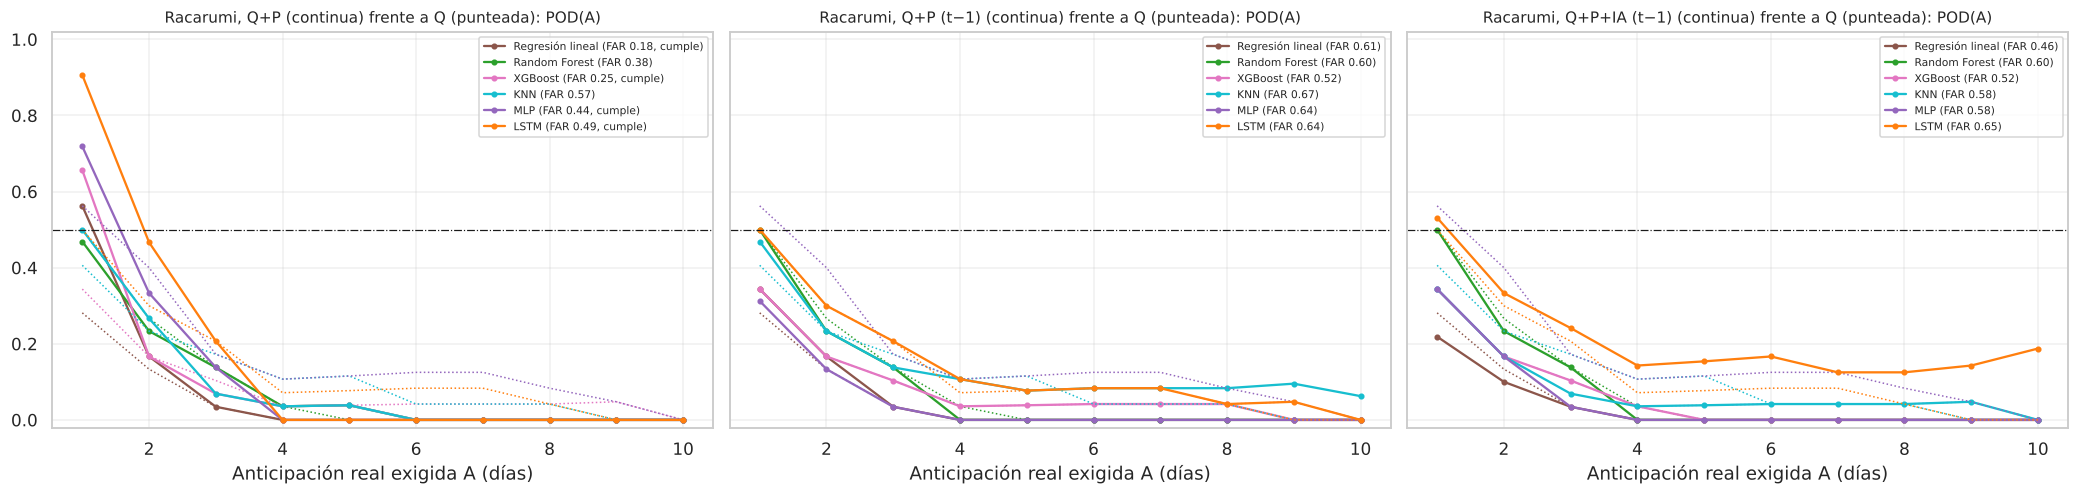

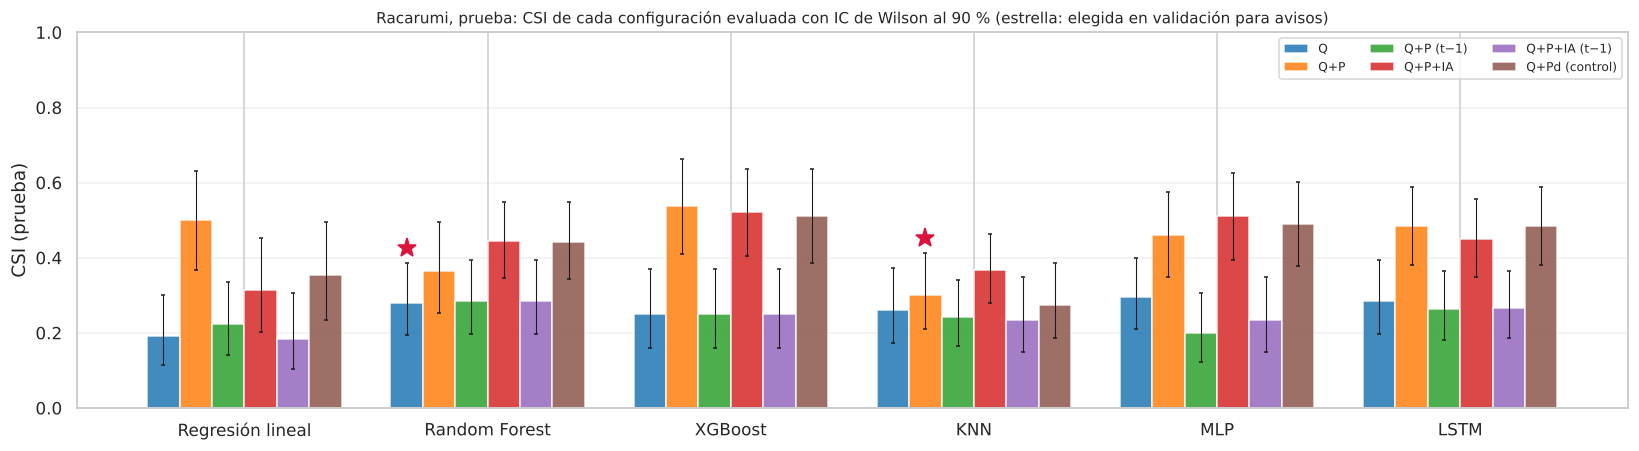

,P95 (m³/s),cruces evaluables 2009–2011 (regla),cruces evaluables 2012–2015 (comparación),cruces evaluables en la prueba
estación,,,,
Racarumi,111.206489,13,14,32
Tamshiyacu,47602.819185,2,3,3


cruces  detectados con  \
entrada                            modelo                                     
P                                  Regresión lineal      32              18   
                                   Random Forest         32              15   
                                   XGBoost               32              21   
                                   KNN                   32              16   
                                   MLP                   32              23   
                                   LSTM                  32              29   
IA sobre P                         Regresión lineal      32              11   
                                   Random Forest         32              28   
                                   XGBoost               32              25   
                                   KNN                   32              26   
                                   MLP                   32              24   
                                   LSTM                  32              27   
P con latencia 1 d                 Regresión lineal      32              11   
                                   Random Forest         32              16   
                                   XGBoost               32              11   
                                   KNN                   32              15   
                                   MLP                   32              10   
                                   LSTM                  32              16   
retraso de P (t−1 frente a t)      Regresión lineal      32              11   
                                   Random Forest         32              16   
                                   XGBoost               32              11   
                                   KNN                   32              15   
                                   MLP                   32              10   
                                   LSTM                  32              16   
P + IA con latencia 1 d            Regresión lineal      32               7   
                                   Random Forest         32              16   
                                   XGBoost               32              11   
                                   KNN                   32              11   
                                   MLP                   32              11   
                                   LSTM                  32              17   
IA sobre P, latencia 1 d           Regresión lineal      32               7   
                                   Random Forest         32              16   
                                   XGBoost               32              11   
                                   KNN                   32              11   
                                   MLP                   32              11   
                                   LSTM                  32              17   
retraso de P + IA (t−1 frente a t) Regresión lineal      32               7   
                                   Random Forest         32              16   
                                   XGBoost               32              11   
                                   KNN                   32              11   
                                   MLP                   32              11   
                                   LSTM                  32              17   
P diaria (Pd) frente a P           Regresión lineal      32              12   
                                   Random Forest         32              27   
                                   XGBoost               32              21   
                                   KNN                   32              14   
                                   MLP                   32              25   
                                   LSTM                  32              29   

                                                     detectados sin  \
entrada                        

In [25]:
avisos_entrada = I.avisos_efecto_entrada(AVI, COMPARACIONES_E['Racarumi'], MODELOS)
avisos_entrada.to_csv(RUTA_TAB / 'tabla_avisos_efecto_entrada.csv', index=False)
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6), sharey=True)
for a, (conj, lat) in zip(ax, [('Q+P', 0), ('Q+P', 1), ('Q+P+IA', 1)]):
    for n in MODELOS:
        pa = AVI[(conj, lat, n, 'común')]['por_A']; r_ = AVI[(conj, lat, n, 'común')]['resumen']
        a.plot(pa.index[:10], pa['POD'].iloc[:10], '-o', ms=3, color=C.COLOR[n], label=f"{n} (FAR {r_['FAR']:.2f}{', cumple' if r_['anticipacion_util'] else ''})")
        pq = AVI[('Q', 0, n, 'común')]['por_A']
        a.plot(pq.index[:10], pq['POD'].iloc[:10], ':', color=C.COLOR[n], lw=1)
    a.axhline(AV['pod_min'], color='k', lw=0.8, ls='-.'); a.set_ylim(-0.02, 1.02); a.grid(True, alpha=0.3)
    a.set_title(f"Racarumi, {I.etiqueta(conj, lat)} (continua) frente a Q (punteada): POD(A)", fontsize=10); a.set_xlabel('Anticipación real exigida A (días)')
    a.legend(fontsize=7)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig09_avisos_racarumi.png', dpi=200, bbox_inches='tight'); plt.show()
fig, a = plt.subplots(figsize=(15, 4.2))
cs = CONJ['Racarumi']
w = 0.8 / len(cs)
for k, (c, l) in enumerate(cs):
    s = av_c.loc[I.etiqueta(c, l)].loc[MODELOS]
    xx = np.arange(len(MODELOS)) + (k - (len(cs) - 1) / 2) * w
    a.bar(xx, s['CSI'], width=w, label=I.etiqueta(c, l), color=plt.cm.tab10(k), alpha=0.85)
    a.errorbar(xx, s['CSI'], yerr=[s['CSI'] - s['CSI IC90 inferior'], s['CSI IC90 superior'] - s['CSI']], fmt='none', ecolor='k', capsize=1.5, lw=0.7)
    for esc, kk in SEL_AV.items():
        if (kk[0], kk[1]) == (c, l):
            a.plot(xx[MODELOS.index(kk[2])], s.loc[kk[2], 'CSI IC90 superior'] + 0.04, '*', color='crimson', ms=13)
a.set_xticks(range(len(MODELOS))); a.set_xticklabels(MODELOS); a.set_ylabel('CSI (prueba)'); a.set_ylim(0, 1); a.grid(True, axis='y', alpha=0.3)
a.legend(fontsize=8, ncol=3); a.set_title('Racarumi, prueba: CSI de cada configuración evaluada con IC de Wilson al 90 % (estrella: elegida en validación para avisos)', fontsize=10)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig10_avisos_csi_racarumi.png', dpi=200, bbox_inches='tight'); plt.show()
cruces = pd.DataFrame([I.conteo_cruces(EXP[e]) for e in EST]).set_index('estación')
cruces.to_csv(RUTA_TAB / 'tabla_cruces_evaluables.csv')
display(cruces)
avisos_entrada.set_index(['entrada', 'modelo']).round(3)

**Figuras 9 y 10.** Racarumi, prueba: POD(A) de los seis modelos con Q+P, Q+P (t−1) y Q+P+IA (t−1) (continua) frente a Q (punteada), con la FAR de cada sistema; y CSI de cada configuración evaluada con su IC de Wilson al 90 %. La estrella marca la configuración elegida en validación para avisos. La tabla cuenta los cruces evaluables de cada bloque en las dos estaciones.

**Interpretación:**
- **La validación tiene muy pocos cruces para elegir un sistema de avisos:** 13 cruces evaluables en 2009–2011 (para fijar la regla) y 14 en 2012–2015 (para comparar candidatos). Con 14 cruces, una diferencia de CSI de 0.03–0.06 es uno o dos aciertos.
- **Selección principal (regla calibrada en 2009–2011, candidatos comparados en 2012–2015):** con datos del mismo día elige **Q+P · KNN** (CSI 0.68 en 2012–2015, 13 de 14 cruces), seguida de cerca por Q+P+IA · LSTM (0.65) y Q+P+IA · XGBoost (0.63). En la prueba, Q+P · KNN detecta 16 de 32 cruces con FAR 0.57: **no cumple el criterio**. Con un día de retraso elige Q · Random Forest (empatada con otras seis en CSI 0.50): 16 de 32, FAR 0.61, tampoco.
- **Selección sin separar los bloques (optimista):** elegía Q+P · MLP, que en la prueba cumple con los valores puntuales (23 de 32, FAR 0.44). Que la elección cambie al separar los bloques, y que la principal falle en la prueba, muestra que **con 27 cruces de validación no se puede elegir de forma confiable un sistema de avisos**. La configuración elegida para la magnitud (Q+P+IA · LSTM) tampoco cumple en la prueba (FAR 0.51).
- **Figuras 9 y 10:** con la lluvia del mismo día todas las curvas de POD suben a 1 día (0.47–0.91), pero **solo cuatro configuraciones cumplen el criterio puntual** (regresión lineal, XGBoost, MLP y LSTM); todas caen bajo 0.5 a 2 días. Con un día de retraso, las curvas vuelven al nivel de solo caudal y las FAR suben a 0.46–0.67.
- **Prueba pareada por evento:** con la lluvia hasta t, la regresión lineal detecta 9 cruces más (p = 0.004), XGBoost 10 más (p = 0.002) y la LSTM 13 más (p < 0.001); el MLP 6 más y 1 menos (p = 0.13, no demostrado). Retrasar la lluvia un día hace perder 8–13 cruces a la regresión lineal, XGBoost, el MLP y la LSTM (p ≤ 0.04). Los índices dan a Random Forest y al KNN 13 y 10 detecciones más, pero con 22 y 18 falsas alarmas más: detectan más porque avisan más.
- **Tamshiyacu:** 2 cruces evaluables en 2009–2011, 2 en 2012–2015 y 3 en la prueba: no se selecciona ni se evalúa un sistema de avisos.
- **Conclusión:** la evidencia de 1 día de aviso con lluvia del mismo día viene de que **varias** configuraciones lo alcanzan en la prueba (con los IC, solo XGBoost), **no de un sistema seleccionado en validación** que lo garantice. Elegir ahora el que mejor resultó en la prueba sería elegir con la prueba. La selección final del proyecto, con Chronos-2 y las estaciones aguas arriba como candidatos, está en el cuaderno 08.

---
## 9. Muestra extendida por horizonte
Para cada configuración y horizonte, la muestra común (emisiones con los 30 caudales futuros, la que permite comparar horizontes en las mismas fechas) frente a la extendida (todas las emisiones con entrada válida; cada horizonte con los objetivos que existan): emisiones, NSE y habilidad frente a persistencia y climatología (hasta 2015). H no se recalcula en la extendida porque su bootstrap conjunto exige los 30 horizontes.

In [26]:
ext = pd.concat([I.muestra_extendida(EXP[e], P[e]) for e in EST], ignore_index=True)
ext.drop(columns='banda').to_csv(RUTA_TAB / 'tabla_muestra_extendida.csv', index=False)
res_ext = I.resumen_extendida(ext)
res_ext.round(3)

combinaciones  emisiones_extendida_medias  \
estación   banda                                                   
Racarumi   1–3 días              108                    2778.333   
           4–7 días              144                    2774.500   
           8–15 días             288                    2768.625   
           16–30 días            540                    2757.067   
Tamshiyacu 1–3 días               90                    3418.000   
           4–7 días              120                    3413.250   
           8–15 días             240                    3406.500   
           16–30 días            450                    3394.000   

                       ΔNSE_mediana  ΔNSE_min  ΔNSE_max  \
estación   banda                                          
Racarumi   1–3 días           0.004     0.001     0.006   
           4–7 días           0.007     0.004     0.011   
           8–15 días          0.006     0.002     0.012   
           16–30 días        -0.007    -0.028     0.013   
Tamshiyacu 1–3 días           0.000     0.000     0.001   
           4–7 días           0.001     0.000     0.002   
           8–15 días          0.004     0.002     0.006   
           16–30 días         0.006     0.003     0.011   

                       habilidad_cambia_de_signo  
estación   banda                                  
Racarumi   1–3 días                            0  
           4–7 días                            0  
           8–15 días                          12  
           16–30 días                         32  
Tamshiyacu 1–3 días                            0  
           4–7 días                            0  
           8–15 días                           0  
           16–30 días                          3

**Interpretación:**
- **Alcance:** 66 combinaciones × 30 horizontes. La extendida agrega, por horizonte, unas 240 emisiones en Racarumi y 150 en Tamshiyacu.
- **1–15 días: la muestra extendida no cambia las conclusiones** (NSE +0.001 a +0.012 en Racarumi y 0.000 a +0.006 en Tamshiyacu).
- **16–30 días:** en Racarumi el NSE de la extendida es algo más bajo, sobre todo a 30 días (−0.028 a +0.013, mediana −0.007): la muestra común es algo favorable a esos plazos. En Tamshiyacu es más alto (+0.003 a +0.011).
- **Signo de la habilidad:** cambia en 44 de 1 080 filas de Racarumi (a 9–30 días, con habilidad frente a la climatología entre −0.02 y +0.02, donde ningún modelo es útil) y en 3 de 900 de Tamshiyacu (a 27–30 días): no cambia ningún horizonte útil de Racarumi (≤ 7 días).

---
## 10. Escenario idealizado: lluvia futura perfecta (XGBoost y regresión lineal), aparte de toda selección
**Escenario idealizado:** cuánto cambia el pronóstico si se conociera la lluvia **observada** de t + 1 a t + h, que equivale a un pronóstico de lluvia sin error. Necesita **un modelo por horizonte** (el de h días recibe la lluvia de t + 1 … t + h), que el proyecto tiene implementado y verificado **solo para XGBoost y la regresión lineal** (`lluvia.PorHorizonte`); no se presenta como evaluado con los seis modelos. Con esos dos modelos se ajustan tres variantes en las mismas filas: **solo caudal**, **+ lluvia observada hasta t** (referencia del mismo estimador) y **+ lluvia futura observada**. Se informan la ganancia por bandas, el horizonte útil y los avisos de Racarumi con la lluvia futura.
**No participa en ninguna selección:** no es una configuración utilizable al emitir; mide el beneficio de esa información con estos modelos, no un límite universal.

### 10.1 Ajuste (un modelo por horizonte)

In [27]:
filas_v = []
for e in EST:
    d = D[e]
    X0, N0 = C.matriz_tabular(d['m'])
    n_ll = len(d['nom_ll'])
    d['XV'] = {BASE: (X0, N0, X0.shape[1], False),
               OBS: (np.column_stack([X0, d['Xll']]), N0 + d['nom_ll'], X0.shape[1] + n_ll, False),
               TECHO: (np.column_stack([X0, d['Xll'], d['F']]), N0 + d['nom_ll'] + [f'P(t+{k})' for k in range(1, H + 1)], X0.shape[1] + n_ll, True)}
    for v, (X, nom, npas, fut) in d['XV'].items():
        assert np.isfinite(X).all() and X.shape[1] == len(nom), (e, v)
        filas_v.append({'estación': e, 'variante': v, 'variables conocidas en t': npas,
                        'variables de lluvia futura (para h = 1 / 30)': f"{len(LL.futuro_para_h(d['F'], 1)[1])} / {len(LL.futuro_para_h(d['F'], 30)[1])}" if fut else '—'})
pd.DataFrame(filas_v).set_index(['estación', 'variante'])

variables conocidas en t  \
estación   variante                                                                       
Racarumi   Solo caudal                                                               32   
           + lluvia observada hasta t (disponibilidad supu...                        42   
           + lluvia futura observada (escenario idealizado)                          42   
Tamshiyacu Solo caudal                                                               32   
           + lluvia observada hasta t (disponibilidad supu...                        42   
           + lluvia futura observada (escenario idealizado)                          42   

                                                              variables de lluvia futura (para h = 1 / 30)  
estación   variante                                                                                         
Racarumi   Solo caudal                                                                                   —  
           + lluvia observada hasta t (disponibilidad supu...                                            —  
           + lluvia futura observada (escenario idealizado)                                          1 / 6  
Tamshiyacu Solo caudal                                                                                   —  
           + lluvia observada hasta t (disponibilidad supu...                                            —  
           + lluvia futura observada (escenario idealizado)                                          1 / 6

In [28]:
filas_aj, MEJORES = [], {}
for e in EST:
    d = D[e]
    m, p, VC = d['m'], d['p'], d['VC']
    ie, iv = p['ent'], p['val']
    for v, (X, _, npas, fut) in d['XV'].items():
        for mod in MODELOS_LL:
            t0 = time.time()
            sub = LL.ajustar_malla_h(mod, X[ie], m.y[ie], X[iv], VC.a_q, VC.obs_sel, npas, fut)
            for f in sub:
                f.update(estación=e, variante=v)
            filas_aj += sub
            mejor = max(sub, key=lambda f: f['NSE_val'])
            MEJORES[(e, v, mod)] = json.loads(mejor['parametros'])
            print(f"{e:10s} {v:32s} {mod:17s} {len(sub):2d} combinaciones | mejor NSE medio selección = {mejor['NSE_val']:.4f} "
                  f"con {MEJORES[(e, v, mod)]} ({time.time() - t0:,.0f} s)", flush=True)
aj = pd.DataFrame(filas_aj)
aj.to_csv(RUTA_TAB / 'tabla_ajuste_hiperparametros.csv', index=False)

Racarumi   Solo caudal                      XGBoost           24 combinaciones | mejor NSE medio selección = 0.5333 con {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 1.0, 'n_estimators': 200} (219 s)


Racarumi   Solo caudal                      Regresión lineal   1 combinaciones | mejor NSE medio selección = 0.5523 con {} (0 s)


Racarumi   + lluvia observada hasta t (disponibilidad supuesta) XGBoost           24 combinaciones | mejor NSE medio selección = 0.5390 con {'max_depth': 6, 'learning_rate': 0.05, 'reg_lambda': 10.0, 'n_estimators': 100} (279 s)


Racarumi   + lluvia observada hasta t (disponibilidad supuesta) Regresión lineal   1 combinaciones | mejor NSE medio selección = 0.5422 con {} (0 s)


Racarumi   + lluvia futura observada (escenario idealizado) XGBoost           24 combinaciones | mejor NSE medio selección = 0.8619 con {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 1.0, 'n_estimators': 400} (313 s)


Racarumi   + lluvia futura observada (escenario idealizado) Regresión lineal   1 combinaciones | mejor NSE medio selección = 0.7985 con {} (1 s)


... (2 outputs left out)

Tamshiyacu + lluvia observada hasta t (disponibilidad supuesta) XGBoost           24 combinaciones | mejor NSE medio selección = 0.9368 con {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 1.0, 'n_estimators': 100} (244 s)


Tamshiyacu + lluvia observada hasta t (disponibilidad supuesta) Regresión lineal   1 combinaciones | mejor NSE medio selección = 0.9111 con {} (0 s)


Tamshiyacu + lluvia futura observada (escenario idealizado) XGBoost           24 combinaciones | mejor NSE medio selección = 0.9382 con {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 10.0, 'n_estimators': 100} (259 s)


Tamshiyacu + lluvia futura observada (escenario idealizado) Regresión lineal   1 combinaciones | mejor NSE medio selección = 0.9124 con {} (0 s)


In [29]:
PRED, NSE_SEL = {}, {}
for e in EST:
    d = D[e]
    m, p, VC = d['m'], d['p'], d['VC']
    ie, iv, ip = p['ent'], p['val'], p['pru']
    it = np.concatenate([ie, iv])
    for v, (X, _, npas, fut) in d['XV'].items():
        for mod in MODELOS_LL:
            t0 = time.time()
            k = (e, v, mod)
            sems = C.SEMILLAS if mod in C.ESTOCASTICOS else [C.SEMILLA]
            yv_s, yp_s = [], []
            for s in sems:
                yv_s.append(LL.PorHorizonte(mod, MEJORES[k], s, npas, fut).fit(X[ie], m.y[ie]).predict(X[iv]))
                mf = LL.PorHorizonte(mod, MEJORES[k], s, npas, fut).fit(X[it], m.y[it])
                yp_s.append(mf.predict(X[ip]))
            yv, yp = np.mean(yv_s, 0), np.mean(yp_s, 0)
            fac = C.factor_duan(m.y[iv], yv)
            PRED[k] = dict(sel=VC.a_q(yv), val_med=C.a_caudal(m, yv, iv), pru=C.a_caudal(m, yp, ip, fac), pru_med=C.a_caudal(m, yp, ip), factor=fac)
            NSE_SEL[k] = C.nse_medio(PRED[k]['sel'], VC.obs_sel)
            print(f"{e:10s} {v:32s} {mod:17s} NSE medio selección = {NSE_SEL[k]:.4f} | factor Duan h=1/30 = {fac[0]:.4f}/{fac[-1]:.4f} "
                  f"({time.time() - t0:,.0f} s)", flush=True)
guardar = {}
for e in EST:
    d = D[e]
    guardar[f'{e}_fechas_val'] = d['m'].fechas[d['p']['val']].values.astype('datetime64[D]')
    guardar[f'{e}_fechas_pru'] = d['m'].fechas[d['p']['pru']].values.astype('datetime64[D]')
    guardar[f'{e}_obs_pru'] = d['m'].q_obs[d['p']['pru']]
    for v in VARIANTES:
        for mod in MODELOS_LL:
            s = f"{e}_{VARIANTES.index(v)}_{C.SLUG[mod]}"
            guardar[f'{s}_pru'] = PRED[(e, v, mod)]['pru'].astype('float32')
            guardar[f'{s}_prumed'] = PRED[(e, v, mod)]['pru_med'].astype('float32')
            guardar[f'{s}_valmed'] = PRED[(e, v, mod)]['val_med'].astype('float32')
guardar['variantes'] = np.array(VARIANTES)
np.savez_compressed(RUTA_SAL / 'predicciones_idealizado.npz', **guardar)

Racarumi   Solo caudal                      XGBoost           NSE medio selección = 0.5321 | factor Duan h=1/30 = 1.0304/1.2420 (34 s)


Racarumi   Solo caudal                      Regresión lineal  NSE medio selección = 0.5523 | factor Duan h=1/30 = 1.0337/1.2862 (1 s)


Racarumi   + lluvia observada hasta t (disponibilidad supuesta) XGBoost           NSE medio selección = 0.5377 | factor Duan h=1/30 = 1.0203/1.2717 (90 s)


Racarumi   + lluvia observada hasta t (disponibilidad supuesta) Regresión lineal  NSE medio selección = 0.5422 | factor Duan h=1/30 = 1.0277/1.3242 (1 s)


Racarumi   + lluvia futura observada (escenario idealizado) XGBoost           NSE medio selección = 0.8644 | factor Duan h=1/30 = 1.0191/1.0773 (88 s)


Racarumi   + lluvia futura observada (escenario idealizado) Regresión lineal  NSE medio selección = 0.7985 | factor Duan h=1/30 = 1.0277/1.1537 (1 s)


... (2 outputs left out)

Tamshiyacu + lluvia observada hasta t (disponibilidad supuesta) XGBoost           NSE medio selección = 0.9372 | factor Duan h=1/30 = 0.9997/1.0095 (26 s)


Tamshiyacu + lluvia observada hasta t (disponibilidad supuesta) Regresión lineal  NSE medio selección = 0.9111 | factor Duan h=1/30 = 0.9997/1.0133 (1 s)


Tamshiyacu + lluvia futura observada (escenario idealizado) XGBoost           NSE medio selección = 0.9383 | factor Duan h=1/30 = 0.9997/0.9929 (27 s)


Tamshiyacu + lluvia futura observada (escenario idealizado) Regresión lineal  NSE medio selección = 0.9124 | factor Duan h=1/30 = 0.9997/0.9918 (1 s)


**Coherencia de los dos caminos de cálculo:** la regresión lineal de un modelo por horizonte de esta sección y la multisalida de la sección 4 (`entradas.py`) deben dar los mismos pronósticos con Q y con Q+P.

In [30]:
filas = []
for e in EST:
    for (conj, lat), v in [(('Q', 0), BASE), (('Q+P', 0), OBS)]:
        a_, b_ = P[e][(conj, lat, 'Regresión lineal')]['pru'], PRED[(e, v, 'Regresión lineal')]['pru']
        assert np.allclose(a_, b_, rtol=1e-6, atol=1e-6), (e, conj)
        filas.append({'estación': e, 'control': f'regresión lineal {I.etiqueta(conj, lat)}: multisalida (sección 4) = un modelo por horizonte (sección 10)',
                      'máx |diferencia| (m³/s)': float(np.abs(a_ - b_).max())})
cohe2 = pd.DataFrame(filas).set_index(['estación', 'control'])
cohe2.to_csv(RUTA_TAB / 'tabla_coherencia_caminos.csv')
cohe2

máx |diferencia| (m³/s)
estación   control                                                                    
Racarumi   regresión lineal Q: multisalida (sección 4) = u...                 0.000008
           regresión lineal Q+P: multisalida (sección 4) =...                 0.000010
Tamshiyacu regresión lineal Q: multisalida (sección 4) = u...                 0.001038
           regresión lineal Q+P: multisalida (sección 4) =...                 0.000907

### 10.2 Magnitud y horizonte útil con la lluvia futura perfecta
En las mismas emisiones de prueba: NSE por horizonte, horizonte útil (cota 95 %) y ganancia G por bandas con IC 90 % de la lluvia futura frente a solo caudal y frente a la lluvia observada hasta t, con XGBoost y la regresión lineal.

In [31]:
TAB, filas_m, REF = {}, [], {}
GH, GB = {}, []
for e in EST:
    d = D[e]
    m, ip = d['m'], d['p']['pru']
    obs, fp = m.q_obs[ip], m.fechas[ip]
    pers, clim = C.pred_persistencia(m, ip), C.pred_climatologia(m, ip, C.climatologia_referencia(d['q'], 'prueba'))
    REF[e] = dict(obs=obs, pers=pers, clim=clim, f=fp)
    for mod in MODELOS_LL:
        for v in VARIANTES:
            k = (e, v, mod)
            TAB[k] = C.tabla_metricas(obs, PRED[k]['pru'], pers, clim)
            hz = C.horizontes(TAB[k], C.bootstrap_curvas(fp, obs, PRED[k]['pru'], pers, clim, B=B))
            filas_m.append({'estación': e, 'modelo': mod, 'variante': v, 'H cota 95 % (d)': hz['H_cota'], 'H puntual (d)': hz['H_puntual'],
                            'NSE medio': C.nse_medio(PRED[k]['pru'], obs), **{f'NSE h={h}': TAB[k].loc[h, 'NSE'] for h in (1, 3, 7, 15, 30)}})
        for v, ref in COMPARACIONES:
            GH[(e, mod, v, ref)], gb = A.ganancia(fp, obs, PRED[(e, v, mod)]['pru'], PRED[(e, ref, mod)]['pru'], B=B)
            GB.append(gb.assign(estación=e, modelo=mod, comparación=f'{v} frente a {ref}').reset_index())
met_id = pd.DataFrame(filas_m).set_index(['estación', 'modelo', 'variante'])
met_id.to_csv(RUTA_TAB / 'tabla_idealizado_metricas.csv')
gan_b = pd.concat(GB).set_index(['estación', 'modelo', 'comparación', 'banda'])
gan_b.to_csv(RUTA_TAB / 'tabla_idealizado_ganancia_bandas.csv')
display(met_id.round(3))
(gan_b.assign(G_IC=lambda t: t.apply(lambda r: f"{r['G'] * 100:+.0f} % [{r['IC90 inferior'] * 100:+.0f}, {r['IC90 superior'] * 100:+.0f}]", axis=1))['G_IC']
      .unstack('banda')[I.BANDAS])

H cota 95 % (d)  \
estación   modelo           variante                                                              
Racarumi   XGBoost          Solo caudal                                                       6   
                            + lluvia observada hasta t (disponibilidad supu...                6   
                            + lluvia futura observada (escenario idealizado)                 30   
           Regresión lineal Solo caudal                                                       5   
                            + lluvia observada hasta t (disponibilidad supu...                4   
                            + lluvia futura observada (escenario idealizado)                 30   
Tamshiyacu XGBoost          Solo caudal                                                      30   
                            + lluvia observada hasta t (disponibilidad supu...               30   
                            + lluvia futura observada (escenario idealizado)                 30   
           Regresión lineal Solo caudal                                                      21   
                            + lluvia observada hasta t (disponibilidad supu...               25   
                            + lluvia futura observada (escenario idealizado)                 30   

                                                                                H puntual (d)  \
estación   modelo           variante                                                            
Racarumi   XGBoost          Solo caudal                                                     8   
                            + lluvia observada hasta t (disponibilidad supu...              8   
                            + lluvia futura observada (escenario idealizado)               30   
           Regresión lineal Solo caudal                                                     7   
                            + lluvia observada hasta t (disponibilidad supu...              6   
                            + lluvia futura observada (escenario idealizado)               30   
Tamshiyacu XGBoost          Solo caudal                                                    30   
                            + lluvia observada hasta t (disponibilidad supu...             30   
                            + lluvia futura observada (escenario idealizado)               30   
           Regresión lineal Solo caudal                                                    26   
                            + lluvia observada hasta t (disponibilidad supu...             30   
                            + lluvia futura observada (escenario idealizado)               30   

                                                                                NSE medio  \
estación   modelo           variante                                                        
Racarumi   XGBoost          Solo caudal                                             0.489   
                            + lluvia observada hasta t (disponibilidad supu...      0.485   
                            + lluvia futura observada (escenario idealizado)        0.821   
           Regresión lineal Solo caudal                                             0.485   
                            + lluvia observada hasta t (disponibilidad supu...      0.483   
                            + lluvia futura observada (escenario idealizado)        0.736   
Tamshiyacu XGBoost          Solo caudal                                             0.913   
                            + lluvia observada hasta t (disponibilidad supu...      0.917   
                            + lluvia futura observada (escenario idealizado)        0.930   
           Regresión lineal Solo caudal                                             0.884   
                            + lluvia observada hasta t (disponibilidad supu...      0.900   
                            + lluvia futura observada (escenario idealizado)        0.922   

                               

banda                                                                                   1–3 días  \
estación   modelo           comparación                                                            
Racarumi   Regresión lineal + lluvia futura observada (escenario idealizado...  +35 % [+28, +45]   
                            + lluvia futura observada (escenario idealizado...  +43 % [+29, +58]   
                            + lluvia observada hasta t (disponibilidad supu...   +12 % [+1, +24]   
           XGBoost          + lluvia futura observada (escenario idealizado...  +55 % [+50, +60]   
                            + lluvia futura observada (escenario idealizado...  +65 % [+60, +71]   
                            + lluvia observada hasta t (disponibilidad supu...  +22 % [+18, +28]   
Tamshiyacu Regresión lineal + lluvia futura observada (escenario idealizado...     +0 % [-0, +0]   
                            + lluvia futura observada (escenario idealizado...   +10 % [+8, +12]   
                            + lluvia observada hasta t (disponibilidad supu...   +10 % [+8, +12]   
           XGBoost          + lluvia futura observada (escenario idealizado...     -1 % [-1, -0]   
                            + lluvia futura observada (escenario idealizado...    +9 % [+7, +11]   
                            + lluvia observada hasta t (disponibilidad supu...    +9 % [+8, +11]   

banda                                                                                   4–7 días  \
estación   modelo           comparación                                                            
Racarumi   Regresión lineal + lluvia futura observada (escenario idealizado...  +48 % [+42, +58]   
                            + lluvia futura observada (escenario idealizado...  +45 % [+35, +58]   
                            + lluvia observada hasta t (disponibilidad supu...    -6 % [-13, +3]   
           XGBoost          + lluvia futura observada (escenario idealizado...  +68 % [+64, +73]   
                            + lluvia futura observada (escenario idealizado...  +69 % [+65, +74]   
                            + lluvia observada hasta t (disponibilidad supu...     +3 % [+1, +5]   
Tamshiyacu Regresión lineal + lluvia futura observada (escenario idealizado...     +0 % [-1, +1]   
                            + lluvia futura observada (escenario idealizado...  +17 % [+13, +21]   
                            + lluvia observada hasta t (disponibilidad supu...  +17 % [+13, +20]   
           XGBoost          + lluvia futura observada (escenario idealizado...     -0 % [-1, +0]   
                            + lluvia futura observada (escenario idealizado...   +12 % [+9, +15]   
                            + lluvia observada hasta t (disponibilidad supu...   +12 % [+9, +15]   

banda                                                                                  8–15 días  \
estación   modelo           comparación                                                            
Racarumi   Regresión lineal + lluvia futura observada (escenario idealizado...  +53 % [+50, +58]   
                            + lluvia futura observada (escenario idealizado...  +51 % [+45, +57]   
                            + lluvia observada hasta t (disponibilidad supu...    -5 % [-12, +2]   
           XGBoost          + lluvia futura observada (escenario idealizado...  +70 % [+65, +73]   
                            + lluvia futura observada (escenario idealizado...  +69 % [+65, +73]   
                            + lluvia observada hasta t (disponibilidad supu...     -2 % [-5, +2]   
Tamshiyacu Regresión lineal + lluvia futura observada (escenario idealizado...   +10 % [+6, +13]   
                            + lluvia futura observada (escenario idealizado...  +27 % [+20, +32]   
                            + lluvia observada hasta t (disponibilidad supu...  +18 % [+14, +22]   
           XGBoost          + lluvia futura observada (escenario idealizado...    +7 % [+5, +10]  

**Figura 11.** NSE por horizonte en la prueba con XGBoost (continua) y la regresión lineal (discontinua), un modelo por horizonte: solo caudal, + lluvia observada hasta t y + lluvia futura observada (idealizado), con la persistencia y la climatología.

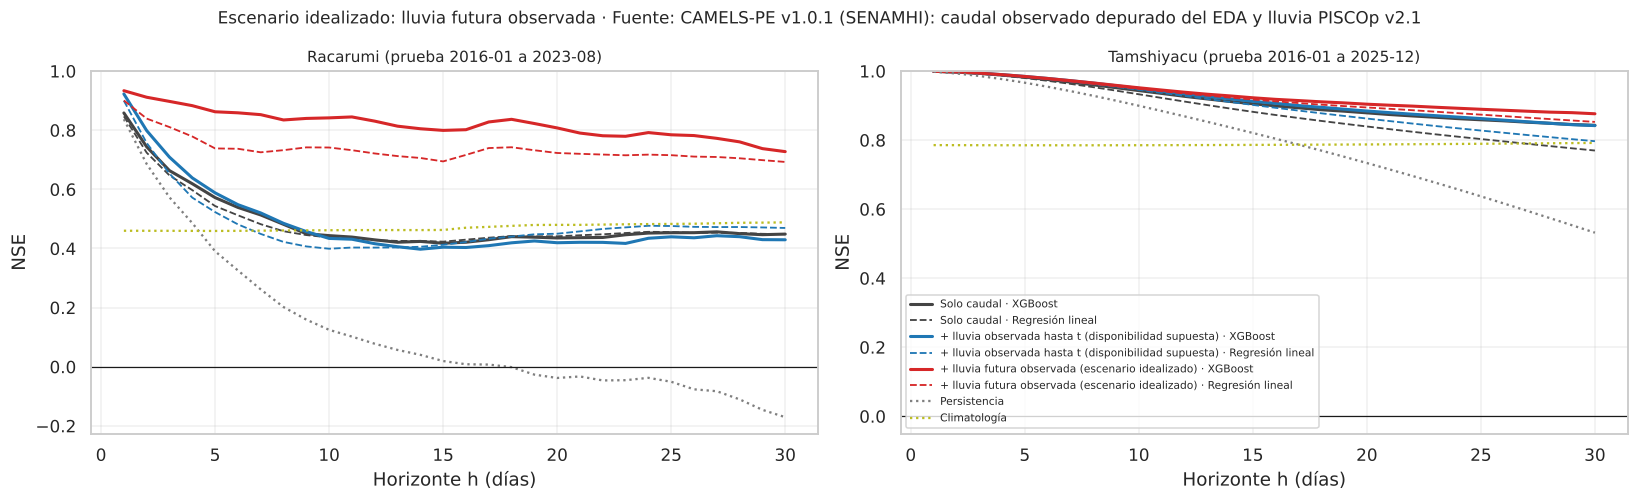

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for a, e in zip(ax, EST):
    for v in VARIANTES:
        for mod, ls in [('XGBoost', '-'), ('Regresión lineal', '--')]:
            a.plot(hh, TAB[(e, v, mod)]['NSE'], color=COLV[v], ls=ls, lw=2 if mod == 'XGBoost' else 1.2, label=f'{v} · {mod}')
    tp = C.tabla_metricas(REF[e]['obs'], REF[e]['pers'], REF[e]['pers'], REF[e]['clim'])
    tc = C.tabla_metricas(REF[e]['obs'], REF[e]['clim'], REF[e]['pers'], REF[e]['clim'])
    a.plot(hh, tp['NSE'], color=C.COLOR['Persistencia'], ls=':', lw=1.5, label='Persistencia')
    a.plot(hh, tc['NSE'], color=C.COLOR['Climatología'], ls=':', lw=1.5, label='Climatología')
    a.axhline(0, color='k', lw=0.8)
    a.set_ylim(max(-0.5, a.get_ylim()[0]), 1.0); a.set_xlabel('Horizonte h (días)'); a.set_ylabel('NSE'); a.grid(True, alpha=0.3)
    a.set_title(f"{e} (prueba {REF[e]['f'].min():%Y-%m} a {REF[e]['f'].max():%Y-%m})", fontsize=10)
ax[1].legend(fontsize=7, loc='lower left', ncol=1)
fig.suptitle('Escenario idealizado: lluvia futura observada · ' + FUENTE, fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig11_idealizado_nse_horizonte.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación (escenario idealizado, aparte de las selecciones):**
- **Coherencia:** la regresión lineal de un modelo por horizonte da los mismos pronósticos que la multisalida de la sección 4 (diferencia máxima 0.001 m³/s): los dos caminos de cálculo son coherentes, y la lluvia observada hasta t de esta sección es la misma de las secciones 4–9.
- **Racarumi:** en este escenario idealizado, incorporar la lluvia futura observada reduce el error **62–69 % en todas las bandas con XGBoost** (43–51 % con la regresión lineal), frente al 22 % a 1–3 días, y casi nada después, de la lluvia observada hasta t con el mismo estimador. En el escenario idealizado, el horizonte útil pasa de 5–6 días a **≥ 30 días** con los dos modelos, y el NSE a 7 días de 0.51 a 0.85 (XGBoost). **Incorporar lluvia futura observada reduce considerablemente el error en este escenario idealizado**; esto no prueba qué parte del error se debe a la lluvia futura, porque la lluvia observada sin error no está disponible al emitir y un pronóstico de lluvia real tendría su propio error.
- **Tamshiyacu:** en los primeros 7 días la lluvia futura no agrega nada a la observada (la de esos días aún no llegó a la estación; −1 a 0 %); su aporte crece con el horizonte: 7 % a 8–15 días y 19 % a 16–30 con XGBoost (10 % y 25 % con la regresión lineal). El NSE a 30 días sube de 0.843 a 0.876 (XGBoost).
- **Alcance:** solo con XGBoost y la regresión lineal, los dos modelos con un estimador por horizonte implementado y verificado; **no se presenta como evaluado con los seis modelos**. Es un potencial con un pronóstico de lluvia sin error, no lo que lograría un pronóstico meteorológico real ni un límite universal.

### 10.3 Avisos en Racarumi con la lluvia futura perfecta
Con las reglas del cuaderno 04: regla calibrada en la validación (trayectoria mediana) y evaluación en la prueba de XGBoost y la regresión lineal con la lluvia futura observada, por anticipación exigida A, con el denominador variable N_A y con el conjunto fijo de 32 cruces. Es una configuración idealizada evaluada, no un sistema elegido.

In [33]:
dR = D['Racarumi']
f_v, f_p = dR['m'].fechas[dR['p']['val']], dR['m'].fechas[dR['p']['pru']]
RES_ID, filas = {}, []
for mod in MODELOS_LL:
    cal = I.calibrar_regla(f_v, PRED[('Racarumi', TECHO, mod)]['val_med'], dR['q'], dR['P95'])
    out = RES_ID[mod] = C.evaluar_avisos(f_p, PRED[('Racarumi', TECHO, mod)]['pru_med'], dR['q'], dR['P95'], f=cal['f'], hmax=cal['hmax'],
                                         tol=AV['tol'], dmax=AV['dmax'], reinicio=AV['reinicio'])
    filas.append({'configuración': f'{mod} · {TECHO}', **I.fila_avisos(out['resumen'])})
av_id = pd.DataFrame(filas).set_index('configuración')
av_id.to_csv(RUTA_TAB / 'tabla_idealizado_avisos.csv')
por_A_id = pd.concat({mod: RES_ID[mod]['por_A'].loc[[1, 2, 3, 5, 7, 10, 15, 17]][['evaluables', 'aciertos', 'POD', 'POD_conjunto_fijo', 'CSI']]
                      for mod in MODELOS_LL}, names=['modelo', 'A'])
por_A_id.to_csv(RUTA_TAB / 'tabla_idealizado_avisos_por_A.csv')
display(av_id.drop(columns=['CSI IC90 inferior', 'CSI IC90 superior']).T)
por_A_id.round(2)

configuración,XGBoost · + lluvia futura observada (escenario idealizado),Regresión lineal · + lluvia futura observada (escenario idealizado)
f,0.9,0.9
h_max,30,15
cruces evaluables,32,32
aciertos,25,24
omisiones,7,8
falsas alarmas,14,5
POD,0.78125,0.75
POD IC90,0.64–0.88,0.61–0.85
FAR,0.358974,0.172414
FAR IC90,0.25–0.49,0.09–0.31


evaluables  aciertos   POD  POD_conjunto_fijo   CSI
modelo           A                                                      
XGBoost          1           32        25  0.78               0.78  0.54
                 2           30        23  0.77               0.72  0.52
                 3           29        22  0.76               0.69  0.51
                 5           26        17  0.65               0.53  0.42
                 7           24        15  0.62               0.47  0.39
                 10          16        10  0.62               0.31  0.33
                 15          14         8  0.57               0.25  0.29
                 17          13         8  0.62               0.25  0.30
Regresión lineal 1           32        24  0.75               0.75  0.65
                 2           30        18  0.60               0.56  0.51
                 3           29        15  0.52               0.47  0.44
                 5           26         8  0.31               0.25  0.26
                 7           24         4  0.17               0.12  0.14
                 10          16         1  0.06               0.03  0.05
                 15          14         0  0.00               0.00  0.00
                 17          13         0  0.00               0.00  0.00

**Interpretación (configuraciones idealizadas evaluadas, no sistemas elegidos):**
- **XGBoost con la lluvia futura:** 25 de 32 cruces con 14 falsas alarmas (POD 0.78, FAR 0.36, CSI 0.54) y **anticipación útil de 17 días** según el criterio, con una carga alta (~38 días con aviso por año). **Cuidado con la cifra:** a A = 17 solo 13 de los 32 cruces tienen emisiones elegibles 17 días antes, y se anticipan 8 (POD 8/13 = 0.62); **con el conjunto fijo de 32 cruces la anticipación útil es 6 días** (POD 0.53 a 5 días y 0.47 a 7). La anticipación mediana (9 días) resume los 25 cruces detectados.
- **Regresión lineal con la lluvia futura:** 24 de 32 con 5 falsas alarmas (CSI 0.65) y anticipación útil de 4 días (2 con el conjunto fijo).
- **Lectura:** con un pronóstico de lluvia de una semana sin error, avisos de 3–5 días serían posibles para alrededor de la mitad de los cruces. Es un potencial con estos modelos si la lluvia se conociera días antes, algo que ningún pronóstico meteorológico ofrece hoy sin error.

---
## 11. Tabla maestra, salidas y resumen
Tabla maestra: una fila por estación, configuración y modelo con su disponibilidad, periodos, NSE medio de selección y de prueba, horizonte útil, papel en las selecciones (por configuración de entradas, por escenario para la magnitud y para avisos) y, en Racarumi, los avisos de la prueba. Los pronósticos de los seis modelos se guardan en `salidas/lluvia/predicciones.npz` (el 07 y el 08 comprueban con él las emisiones; el 08 reutiliza los ajustes por la caché) y el resumen en `salidas/lluvia/resumen.json`.

In [34]:
maestra = pm.merge(val[['estación', 'conjunto', 'modelo', 'NSE medio selección']], on=['estación', 'conjunto', 'modelo'])
maestra['ajuste'] = 'hasta 2008 (validación) / hasta 2015 (prueba)'
maestra['seleccionado en su configuración de entradas (magnitud)'] = [
    any(SELM[r['estación']][k] == r['modelo'] for k in SELM[r['estación']] if I.etiqueta(*k) == r['conjunto']) for _, r in maestra.iterrows()]
maestra['seleccionado en un escenario (magnitud)'] = [', '.join(esc for (e_, esc), k in CONFIG.items() if e_ == r['estación'] and I.nombre(k) == f"{r['conjunto']} · {r['modelo']}")
                                                      for _, r in maestra.iterrows()]
maestra['seleccionado en un escenario (avisos)'] = [', '.join(esc for esc, k in SEL_AV.items() if r['estación'] == 'Racarumi' and I.nombre(k) == f"{r['conjunto']} · {r['modelo']}")
                                                    for _, r in maestra.iterrows()]
maestra = maestra.merge(av_c.reset_index()[['conjunto', 'modelo', 'aciertos', 'omisiones', 'falsas alarmas', 'POD', 'FAR', 'CSI', 'anticipación útil (d)',
                                            'anticipación útil, conjunto fijo (d)']].assign(estación='Racarumi'), on=['estación', 'conjunto', 'modelo'], how='left')
maestra.to_csv(RUTA_TAB / 'tabla_maestra.csv', index=False)
guardar_e = {}
for e in EST:
    guardar_e.update(I.claves_npz(EXP[e], P[e]))
np.savez_compressed(RUTA_SAL / 'predicciones.npz', **guardar_e)
maestra[['estación', 'conjunto', 'modelo', 'emisiones', 'NSE medio selección', 'NSE medio', 'H cota 95 % (d)', 'seleccionado en un escenario (magnitud)',
         'seleccionado en un escenario (avisos)', 'aciertos', 'falsas alarmas', 'anticipación útil (d)']].set_index(['estación', 'conjunto', 'modelo']).round(3)

emisiones  NSE medio selección  \
estación   conjunto     modelo                                             
Racarumi   Q            Regresión lineal       2521                0.552   
                        Random Forest          2521                0.531   
                        XGBoost                2521                0.530   
                        KNN                    2521                0.530   
                        MLP                    2521                0.543   
...                                             ...                  ...   
Tamshiyacu Q+P+IA (t−1) Random Forest          3252                0.936   
                        XGBoost                3252                0.937   
                        KNN                    3252                0.919   
                        MLP                    3252                0.918   
                        LSTM                   3252                0.923   

                                          NSE medio  H cota 95 % (d)  \
estación   conjunto     modelo                                         
Racarumi   Q            Regresión lineal      0.485              5.0   
                        Random Forest         0.503              6.0   
                        XGBoost               0.488              6.0   
                        KNN                   0.441              4.0   
                        MLP                   0.522              6.0   
...                                             ...              ...   
Tamshiyacu Q+P+IA (t−1) Random Forest         0.912             30.0   
                        XGBoost               0.915             30.0   
                        KNN                   0.896             24.0   
                        MLP                   0.920             30.0   
                        LSTM                  0.920             30.0   

                                         seleccionado en un escenario (magnitud)  \
estación   conjunto     modelo                                                     
Racarumi   Q            Regresión lineal                                           
                        Random Forest                                              
                        XGBoost                                                    
                        KNN                                                        
                        MLP                                                        
...                                                                          ...   
Tamshiyacu Q+P+IA (t−1) Random Forest                                              
                        XGBoost                                                    
                        KNN                                                        
                        MLP                                                        
                        LSTM                                                       

                                         seleccionado en un escenario (avisos)  \
estación   conjunto     modelo                                                   
Racarumi   Q            Regresión lineal                                         
                        Random Forest                        un día de retraso   
                        XGBoost                                                  
                        KNN                                                      
                        MLP                                                      
...                                                                        ...   
Tamshiyacu Q+P+IA (t−1) Random Forest                                            
                        XGBoost                                                  
                        KNN                                                      
                        MLP                                                      
                        LSTM           

In [35]:
def limpio(v):
    return None if isinstance(v, float) and not np.isfinite(v) else v
resumen = {
    'version': C.VERSION, 'revision': C.REVISION, 'rapido': RAPIDO, 'etapa': 'precipitación con los seis modelos (cuaderno 06)',
    'experimento': EN.VERSION_EXPERIMENTO, 'huella_codigo_ajuste': EN.huella_codigo(), 'k_ipa': EN.K_IPA, 'umbral_seco_mm': EN.UMBRAL_SECO,
    'climatologia_hasta': C.CLIMATOLOGIA_HASTA, 'P95': {e: EXP[e].P95 for e in EST},
    'filas': {e: {'ent': int(len(EXP[e].p['ent'])), 'val': int(len(EXP[e].p['val'])), 'sel': int(len(EXP[e].VC.sel)), 'pru': int(len(EXP[e].p['pru']))} for e in EST},
    'conjuntos': {e: [I.etiqueta(c, l) for c, l in CONJ[e]] for e in EST}, 'conjuntos_control': [I.etiqueta(c, l) for c, l in EN.CONJUNTOS_CONTROL],
    'desfase_respuesta_dias': {e: int(resp.loc[(e, 'AR de entrenamiento'), 'desfase del máximo (d)']) for e in EST},
    'modelo_seleccionado_por_conjunto': {f'{e}|{I.etiqueta(c, l)}': SELM[e][(c, l)] for e in EST for c, l in CONJ[e]},
    'configuracion_seleccionada': {f'{e}|{esc}': I.nombre(k) for (e, esc), k in CONFIG.items()},
    'mayor_y_equivalentes': {f'{e}|{esc}': len(v) for (e, esc), v in EQUIV.items()},
    'inconclusos': {f'{e}|{esc}': len(NOPEOR[(e, esc)]) - len(v) for (e, esc), v in EQUIV.items()},
    'seleccion_avisos_racarumi': {esc: I.nombre(k) for esc, k in SEL_AV.items()},
    'seleccion_avisos_racarumi_no_anidada': {esc: I.nombre(k) for esc, k in SEL_AV_NA.items()},
    'calibracion_avisos_racarumi': {I.nombre(k): {'f': v['f'], 'hmax': int(v['hmax'])} for k, v in CAL_E.items()},
    'cruces_evaluables': {e: {k: limpio(v) for k, v in r.items()} for e, r in cruces.to_dict('index').items()},
    'nse_medio_prueba': {f"{r['estación']}|{r['conjunto']}|{r['modelo']}": round(float(r['NSE medio']), 4) for _, r in pm.iterrows()},
    'h_cota_prueba': {f"{r['estación']}|{r['conjunto']}|{r['modelo']}": int(r['H cota 95 % (d)']) for _, r in pm.iterrows()},
    'idealizado': {'modelos': MODELOS_LL, 'ganancia_bandas': {f'{e}|{mo}|{c}|{b}': round(float(r['G']), 3) for (e, mo, c, b), r in gan_b.iterrows()},
                   'h_cota': {f'{e}|{mo}|{v}': int(r['H cota 95 % (d)']) for (e, mo, v), r in met_id.iterrows()},
                   'avisos_racarumi': {mo: {k: limpio(v) for k, v in RES_ID[mo]['resumen'].items() if k in ['aciertos', 'evaluables', 'falsas_alarmas', 'FAR', 'anticipacion_util', 'anticipacion_util_conjunto_fijo']}
                                       for mo in MODELOS_LL}},
    'cache': {'politica': 'solo identidad completa idéntica; sin migración', 'combinaciones': int(len(registro)), 'leidas_de_cache': int(registro['leído de la caché'].sum())},
    'minutos': round((time.time() - T_INICIO) / 60, 1),
}
(RUTA_SAL / 'resumen.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print(json.dumps({k: resumen[k] for k in ['configuracion_seleccionada', 'seleccion_avisos_racarumi', 'cache', 'minutos']}, ensure_ascii=False, indent=1))

{
 "configuracion_seleccionada": {
  "Racarumi|mismo día": "Q+P+IA · LSTM",
  "Racarumi|un día de retraso": "Q · LSTM",
  "Tamshiyacu|mismo día": "Q · XGBoost",
  "Tamshiyacu|un día de retraso": "Q · XGBoost"
 },
 "seleccion_avisos_racarumi": {
  "mismo día": "Q+P · KNN",
  "un día de retraso": "Q · Random Forest"
 },
 "cache": {
  "politica": "solo identidad completa idéntica; sin migración",
  "combinaciones": 66,
  "leidas_de_cache": 66
 },
 "minutos": 34.8
}


---
## 12. Conclusiones

| | Racarumi (Pacífico, 2 363 km²) | Tamshiyacu (Amazonas, ~720 000 km²) |
|---|---|---|
| Desfase de máxima asociación lluvia–caudal (3.2) | **1 día** | **6–7 días** |
| + lluvia observada hasta t (disponibilidad supuesta): reducción del error con los seis modelos (prueba) | 12–27 % a 1–3 días con los seis; 5–7 % a 4–7 días con cuatro; nada después | 2–18 % con cinco (según la banda); **el KNN empeora** (−11 % a 1–3 días) |
| Horizonte útil (cota 95 %) | 6 → 7 días con Random Forest y la LSTM; 4–6 con los demás | ≥ 30 días con los no lineales; regresión lineal 21 → 25 |
| Avisos de nuevos cruces del P95 (configuraciones evaluadas) | **1 día de anticipación útil** con la regresión lineal, XGBoost, el MLP y la LSTM (solo XGBoost también con los IC); sin lluvia, ninguno | no evaluables (3 eventos) |
| Selección en validación (seis modelos) | magnitud: Q+P+IA · LSTM (mismo día; no robusta) y Q · LSTM (retraso); avisos: Q+P · KNN y Q · Random Forest, que no cumplen en la prueba | magnitud: **Q · XGBoost** en los dos escenarios (la lluvia no se adopta) |
| + lluvia disponible hasta t−1 | la ganancia casi desaparece; sin anticipación útil | conserva casi todo el efecto |
| + lluvia futura observada (idealizado, XGBoost y regresión lineal) | error −62 a −69 % en todas las bandas (XGBoost); horizonte útil ≥ 30 días; anticipación útil de 17 días con N_A variable y de 6 días sobre los 32 cruces (XGBoost) | −7 % a 8–15 días y −19 % a 16–30 días frente a la lluvia observada |

1. **La lluvia ya caída ayuda en la primera semana en Racarumi, con cualquiera de los seis modelos, y solo si se conoce la del mismo día.** El error a 1–3 días baja 12–27 % según el modelo, y cuatro configuraciones (regresión lineal, XGBoost, MLP y LSTM con Q+P) alcanzan **1 día** de anticipación útil en la prueba. Pero la selección en validación eligió Q+P · KNN para avisos, que no cumple: **la evidencia de 1 día viene de configuraciones evaluadas, no de un sistema elegido de antemano.** Con un día de retraso la mejora casi desaparece. Como no está demostrado que la lluvia del día esté disponible al emitir, este resultado es **retrospectivo**, no operativo.
2. **El modelo pesa más que la entrada en Racarumi.** Con las mismas fuentes y disponibilidad (cada familia con su representación), las redes (MLP y LSTM) tienen el mayor NSE de prueba y el KNN el menor; dar a los modelos tabulares el mismo detalle diario de lluvia que a la LSTM no cierra la diferencia. Pero XGBoost, el MLP y la LSTM reducen su error con la lluvia en la misma proporción: **las redes no aprovechan más la lluvia; son mejores con cualquier entrada.** En validación esas diferencias no se demostraban.
3. **En Tamshiyacu la lluvia aporta poco y depende del modelo.** El caudal del Amazonas tiene tanta memoria que ya se pronostica bien a 30 días. En la prueba, la lluvia de la última semana reduce el error 2–18 % con cinco de los seis modelos, también con un día de retraso, pero **aumenta el del KNN** y **empeora los caudales altos** con todos (3 crecidas, descriptivo). En validación no mostró ese aporte: con la regla fijada se elige **Q · XGBoost**, sin lluvia.
4. **Índices antecedentes (IPA y días secos):** casi una combinación lineal de los acumulados de lluvia; no dan una mejora consistente entre modelos, horizontes y estaciones, y su arranque cambia la configuración elegida en Racarumi (4.3).
5. **Incorporar lluvia futura observada reduce considerablemente el error en este escenario idealizado** (Racarumi, XGBoost y regresión lineal): con XGBoost el error baja alrededor de dos tercios y el horizonte útil pasa de 6 a 30 días o más. Es un potencial bajo esa condición, no lo que lograría un pronóstico de lluvia real, y no compite en ninguna selección.
6. **Respuesta a la pregunta del proyecto:** el aviso que puede dar un río depende del tiempo que tarda la lluvia en llegar a él. En una cuenca andina pequeña y rápida como Racarumi, es **1 día si la lluvia del día de emisión estuviera disponible**, y más solo con un **pronóstico de lluvia**. En la Amazonía, la memoria del propio río ya da semanas de pronóstico de magnitud; los avisos de nuevos cruces no se pudieron evaluar (3 eventos). **La comparación con las estaciones aguas arriba y con Chronos-2, y la selección final del proyecto, están en el cuaderno 08.**

### 12.1 Limitaciones
- **Lluvia de la cuenca y no de estaciones:** PISCOp v2.1 es una grilla que combina pluviómetros y satélite, promediada sobre la cuenca. En una cuenca andina, la lluvia local de una tormenta puede no aparecer en el promedio.
- **Disponibilidad y hora de corte:** se supuso que la lluvia del día t se conoce al emitir en t. PISCOp no se publica a tiempo, y CAMELS-PE no informa la hora de corte del acumulado diario. Si el acumulado del día t incluye la mañana de t + 1, parte de la ganancia de Racarumi usa información que en la práctica llegaría unas horas tarde. Con un día completo de retraso la ganancia de Racarumi casi desaparece.
- **El escenario idealizado no es un pronóstico:** la lluvia futura observada no tiene error. Un pronóstico real sí, y su acierto baja rápido después de pocos días. Se calcula solo con XGBoost y la regresión lineal.
- **Prueba ya consultada** durante el desarrollo del proyecto, con y sin lluvia; decisiones de diseño tomadas después de mirar datos (bloques de lluvia y log(1 + P)).
- **Selecciones frágiles:** en Racarumi las combinaciones candidatas difieren en milésimas de NSE medio y en uno o dos cruces de CSI; la selección para la magnitud cambia con el arranque del IPA y la de avisos, al separar la calibración de la regla de la comparación de candidatos. Cada IC es individual; no se corrigió por comparaciones múltiples.
- **Denominador de las métricas por anticipación:** el número de cruces evaluables baja con A (32 a 1 día, 24 a 7 días, 13 a 17 días); el cuaderno 09 muestra la sensibilidad con un conjunto fijo de cruces.
- **Pocos eventos:** 32 cruces evaluables en Racarumi y 3 en Tamshiyacu; los caudales altos de Tamshiyacu vienen de 3 crecidas.
- **Representaciones distintas por familia:** los modelos tabulares reciben la lluvia como 7 días y 3 sumas y la LSTM, día a día (4.2); el control Q+Pd lo aísla solo en Racarumi. Las mallas tienen presupuestos distintos, así que las diferencias pequeñas entre modelos no se atribuyen solo al algoritmo.
- **Información excluida por diseño:** humedad del suelo, lluvia espacial y pronósticos meteorológicos. Los índices antecedentes son derivados de la lluvia, no mediciones de humedad.

### 12.2 Siguientes pasos posibles
- Probar un **pronóstico de lluvia real** (por ejemplo, el de un modelo meteorológico global) en lugar de la lluvia futura observada, para medir cuánto de ese potencial se puede alcanzar en la práctica.
- En Racarumi, usar lluvia de **resolución horaria** o pluviómetros automáticos para ganar horas de aviso dentro del día.

## Referencias
- Aybar, C., Fernández, C., Huerta, A., Lavado, W., Vega, F. y Felipe-Obando, O. (2020). Construction of a high-resolution gridded rainfall dataset for Peru from 1981 to the present day. *Hydrological Sciences Journal*, 65(5), 770–785. (PISCOp.)
- Llauca, H., Montesinos-Caceres, C., Gutierrez-Reynaga, M. y Lavado-Casimiro, W. (2026). *CAMELS-PE* [Preprint]. Earth System Science Data Discussions. https://doi.org/10.5194/essd-2026-386
- Box, G. E. P., Jenkins, G. M., Reinsel, G. C. y Ljung, G. M. (2015). *Time Series Analysis: Forecasting and Control* (5.ª ed.). Wiley. (Preblanqueo y correlación cruzada.)
- Kratzert, F., Klotz, D., Brenner, C., Schulz, K. y Herrnegger, M. (2018). Rainfall–runoff modelling using Long Short-Term Memory (LSTM) networks. *Hydrology and Earth System Sciences*, 22(11), 6005–6022.